In [1]:
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

import gEconpy as ge
import gEconpy.plotting as gp

from gEconpy.data import get_example_gcn

gp.set_matplotlib_style()

# Smets and Wouters (2003)

{cite:t}`smets-wouters-2003` estimate a medium-scale New Keynesian model of the euro area on seven macroeconomic series. Its frictions are external habit in consumption, a cost of adjusting investment, variable capital utilization, a fixed cost of production, and Calvo price and wage setting with partial indexation to past inflation. Ten shocks drive it. Central-bank DSGE models are often built on it, and its US counterpart {cite:p}`smets-wouters-2007` is a common test case for estimation software.

This notebook builds the model in gEconpy from `Smets_Wouters_2003.gcn`, which ships with the package, and compares it with the paper's variance decomposition in Table 3 and its impulse responses in Figures 3 to 12 and 15 to 19. The file starts from the gEcon implementation of {cite:t}`klima-2015`, who corrected two equations of the paper, and its steady state is checked against the values they report.

:::{include} ../extra_installs.md
:::

## The model

The GCN file states each agent's problem, and gEconpy derives the first-order conditions. This section writes the problems out. Time subscripts follow the GCN convention: capital chosen in period $t$ is $K_t$, and production in period $t$ uses $K_{t-1}$.

### Households

A continuum of households chooses consumption $C_t$, investment $I_t$, one-period nominal bonds $B_t$ and the utilization rate of capital $z_t$ to maximize

$$
U_t = \varepsilon^b_t \left[ \frac{(C_t - H_t)^{1 - \sigma_c}}{1 - \sigma_c} - \omega \varepsilon^L_t \frac{(L^s_t)^{1 + \sigma_l}}{1 + \sigma_l} \right] + \beta \mathbb{E}_t U_{t+1},
$$

where $H_t = h C_{t-1}$ is an external habit stock that each household takes as given, $L^s_t$ is labor supplied, and $\varepsilon^b_t$ and $\varepsilon^L_t$ are preference and labor-supply shocks. The budget constraint and the law of motion of capital are

$$
\begin{aligned}
C_t + I_t + \frac{B_t}{R_t} &= W_t L_t + r^k_t z_t K_{t-1} - \frac{\bar{r}^k}{\psi} \left( e^{\psi (z_t - 1)} - 1 \right) K_{t-1} + Div_t + \frac{B_{t-1}}{\pi_t} - T_t, \\
K_t &= (1 - \tau) K_{t-1} + \left[ 1 - \frac{\varphi}{2} \left( e^{-\eta^Q_t} \frac{I_t}{I_{t-1}} - 1 \right)^2 \right] I_t.
\end{aligned}
$$

Raising utilization above one costs output in proportion to $\bar{r}^k$, the steady-state rental rate, so $z = 1$ in the steady state. Tobin's $Q_t$ is the value of installed capital relative to consumption, $q_t / \lambda_t$, where $\lambda_t$ and $q_t$ are the multipliers on the two constraints. It satisfies the capital Euler equation

$$
q_t = \varepsilon^I_t \beta \mathbb{E}_t \left[ \lambda_{t+1} \left( r^k_{t+1} z_{t+1} - \frac{\bar{r}^k}{\psi} \left( e^{\psi (z_{t+1} - 1)} - 1 \right) \right) + (1 - \tau) q_{t+1} \right],
$$

which the file writes out instead of deriving, because $\varepsilon^I_t$ has no counterpart in the household's problem. Log-linearized, it is equation (30) of {cite:t}`smets-wouters-2003` with $\varepsilon^I_t$ as a shift in $\hat{Q}_t$.

### Wage setting

Each household supplies a differentiated type of labor, which a labor packer aggregates with elasticity of substitution $(1 + \lambda_w) / \lambda_w$. A household can reset its nominal wage with probability $1 - \xi_w$. Otherwise its wage is indexed to last period's inflation with weight $\gamma_w$. The reset wage $w^\star_t$ equates $f^1_t$, the discounted marginal value of the wage income earned until the next reset, with $f^2_t$, the discounted marginal disutility of the hours supplied over the same horizon. A wage-markup shock $\eta^w_t$ multiplies the current period's term of $f^2_t$, which is the shock $1 + \lambda_{w,t} = (1 + \lambda_w) e^{\eta^w_t}$ to the markup in the paper. The aggregate wage follows from the Calvo law of motion, and wage dispersion $\nu^w_t$ drives a wedge between the hours households supply and the labor firms receive, $L_t = L^s_t / \nu^w_t$.

Only a fraction $1 - \xi_e$ of firms can adjust employment $N_t$ in a period, so employment follows hours with a lag:

$$
\Delta \hat{N}_t = \mathbb{E}_t \Delta \hat{N}_{t+1} + \frac{(1 - \xi_e)^2}{\xi_e} \left( \hat{L}_t - \hat{N}_t \right).
$$

### Firms

Intermediate-goods firms produce with

$$
Y^s_t = \varepsilon^a_t (z_t K_{t-1})^\alpha L_t^{1 - \alpha} - \Phi,
$$

where $\Phi$ is a fixed cost and $\varepsilon^a_t$ is productivity. They minimize the cost of capital services and labor, and the multiplier on technology is real marginal cost $mc_t$. Each firm resets its price with probability $1 - \xi_p$ and otherwise indexes it to last period's inflation with weight $\gamma_p$. The reset price relative to the price level, $\pi^\star_t$, makes the discounted revenue $g^1_t$ the markup $1 + \lambda_p$ over the discounted marginal cost $g^2_t$. A price-markup shock $\eta^p_t$ multiplies the current period's term of $g^2_t$. Price dispersion $\nu^p_t$ separates final output from intermediate output, $Y_t \nu^p_t = Y^s_t$.

### Government and monetary policy

Government spending is $G_t = \bar{G} \varepsilon^G_t$, financed by lump-sum taxes, and bonds are in zero net supply. The central bank sets the gross nominal rate by

$$
\begin{aligned}
\log \frac{R_t}{\bar{R}} = {} & \rho \log \frac{R_{t-1}}{\bar{R}} + (1 - \rho) \left[ \log \bar{\pi}_t + r_\pi \left( \log \pi_{t-1} - \log \bar{\pi}_t \right) + r_Y \log \frac{Y_{t-1}}{Y^f_{t-1}} \right] \\
& + r_{\Delta \pi} \left( \log \pi_t - \log \pi_{t-1} \right) + r_{\Delta y} \left( \log \frac{Y_t}{Y^f_t} - \log \frac{Y_{t-1}}{Y^f_{t-1}} \right) + \eta^R_t,
\end{aligned}
$$

where $\bar{\pi}_t$ is a persistent inflation objective with innovation $\eta^\pi_t$ and $\eta^R_t$ is a temporary interest-rate shock. The output gap is the ratio of output to $Y^f_t$, the output of the flexible economy.

### The flexible economy

The flexible economy has the same households, technology and government, but every wage and every price is reset in every period. It is hit by the productivity, preference, labor-supply, investment and government spending shocks, and not by the three "cost-push" shocks $\eta^p_t$, $\eta^w_t$ and $\eta^Q_t$, which the paper treats as inefficient. Its variables carry the superscript $f$ and, in the GCN file, the suffix `_f`.

### Shocks

Productivity, preferences, labor supply, investment, government spending and the inflation objective follow AR(1) processes in logs. The price-markup, wage-markup, equity premium and interest-rate shocks are i.i.d. That makes the ten shocks of the paper.

### Where the file departs from the printed equations

{cite:t}`klima-2015` correct two equations of the paper, and the file keeps both corrections. Capital accumulates as $\hat{K}_t = (1 - \tau) \hat{K}_{t-1} + \tau \hat{I}_t$ in the log-linear form, and the goods market clears net of the cost of capital utilization. Like theirs, the file enters $\eta^L_t$ with a negative sign in the disutility of labor, so a positive innovation raises labor supply, as in the log-linear equations of the paper.

The estimates of the paper come from code that the Macroeconomic Model Data Base distributes {cite:p}`wieland-2012`, and three of its equations differ from the printed ones. The file follows the code, because the parameter values are the estimates the code produced. The code puts the persistent investment shock in the equation for $Q_t$ and the i.i.d. equity premium shock in the investment equation, the reverse of equations (29) and (30). Its policy rule responds to the lagged output gap, as the text of the paper says and equation (36) does not. Its employment equation is the Calvo rule for the change in employment written above, where equation (37) states a rule for the level.

## Loading the model

`model_from_gcn` parses the file, derives the first-order conditions of every optimizing block, and eliminates the variables listed in `tryreduce`.

In [2]:
mod = ge.model_from_gcn(get_example_gcn("Smets_Wouters_2003"), verbose=True)

Model Building Complete.
Found:
	59 equations
	59 variables
		The following variables were eliminated at user request:
			Div_f_t, Div_t, H_f_t, H_t, Pi_ps_f_t, Pi_ws_f_t, TC_f_t, TC_t, U_f_t, U_t, pi_star_w_t
		The following "variables" were defined as constants and have been substituted away:
			B_f_t, B_t
	10 stochastic shocks
		 0 / 10 have a defined prior.
	29 parameters
		 0 / 29 have a defined prior.
	0 parameters to calibrate.
	59 / 59 variables have analytical steady-state values.
		59 user-provided: C_f_ss, C_ss, G_f_ss, G_ss, I_f_ss, I_ss, 
                                  K_d_f_ss, K_d_ss, K_f_ss, K_ss, L_d_f_ss, 
                                  L_f_ss, L_i_f_ss, L_s_f_ss, L_s_ss, L_ss, 
                                  N_ss, P_j_f_ss, Q_f_ss, Q_ss, R_f_ss, R_ss, 
                                  T_f_ss, T_ss, W_disutil_f_ss, W_f_ss, 
                                  W_i_f_ss, W_ss, Y_f_ss, Y_j_f_ss, Y_s_ss, 
                                  Y_ss, epsilon_G_ss, epsil

## The steady state

Every variable has a closed-form steady state, which the `STEADY_STATE` block of the GCN file gives. Without it, gEconpy's numerical solver does not find a steady state from its default starting point, and gEcon needed starting values for the utilization rates, Tobin's $Q$, the rental rates and the shock processes to solve it {cite:p}`klima-2015`.

Dropping time subscripts for steady-state values, the derivation runs as follows. Shocks are at their means, inflation equals its objective of one, and both dispersion terms equal one, so the sticky and flexible economies share one steady state. The utilization condition gives $z = 1$, so the utilization cost vanishes, and the bond and capital Euler equations give

$$
R = \frac{1}{\beta}, \qquad Q = 1, \qquad \bar{r}^k = \frac{1}{\beta} - (1 - \tau).
$$

{cite:t}`smets-wouters-2003` fix the shares of consumption and government spending in output at $c_y = 0.6$ and $g_y = 0.18$, which leaves $0.22$ for investment and gives $K / Y = (1 - c_y - g_y) / \tau$. The fixed cost is a share of output: gross output is $Y + \Phi = \phi Y$, and the paper estimates $\phi$. The GCN file therefore writes the fixed cost as $(\phi - 1) Y$ and government spending as $g_y Y \varepsilon^G_t$, both in terms of steady-state output. The firm's demand for capital, $\bar{r}^k K = \alpha \, mc \, (Y + \Phi)$, then gives marginal cost, and with it the price markup that makes consumption the share $c_y$ of output:

$$
mc = \frac{\bar{r}^k}{\phi \alpha} \frac{K}{Y}, \qquad \lambda_p = \frac{1}{mc} - 1 = \frac{\alpha \phi \tau}{\bar{r}^k (1 - c_y - g_y)} - 1.
$$

The capital-labor ratio and the real wage follow from the two factor demands,

$$
\frac{K}{L} = \left( \frac{\alpha \, mc}{\bar{r}^k} \right)^{\frac{1}{1 - \alpha}}, \qquad W = (1 - \alpha) \, mc \left( \frac{K}{L} \right)^{\alpha},
$$

and output per hour is $Y / L = (K / L)^\alpha / \phi$. The last equation sets the level of the economy. With every wage reset in the steady state, the household's real wage is the markup $1 + \lambda_w$ over its marginal rate of substitution,

$$
\frac{W}{1 + \lambda_w} \lambda = \omega L^{\sigma_l}, \qquad \lambda = \left( (1 - h) C \right)^{-\sigma_c},
$$

and substituting $C = c_y \, (Y / L) \, L$ gives hours in closed form:

$$
L^{\sigma_l + \sigma_c} = \frac{W}{(1 + \lambda_w) \, \omega} \left( c_y \, (1 - h) \frac{Y}{L} \right)^{-\sigma_c}.
$$

Every other level is a ratio times $L$, and employment equals hours. Because every value, including $\lambda_p$, is a formula in the parameters, the steady state can be recomputed at every draw during estimation.

The steady state does not depend on the shocks or on the changes the file makes to the printed equations, so it can be checked against Table 3 of {cite:t}`klima-2015`, which reports gEcon's numerical solution:

In [3]:
ss = mod.steady_state(verbose=False, progressbar=False)

# Table 3 of Klima et al. (2015), computed by gEcon's numerical solver.
gecon_table_3 = {
    "C": 1.2049,
    "G": 0.3615,
    "I": 0.4418,
    "K": 17.6712,
    "L": 1.2891,
    "R": 1.0101,
    "W": 1.1227,
    "W_disutil_f": 0.7485,
    "Y": 2.0081,
    "f_1": 8.7708,
    "g_1": 48.8253,
    "g_2": 35.7045,
    "mc": 0.7313,
    "q": 2.4577,
    "r_k": 0.0351,
}

comparison = pd.DataFrame({"gEconpy": {name: ss[f"{name}_ss"] for name in gecon_table_3}, "gEcon": gecon_table_3})
comparison["difference"] = comparison["gEconpy"].round(4) - comparison["gEcon"]
comparison

,gEconpy,gEcon,difference
C,1.204852,1.2049,0.0
G,0.361456,0.3615,0.0
I,0.441779,0.4418,0.0
K,17.671158,17.6712,0.0
L,1.289121,1.2891,0.0
R,1.010101,1.0101,0.0
W,1.122711,1.1227,0.0
W_disutil_f,0.748474,0.7485,0.0
Y,2.008086,2.0081,0.0
f_1,8.770808,8.7708,0.0


Every value agrees with their table to the four decimals they report. At the posterior modes the price markup is 37%, fixed costs are 0.82 and steady-state government spending is 0.36:

In [4]:
params = mod.parameters()
pd.Series(
    {
        "lambda_p": params["lambda_p"],
        "fixed cost": (params["phi"] - 1) * ss["Y_s_ss"],
        "government spending": params["g_y"] * ss["Y_ss"],
    },
    name="value",
).round(4).to_frame()

,value
lambda_p,0.3675
fixed cost,0.8193
government spending,0.3615


## The first-order solution

`solve_model` log-linearizes the model around the steady state and solves the linear rational-expectations system. The state variables are the variables whose lags enter the solution, the columns of the transition matrix that are not identically zero. {cite:t}`klima-2015` find 19, and the employment equation, which their file leaves out, adds employment as a 20th.

In [5]:
solution = mod.solve_model(steady_state=ss, solver="gensys", return_matrices=False, verbose=True)

states = [
    name for name, column in zip(solution.variable_names, solution.T.T, strict=True) if not np.allclose(column, 0)
]
print(f"{len(states)} state variables: {', '.join(states)}")

Gensys return codes: 1 1 0, with the following meaning:
Gensys found a unique solution.
Norm of deterministic part: 0.000000000
Norm of stochastic part:    0.000000000


20 state variables: C, C_f, I, I_f, K, K_f, N, R, W, Y, Y_f, epsilon_G, epsilon_I, epsilon_L, epsilon_a, epsilon_b, nu_p, nu_w, pi, pi_obj


## The data

{cite:t}`smets-wouters-2003` estimate the model on seven euro area series from 1970 to 1999, taken from the Area-Wide Model database: real GDP, real consumption, real investment, the GDP deflator, the real wage, employment and the short-term nominal interest rate. This notebook uses the 2018 update of the same database, which the BVAR toolbox of Ferroni and Canova distributes. Its national accounts have been revised since the vintage of the paper, so the series are close to those of the paper but not identical.

The paper takes logs of the real variables and removes a linear trend from each. Inflation is the quarterly change in the log of the GDP deflator, and inflation and the quarterly interest rate are detrended by the same linear trend, the one fitted to inflation. Every series is then a deviation from its sample mean, in percent.

The paper uses the 1970s to initialize the estimation. The Kalman filter runs over the whole sample, but the likelihood counts only the quarters from 1980 on, each conditional on the data before it. The PyMC model below does the same by passing the number of 1970s quarters to `build_statespace_graph` as `loglikelihood_burn`.

In [6]:
awm_url = "https://raw.githubusercontent.com/naffe15/BVAR_/master/examples/Trend-Cycle-Dating%20tutorial/awm19up18.xlsx"
cache_path = Path("awm_data.csv")
if cache_path.exists():
    awm = pd.read_csv(cache_path, index_col=0)
else:
    awm = pd.read_excel(awm_url, index_col=0)[["YER", "PCR", "ITR", "YED", "WRN", "LNN", "STN"]]
    awm.to_csv(cache_path)
awm.index = pd.PeriodIndex(awm.index, freq="Q")
awm = awm.loc["1970Q1":"1999Q4"]


def linear_trend(series):
    time = np.arange(len(series))
    slope, intercept = np.polyfit(time, series, deg=1)
    return intercept + slope * time


real_series = {
    "Y": awm["YER"],
    "C": awm["PCR"],
    "I": awm["ITR"],
    "W": awm["WRN"] / awm["YED"],
    "N": awm["LNN"],
}
observed = pd.DataFrame({name: 100 * np.log(series) for name, series in real_series.items()})
observed = observed - observed.apply(linear_trend)

inflation = 100 * np.log(awm["YED"]).diff().iloc[1:]
inflation_trend = linear_trend(inflation)
observed = observed.iloc[1:]
observed["pi"] = inflation - inflation_trend
observed["R"] = awm["STN"].iloc[1:] / 4 - inflation_trend
observed = observed - observed.mean()

observed.describe().round(2)

,Y,C,I,W,N,pi,R
count,119.00,119.00,119.00,119.00,119.00,119.00,119.00
mean,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00
std,2.21,2.77,5.96,5.50,1.55,0.55,0.85
min,-5.65,-7.94,-13.50,-17.26,-2.99,-1.62,-2.05
25%,-1.49,-1.96,-2.57,-3.92,-0.97,-0.24,-0.39
50%,-0.76,-0.19,0.07,1.10,-0.16,-0.04,0.08
75%,1.93,2.29,4.21,4.14,1.01,0.28,0.60
max,4.52,5.70,9.99,7.84,3.44,1.77,1.55


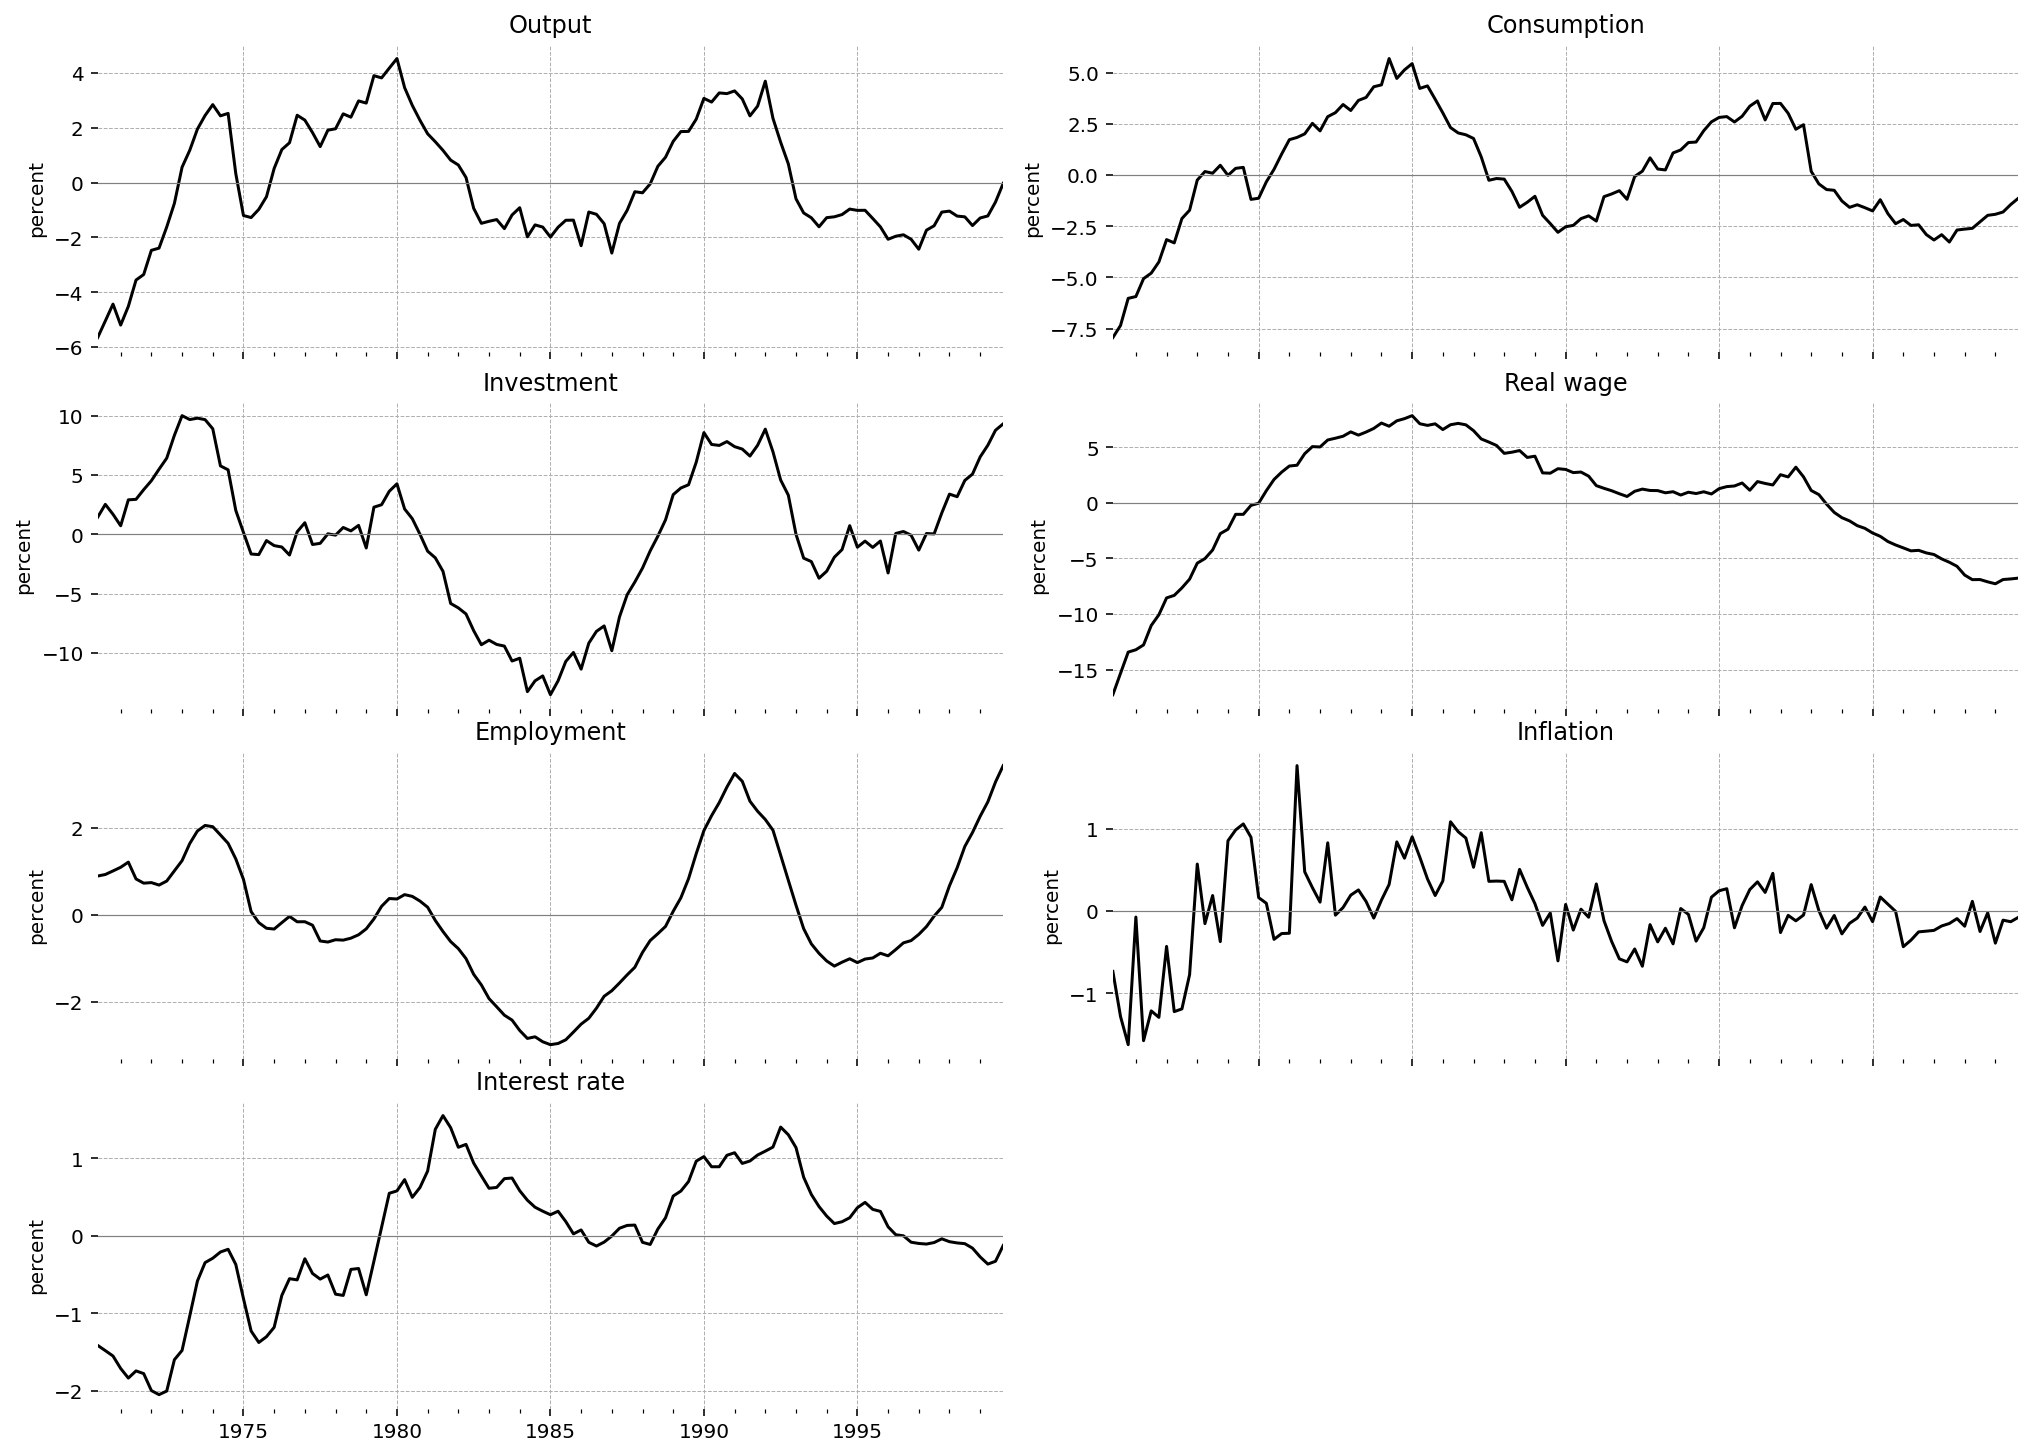

In [7]:
titles = {
    "Y": "Output",
    "C": "Consumption",
    "I": "Investment",
    "W": "Real wage",
    "N": "Employment",
    "pi": "Inflation",
    "R": "Interest rate",
}
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
for ax, (name, title) in zip(axes.flat, titles.items(), strict=False):
    observed[name].plot(ax=ax, color="black")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set(title=title, ylabel="percent")
axes.flat[-1].remove()
plt.show()

## The state-space model

`statespace_from_gcn` builds the model as a PyMC state-space model, whose likelihood is computed by the Kalman filter. Each of the seven series observes the log deviation of one model variable. The paper fixes the discount factor, the depreciation rate, the capital share, the wage markup and the steady-state shares of consumption and government spending in output, and estimates the other 32 parameters. Every parameter that `configure` does not hold constant needs a prior in the PyMC model.

In [8]:
ss_mod = ge.statespace_from_gcn(get_example_gcn("Smets_Wouters_2003"), verbose=False)
ss_mod.configure(
    observed_states=list(observed.columns),
    constant_params=["beta", "tau", "alpha", "lambda_w", "omega", "c_y", "g_y"],
    verbose=True,
    solver="scan_cycle_reduction",
    use_adjoint_gradients=True,
)

                Model Requirements                 
                                                   
  Variable       Shape   Constraints   Dimensions  
 ───────────────────────────────────────────────── 
  gamma_p        ()                          None  
  gamma_w        ()                          None  
  h              ()                          None  
  phi            ()                          None  
  psi            ()                          None  
  r_Delta_pi     ()                          None  
  r_Delta_y      ()                          None  
  r_Y            ()                          None  
  r_pi           ()                          None  
  rho            ()                          None  
  rho_G          ()                          None  
  rho_I          ()                          None  
  rho_L          ()                          None  
  rho_a          ()                          None  
  rho_b          ()                          None  
  rho_pi_bar     ()                          None  
  sigma_c        ()                          None  
  sigma_l        ()                          None  
  varphi         ()                          None  
  xi_e           ()                          None  
  xi_p           ()                          None  
  xi_w           ()                          None  
  sigma_eta_G    ()      Positive            None  
  sigma_eta_I    ()      Positive            None  
  sigma_eta_L    ()      Positive            None  
  sigma_eta_Q    ()      Positive            None  
  sigma_eta_R    ()      Positive            None  
  sigma_eta_a    ()      Positive            None  
  sigma_eta_b    ()      Positive            None  
  sigma_eta_p    ()      Positive            None  
  sigma_eta_pi   ()      Positive            None  
  sigma_eta_w    ()      Positive            None  
                                                   
These parameters should be assigned priors inside a
        PyMC model block before calling the        
          build_statespace_graph method.           

## Priors

The priors are those of Table 1 of {cite:t}`smets-wouters-2003`. The Calvo, habit, indexation and persistence parameters, which lie between 0 and 1, have Beta priors, and the other structural parameters Normal priors, each given by its mean and standard deviation.

The standard deviation $\sigma$ of each shock has an inverted Gamma prior with 2 degrees of freedom, the inverse gamma distribution for standard deviations of Dynare. It is the distribution of $\sigma$ when $\sigma^2$ is inverse gamma with shape $\nu / 2$ and scale $\nu s^2 / 2$, for $\nu = 2$ degrees of freedom, and its mean is $s \sqrt{\nu / 2} \, \Gamma((\nu - 1) / 2) / \Gamma(\nu / 2) = s \sqrt{\pi}$. The table gives the mean.

These priors are on the scale of the paper's estimation, where every shock enters its log-linear equation with a unit coefficient. The shocks of the GCN file are in economic units, so each of their standard deviations is the paper's divided by the coefficient from the table in the section on the size of the shocks below. Two of the coefficients depend on the steady state and on the parameters being estimated: the government spending shock is scaled by the steady-state share of government spending in output, and the markup shocks by the slopes $\kappa_p$ and $\kappa_w$ of the price and wage equations. The PyMC model draws the paper's standard deviations and computes those of the file as deterministic functions of the draws.

In [9]:
def DoFInverseGamma(name, mean, degrees_of_freedom=2, **kwargs):
    """
    Inverted Gamma prior on a standard deviation, parametrized by its mean and degrees of freedom.

    The square of the standard deviation is inverse gamma with shape ``degrees_of_freedom / 2``, as in Dynare. Other
    keyword arguments go to :class:`pymc.CustomDist`.
    """

    def dist(mean, degrees_of_freedom, size):
        nu = degrees_of_freedom
        scale = mean * pt.exp(pt.gammaln(nu / 2) - pt.gammaln((nu - 1) / 2)) / pt.sqrt(nu / 2)
        return pt.sqrt(pm.InverseGamma.dist(alpha=nu / 2, beta=nu * scale**2 / 2, size=size))

    kwargs.setdefault("transform", pm.distributions.transforms.log)
    return pm.CustomDist(name, mean, degrees_of_freedom, dist=dist, **kwargs)

In [10]:
beta = params["beta"]
lambda_w = params["lambda_w"]
government_share = params["g_y"]

with pm.Model(coords=ss_mod.coords) as pymc_model:
    rho_a = pm.Beta("rho_a", mu=0.85, sigma=0.10, initval=0.823)
    rho_pi_bar = pm.Beta("rho_pi_bar", mu=0.85, sigma=0.10, initval=0.924)
    rho_b = pm.Beta("rho_b", mu=0.85, sigma=0.10, initval=0.855)
    rho_G = pm.Beta("rho_G", mu=0.85, sigma=0.10, initval=0.949)
    rho_L = pm.Beta("rho_L", mu=0.85, sigma=0.10, initval=0.889)
    rho_I = pm.Beta("rho_I", mu=0.85, sigma=0.10, initval=0.927)

    varphi = pm.Normal("varphi", mu=4.0, sigma=1.5, initval=6.771)
    sigma_c = pm.Normal("sigma_c", mu=1.0, sigma=0.375, initval=1.353)
    h = pm.Beta("h", mu=0.7, sigma=0.1, initval=0.573)
    sigma_l = pm.Normal("sigma_l", mu=2.0, sigma=0.75, initval=2.4)
    phi = pm.Normal("phi", mu=1.45, sigma=0.25, initval=1.408)
    xi_e = pm.Beta("xi_e", mu=0.5, sigma=0.15, initval=0.599)
    psi = pm.Normal("psi", mu=0.2, sigma=0.075, initval=0.169)
    xi_w = pm.Beta("xi_w", mu=0.75, sigma=0.05, initval=0.737)
    xi_p = pm.Beta("xi_p", mu=0.75, sigma=0.05, initval=0.908)
    gamma_w = pm.Beta("gamma_w", mu=0.75, sigma=0.15, initval=0.763)
    gamma_p = pm.Beta("gamma_p", mu=0.75, sigma=0.15, initval=0.469)

    r_pi = pm.Normal("r_pi", mu=1.7, sigma=0.1, initval=1.684)
    r_Delta_pi = pm.Normal("r_Delta_pi", mu=0.3, sigma=0.1, initval=0.140)
    rho = pm.Beta("rho", mu=0.8, sigma=0.1, initval=0.961)
    r_Y = pm.Normal("r_Y", mu=0.125, sigma=0.05, initval=0.099)
    r_Delta_y = pm.Normal("r_Delta_y", mu=0.0625, sigma=0.05, initval=0.159)

    # Shocks that enter their log-linear equation with a unit coefficient in both the paper and the GCN file.
    sigma_eta_a = DoFInverseGamma("sigma_eta_a", mean=0.4, initval=0.598)
    sigma_eta_pi = DoFInverseGamma("sigma_eta_pi", mean=0.02, initval=0.017)
    sigma_eta_L = DoFInverseGamma("sigma_eta_L", mean=1.0, initval=3.520)
    sigma_eta_I = DoFInverseGamma("sigma_eta_I", mean=0.1, initval=0.085)
    sigma_eta_R = DoFInverseGamma("sigma_eta_R", mean=0.1, initval=0.081)

    # Shocks whose prior is on the scale of the paper's estimation, divided by their coefficient in the log-linear
    # model.
    estimation_sd_b = DoFInverseGamma("estimation_sd_b", mean=0.2, initval=0.336)
    estimation_sd_G = DoFInverseGamma("estimation_sd_G", mean=0.3, initval=0.325)
    estimation_sd_Q = DoFInverseGamma("estimation_sd_Q", mean=0.4, initval=0.604)
    estimation_sd_p = DoFInverseGamma("estimation_sd_p", mean=0.15, initval=0.160)
    estimation_sd_w = DoFInverseGamma("estimation_sd_w", mean=0.25, initval=0.289)

    kappa_p = (1 - beta * xi_p) * (1 - xi_p) / ((1 + beta * gamma_p) * xi_p)
    kappa_w = (1 - beta * xi_w) * (1 - xi_w) / ((1 + beta) * (1 + (1 + lambda_w) * sigma_l / lambda_w) * xi_w)

    sigma_eta_b = pm.Deterministic("sigma_eta_b", estimation_sd_b / (1 - rho_b))
    sigma_eta_G = pm.Deterministic("sigma_eta_G", estimation_sd_G / government_share)
    sigma_eta_Q = pm.Deterministic("sigma_eta_Q", estimation_sd_Q * (1 + beta))
    sigma_eta_p = pm.Deterministic("sigma_eta_p", estimation_sd_p / kappa_p)
    sigma_eta_w = pm.Deterministic("sigma_eta_w", estimation_sd_w / kappa_w)

    n_presample = observed.index.get_loc("1979Q4") + 1
    ss_mod.build_statespace_graph(
        observed.to_timestamp(), add_norm_check=False, loglikelihood_burn=n_presample, add_bk_check=True
    )

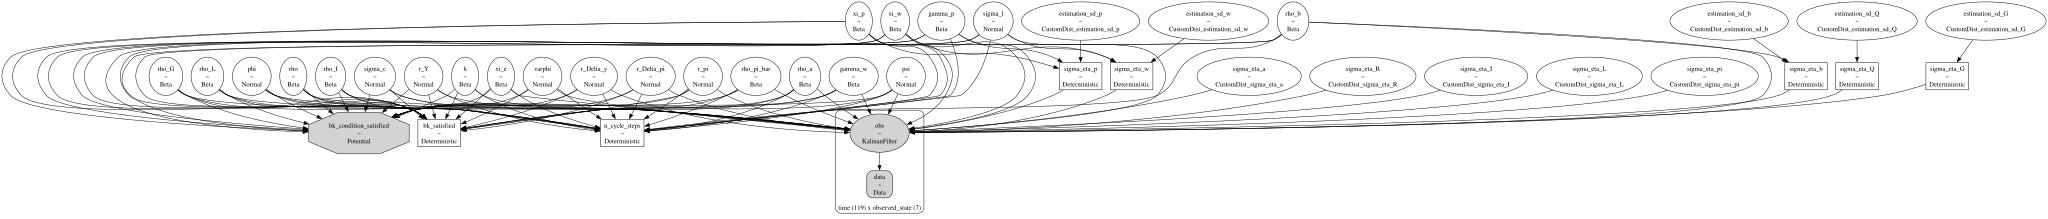

In [11]:
pymc_model.to_graphviz()

Draws from the prior are needed later to compare it with the posterior. Only the estimated parameters are drawn, because the observations of a parameter draw at which the model has no stable solution cannot be simulated.

In [12]:
random_seed = sum(map(ord, "Smets and Wouters (2003)"))
estimated_parameters = [rv.name for rv in pymc_model.free_RVs]

with pymc_model:
    prior = pm.sample_prior_predictive(draws=2000, var_names=estimated_parameters, random_seed=random_seed)

/var/folders/7b/rzxy96cj0w751_6td3g2yss00000gn/T/ipykernel_98674/4091053173.py:5: UserWarning: The effect of Potentials on other parameters is ignored during prior predictive sampling. This is likely to lead to invalid or biased predictive samples.
  prior = pm.sample_prior_predictive(draws=2000, var_names=estimated_parameters, random_seed=random_seed)
Sampling: [estimation_sd_G, estimation_sd_Q, estimation_sd_b, estimation_sd_p, estimation_sd_w, gamma_p, gamma_w, h, phi, psi, r_Delta_pi, r_Delta_y, r_Y, r_pi, rho, rho_G, rho_I, rho_L, rho_a, rho_b, rho_pi_bar, sigma_c, sigma_eta_I, sigma_eta_L, sigma_eta_R, sigma_eta_a, sigma_eta_pi, sigma_l, varphi, xi_e, xi_p, xi_w]


## Sampling

The posterior is sampled with NUTS through nutpie, with six chains of 4,000 draws each and a target acceptance rate of 0.95, above nutpie's default of 0.8. By default nutpie adds uniform jitter on $(-1, 1)$ in the unconstrained space to every starting value, which can move the monetary policy rule out of the region where the model has a unique stable solution. With the jitter turned off, every chain starts at the posterior modes of Table 1. The `add_bk_check=True` argument of `build_statespace_graph` adds a potential that gives zero density to parameters at which the model fails the Blanchard-Kahn conditions, so every posterior draw has a unique stable solution. This is the most expensive cell in the notebook.

:::{note}
4000 draws is insane. In general, as few as 250 across multiple chains will get the job done. This choice was made because testing showed that the posterior had multiple modes. The huge number of draws helps get coverage of both. A better solution would be to adjust the priors to select the more economically meaningful mode. In this notebook, however, the original priors from the paper are used.
:::

In [13]:
with pymc_model:
    idata = pm.sample(
        nuts_sampler="nutpie",
        chains=6,
        cores=6,
        tune=1000,
        draws=4000,
        target_accept=0.95,
        random_seed=random_seed,
        compile_kwargs={"jitter_rvs": set()},
    )

NUTS[nutpie]: [rho_a, rho_pi_bar, rho_b, rho_G, rho_L, rho_I, varphi, sigma_c, h, sigma_l, phi, xi_e, psi, xi_w, xi_p, gamma_w, gamma_p, r_pi, r_Delta_pi, rho, r_Y, r_Delta_y, sigma_eta_a, sigma_eta_pi, sigma_eta_L, sigma_eta_I, sigma_eta_R, estimation_sd_b, estimation_sd_G, estimation_sd_Q, estimation_sd_p, estimation_sd_w]


Output()

## Sampling diagnostics

{cite:t}`smets-wouters-2003` sample with random-walk Metropolis-Hastings and report no convergence diagnostics. The standard checks for NUTS are the number of divergent transitions, the effective sample size and $\hat{R}$ of every parameter, trace plots, and the energy plot, whose marginal and transition energy distributions should overlap.

In [14]:
az.summary(idata, var_names=estimated_parameters, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
rho_a,0.962,0.022,0.921,0.990,23104.493,16112.413,1.000,0.000,0.000
rho_pi_bar,0.852,0.093,0.682,0.972,16517.507,8705.074,1.000,0.001,0.001
rho_b,0.849,0.036,0.788,0.902,9392.289,11650.227,1.001,0.000,0.000
rho_G,0.944,0.024,0.902,0.980,22675.434,12351.144,1.000,0.000,0.000
rho_L,0.946,0.026,0.900,0.980,13609.769,15943.172,1.000,0.000,0.000
rho_I,0.945,0.025,0.901,0.978,13537.881,13188.555,1.000,0.000,0.000
varphi,7.008,1.131,5.260,8.862,31730.087,18330.077,1.001,0.006,0.008
sigma_c,1.493,0.278,1.066,1.945,17451.295,16148.061,1.000,0.002,0.002
h,0.602,0.066,0.493,0.705,10569.002,12957.424,1.000,0.001,0.000
sigma_l,2.419,0.610,1.482,3.435,13364.796,15793.613,1.001,0.005,0.004


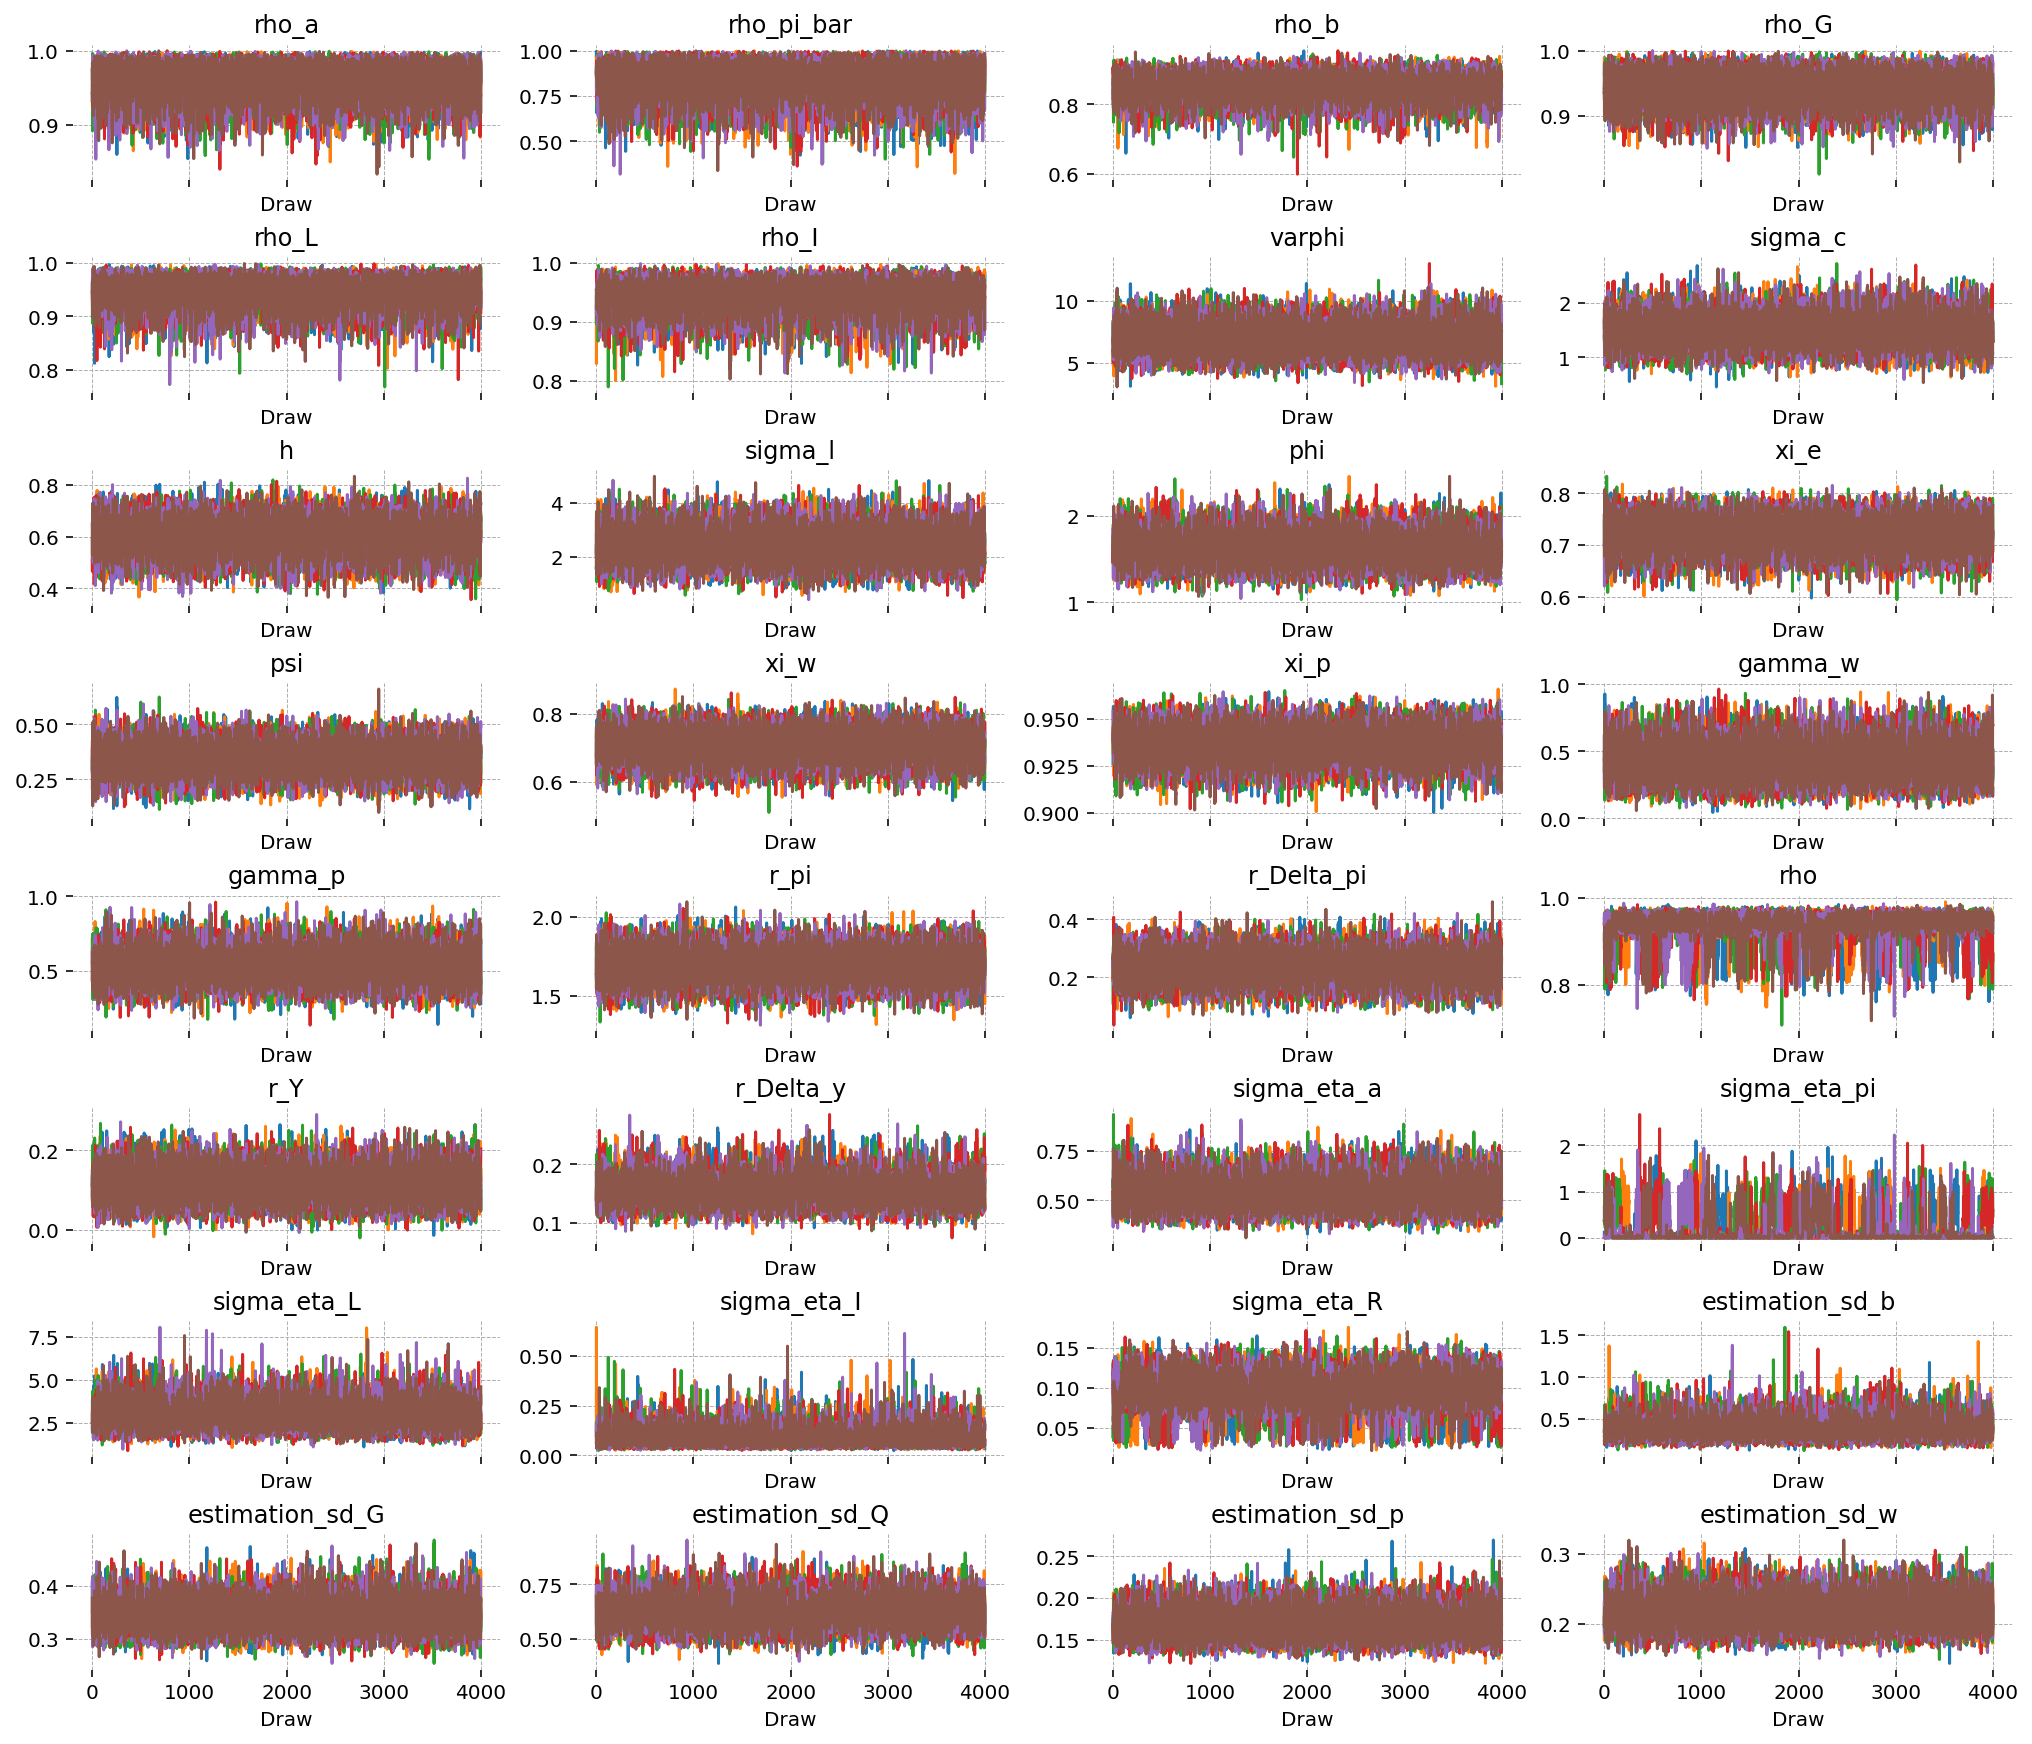

In [15]:
az.plot_trace(idata, var_names=estimated_parameters, figure_kwargs={"figsize": (14, 12)});

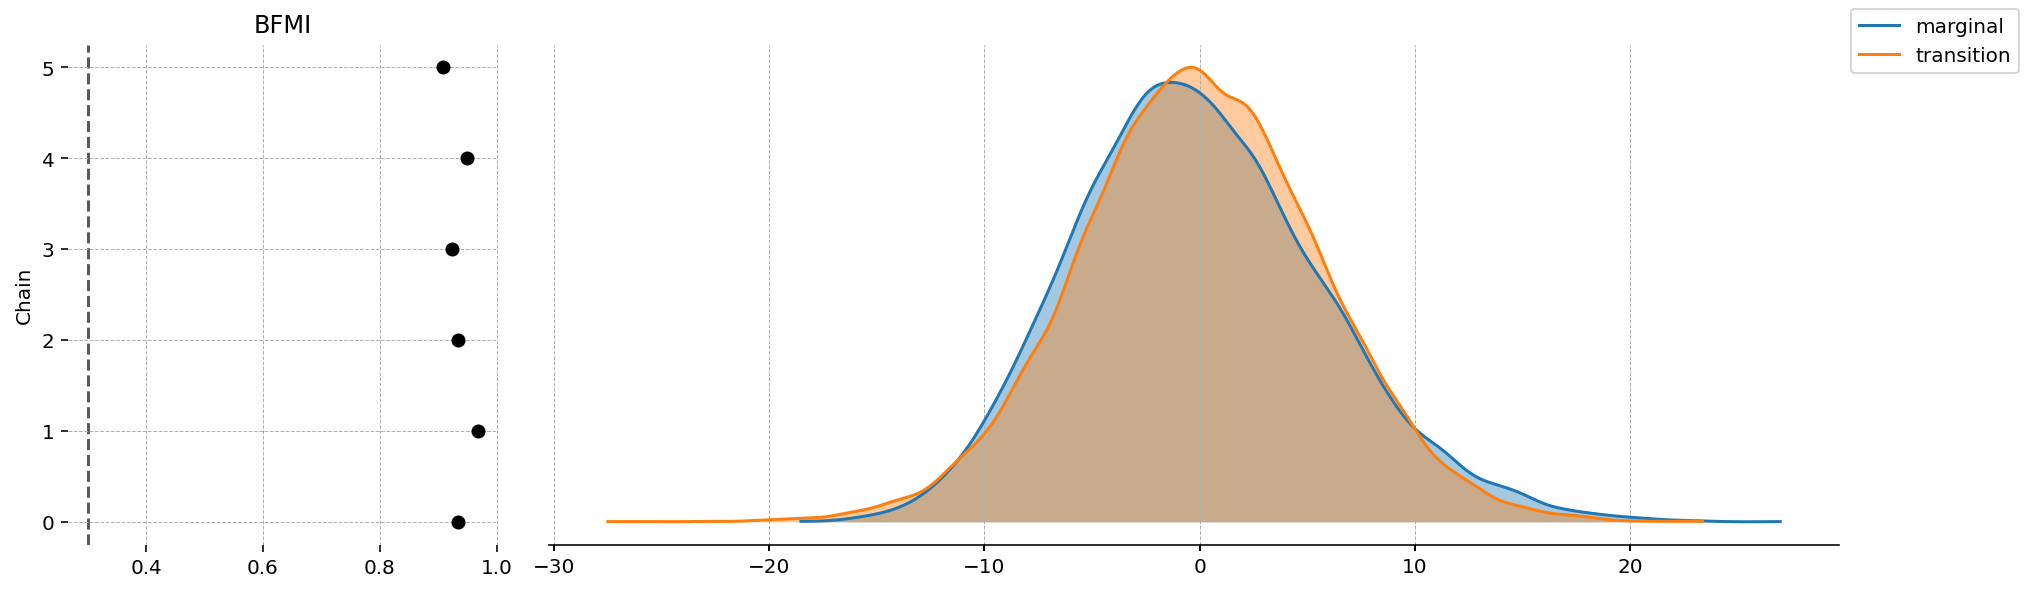

In [16]:
az.plot_energy(idata, figure_kwargs={"figsize": (14, 4)});

No transition diverges, $\hat{R}$ is at most 1.004, and the smallest bulk effective sample size is 960. The parameters that mix slowest are the standard deviation of the inflation objective shock, the interest-rate smoothing coefficient $\rho$ and the standard deviation of the interest rate shock, because the posterior of the first has two modes. In 76% of the draws the standard deviation of the inflation objective shock has a median of 0.014. In the other 24% its median is 0.55, with a 90% interval of 0.15 to 1.1. All six chains move between the two modes, with 20% to 30% of each chain's draws in the high mode. In the high mode the rule smooths the interest rate less, with a median $\rho$ of 0.90 against 0.95, and the interest rate shock is smaller, with a median standard deviation of 0.068 against 0.100.

## Prior and posterior

Figures 1A to 1C of {cite:t}`smets-wouters-2003` show histograms of the prior and posterior draws of every estimated parameter. The figures below follow their panel order and axis ranges, with draws outside a panel's range counted in its edge bin, as in the paper. The shock standard deviations are on the scale of the paper's estimation, so they are comparable with Table 1.

The dashed red curve in each panel is the normal approximation that the paper also plots, centered on the posterior mode of Table 1 with the standard error from the Hessian at the mode. The text compares the posterior means of `az.summary` above with the means of the paper's Metropolis-Hastings draws, which Table 1 also reports.

In [17]:
idata["prior"] = prior["prior"]

# The initial values of the PyMC model are the posterior modes of Table 1.
table_1_mode = {rv.name: float(pymc_model.rvs_to_initial_values[rv]) for rv in pymc_model.free_RVs}

# Standard errors of Table 1, from the Hessian at the posterior mode.
table_1_hessian_se = {
    "rho_a": 0.065,
    "rho_pi_bar": 0.088,
    "rho_b": 0.035,
    "rho_G": 0.029,
    "rho_L": 0.052,
    "rho_I": 0.022,
    "varphi": 1.026,
    "sigma_c": 0.282,
    "h": 0.076,
    "sigma_l": 0.589,
    "phi": 0.166,
    "xi_e": 0.050,
    "psi": 0.075,
    "xi_w": 0.049,
    "xi_p": 0.011,
    "gamma_w": 0.188,
    "gamma_p": 0.103,
    "r_pi": 0.109,
    "r_Delta_pi": 0.053,
    "rho": 0.014,
    "r_Y": 0.041,
    "r_Delta_y": 0.027,
    "sigma_eta_a": 0.113,
    "sigma_eta_pi": 0.008,
    "sigma_eta_L": 1.027,
    "sigma_eta_I": 0.030,
    "sigma_eta_R": 0.023,
    "estimation_sd_b": 0.096,
    "estimation_sd_G": 0.026,
    "estimation_sd_Q": 0.063,
    "estimation_sd_p": 0.016,
    "estimation_sd_w": 0.027,
}


def plot_parameter_histograms(idata, blocks, title, n_bins=40):
    fig = plt.figure(figsize=(12, 13), layout="constrained")
    for subfig, panels in zip(fig.subfigures(2, 1, hspace=0.04), blocks, strict=True):
        axes = subfig.subplots(3, 2)
        for ax, (name, label, (lower, upper)) in zip(axes.flat, panels, strict=False):
            edges = np.linspace(lower, upper, n_bins + 1)
            centers = (edges[:-1] + edges[1:]) / 2
            bin_width = edges[1] - edges[0]
            for group, color, bar_width in [("prior", "0.75", bin_width), ("posterior", "black", bin_width / 2)]:
                draws = np.clip(idata[group][name].to_numpy().ravel(), lower, upper)
                density, _ = np.histogram(draws, bins=edges, density=True)
                ax.bar(centers, density, width=bar_width, color=color, label=group)

            normal_approximation = pz.Normal(mu=table_1_mode[name], sigma=table_1_hessian_se[name])
            grid = normal_approximation.xvals("restricted")
            ax.plot(
                grid,
                normal_approximation.pdf(grid),
                color="C3",
                linewidth=2.5,
                linestyle="--",
                label="SW03 normal approximation",
            )
            ax.set(title=label, xlim=(lower, upper))
        for ax in axes.flat[len(panels) :]:
            ax.remove()
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside upper right", frameon=False)
    fig.suptitle(title)
    plt.show()

### Standard deviations of the shocks

Figure 1A shows the standard deviations of the ten shocks. Five posterior means are within 5% of the means of the paper's Metropolis-Hastings draws: those of the preference, government spending, interest rate, equity premium and price markup shocks. The productivity, labor-supply, investment and wage markup shocks are smaller than in the paper, with means of 0.53, 3.0, 0.089 and 0.22 against 0.64, 3.8, 0.11 and 0.30.

The inflation objective shock has two posterior modes. In 76% of the draws its standard deviation is close to the paper's estimate, with a median of 0.014 and a 90% interval of 0.0065 to 0.049, against a posterior median of 0.025 and an interval of 0.012 to 0.085 in the paper. Most of the other 24% lie between 0.15 and 1.1, so they fall in the edge bin of the paper's range and form the spike at 0.1. The paper finds that this is the one shock whose standard deviation is not significantly different from zero. The low mode agrees with that, while in the high mode the data assign the shock a large role.

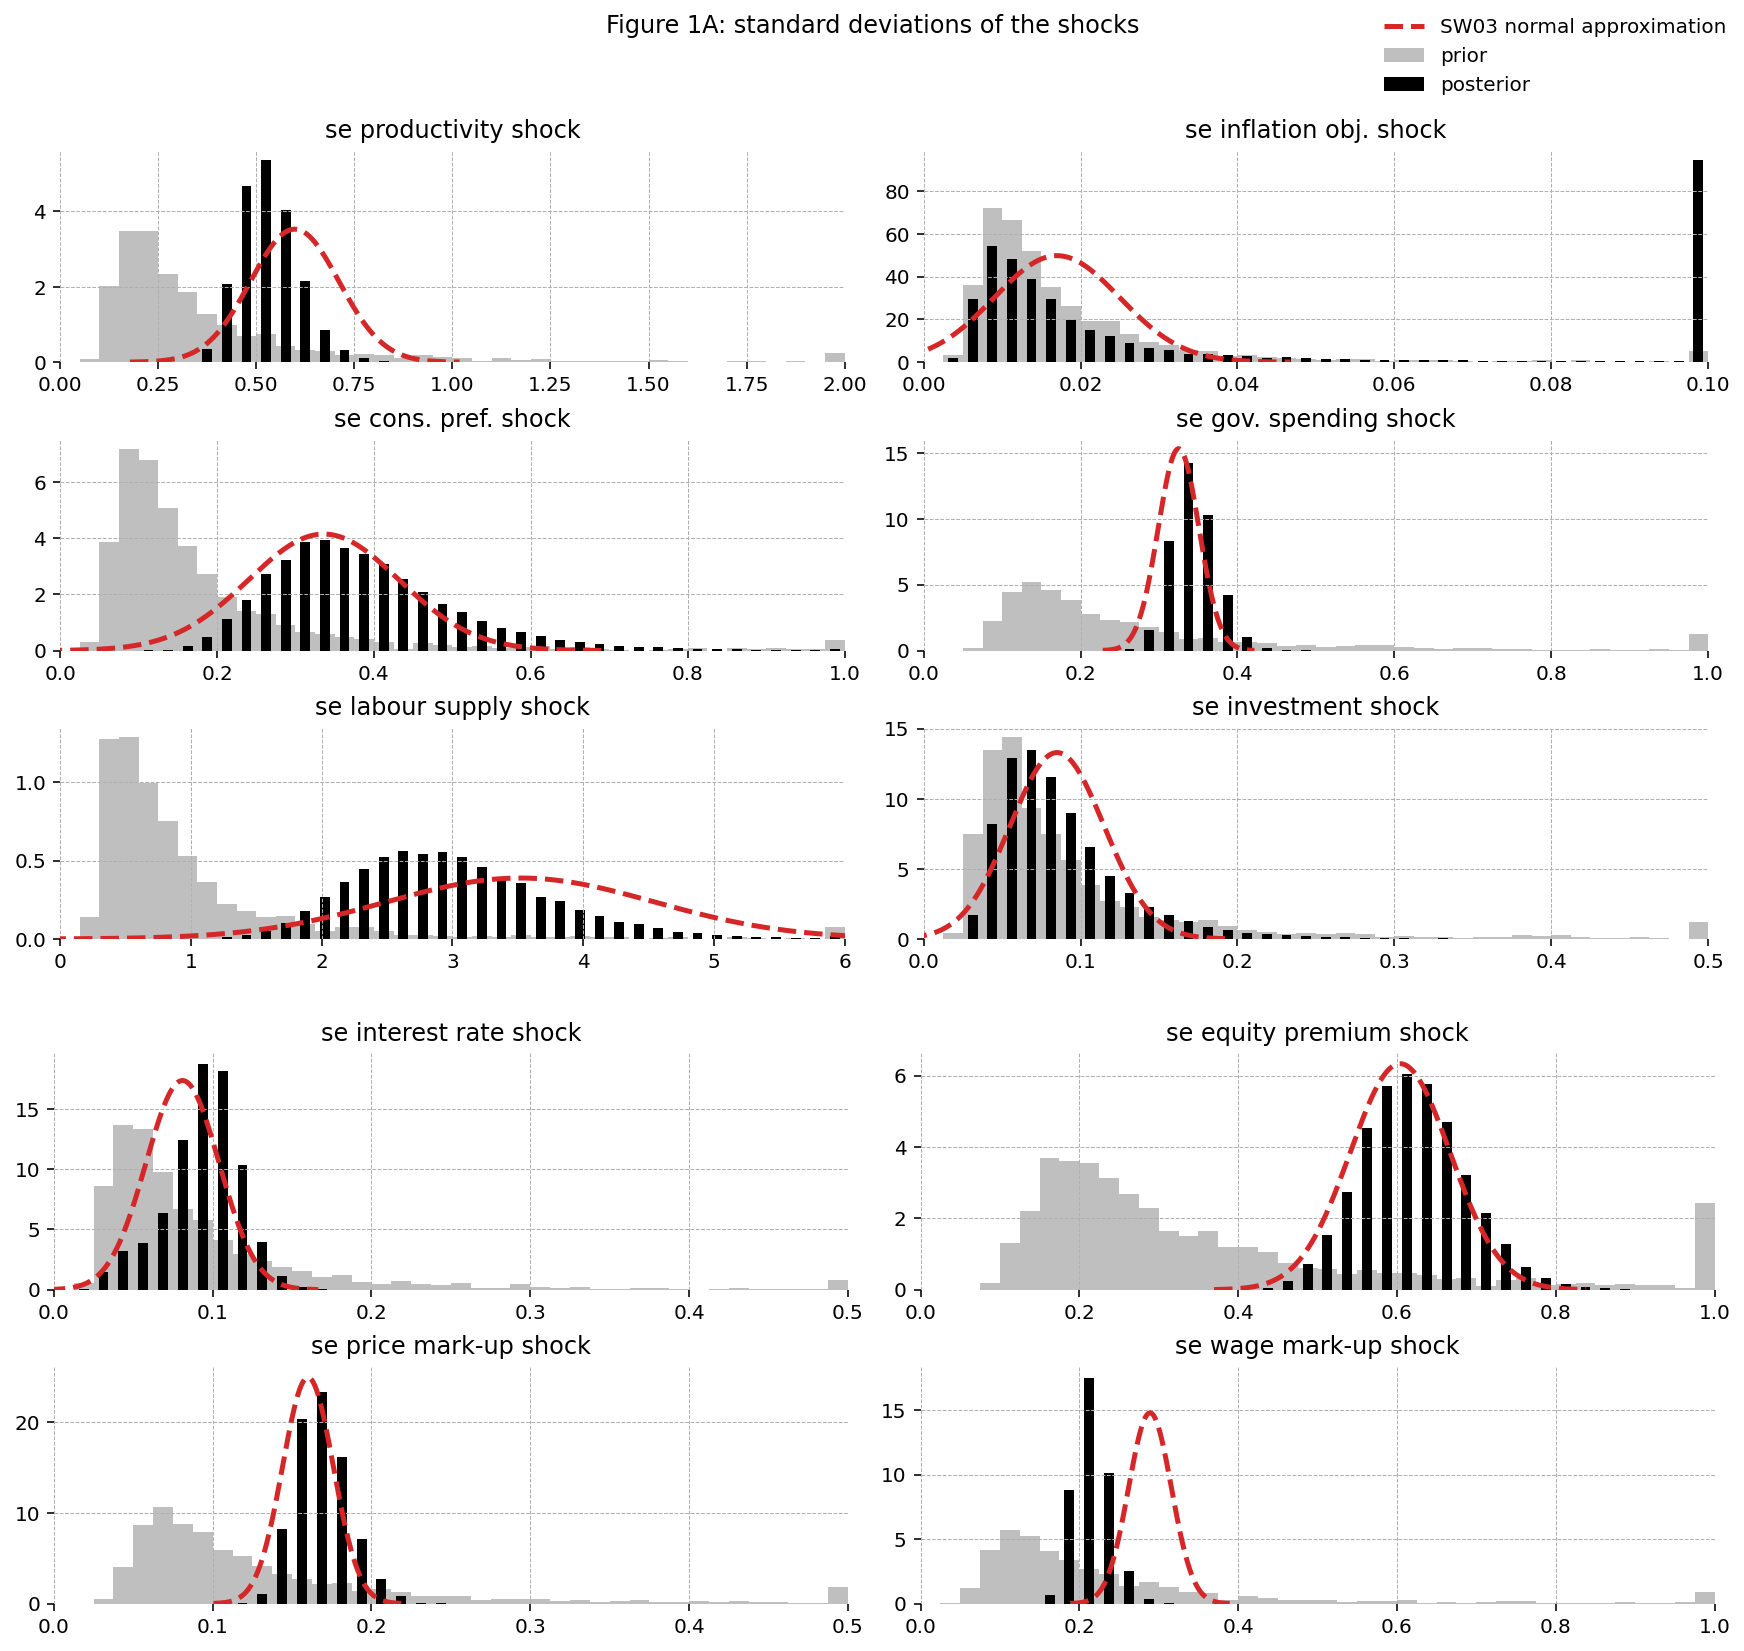

In [18]:
plot_parameter_histograms(
    idata,
    blocks=(
        [
            ("sigma_eta_a", "se productivity shock", (0, 2)),
            ("sigma_eta_pi", "se inflation obj. shock", (0, 0.1)),
            ("estimation_sd_b", "se cons. pref. shock", (0, 1)),
            ("estimation_sd_G", "se gov. spending shock", (0, 1)),
            ("sigma_eta_L", "se labour supply shock", (0, 6)),
            ("sigma_eta_I", "se investment shock", (0, 0.5)),
        ],
        [
            ("sigma_eta_R", "se interest rate shock", (0, 0.5)),
            ("estimation_sd_Q", "se equity premium shock", (0, 1)),
            ("estimation_sd_p", "se price mark-up shock", (0, 0.5)),
            ("estimation_sd_w", "se wage mark-up shock", (0, 1)),
        ],
    ),
    title="Figure 1A: standard deviations of the shocks",
)

### Persistence, preferences and technology

The first block of Figure 1B shows the persistence of the six AR(1) shocks. The productivity shock is the most persistent, with a posterior mean of 0.96 where the paper's is 0.81. The labor-supply and investment shocks are also more persistent than in the paper, at 0.95 and 0.94 against 0.88 and 0.91, while the preference and government spending shocks agree with it, at 0.85 and 0.94. The persistence of the inflation objective shock is the one parameter of the figure that the data do not inform, because its posterior is close to its prior.

The second block shows the preference and technology parameters. The investment adjustment cost, habit and the curvature of the disutility of labor agree with the paper, at 7.0, 0.60 and 2.4 against 7.0, 0.59 and 2.5. The curvature of utility in consumption, the fixed cost and the Calvo parameter for employment have higher means than in the paper. They are 1.49, 1.62 and 0.72, against 1.39, 1.42 and 0.60.

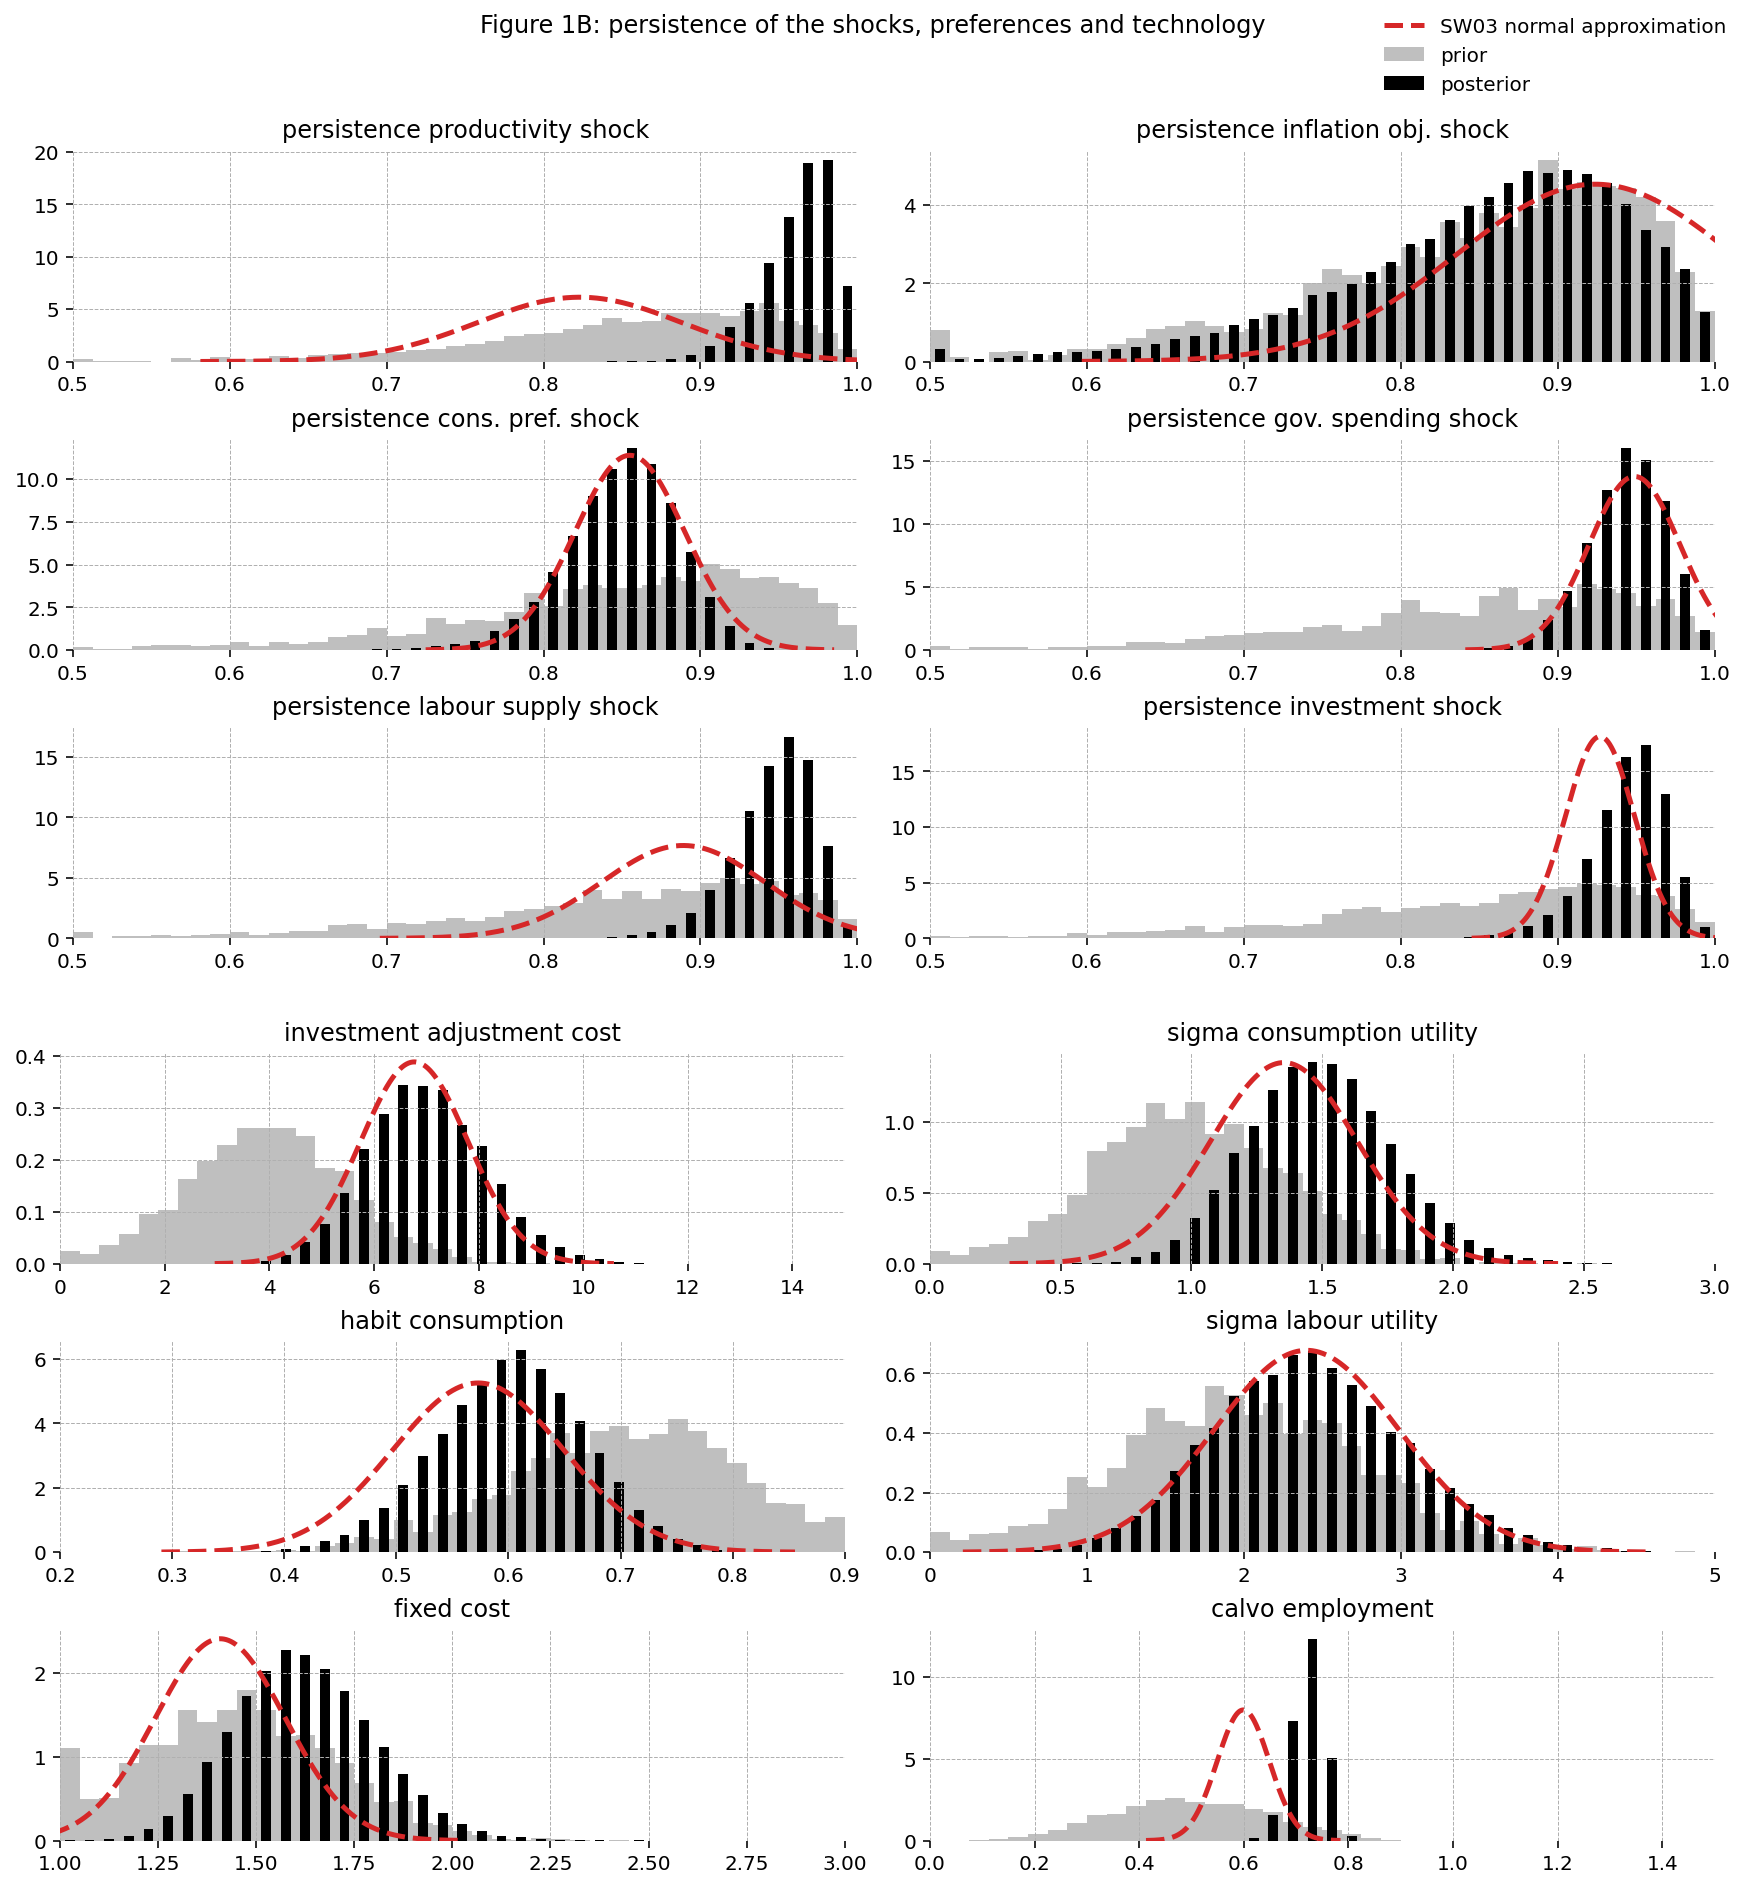

In [19]:
plot_parameter_histograms(
    idata,
    blocks=(
        [
            ("rho_a", "persistence productivity shock", (0.5, 1)),
            ("rho_pi_bar", "persistence inflation obj. shock", (0.5, 1)),
            ("rho_b", "persistence cons. pref. shock", (0.5, 1)),
            ("rho_G", "persistence gov. spending shock", (0.5, 1)),
            ("rho_L", "persistence labour supply shock", (0.5, 1)),
            ("rho_I", "persistence investment shock", (0.5, 1)),
        ],
        [
            ("varphi", "investment adjustment cost", (0, 15)),
            ("sigma_c", "sigma consumption utility", (0, 3)),
            ("h", "habit consumption", (0.2, 0.9)),
            ("sigma_l", "sigma labour utility", (0, 5)),
            ("phi", "fixed cost", (1, 3)),
            ("xi_e", "calvo employment", (0, 1.5)),
        ],
    ),
    title="Figure 1B: persistence of the shocks, preferences and technology",
)

### Nominal rigidities and monetary policy

The first block of Figure 1C shows the nominal rigidities. Prices are stickier than wages, as in the paper. The mean of the Calvo parameter for prices is 0.94 against 0.91, and for wages 0.71 against 0.74. Wage indexation is weaker than in the paper, at 0.43 against 0.73, and its posterior lies below most of the prior's mass. Price indexation is 0.53, against 0.48. The cost of capital utilization is 0.34, against the paper's 0.20.

The second block shows the policy rule. As in the paper, the posterior of the response to inflation matches its tight prior. The responses to the output gap and to its change agree with the paper, at 0.11 and 0.16 against 0.10 and 0.16. The rule responds more to the change in inflation, at 0.23 against 0.15, and smooths the interest rate slightly less, at 0.94 against 0.96. The posterior of the smoothing coefficient has a long left tail, which comes from the high mode of the inflation objective shock.

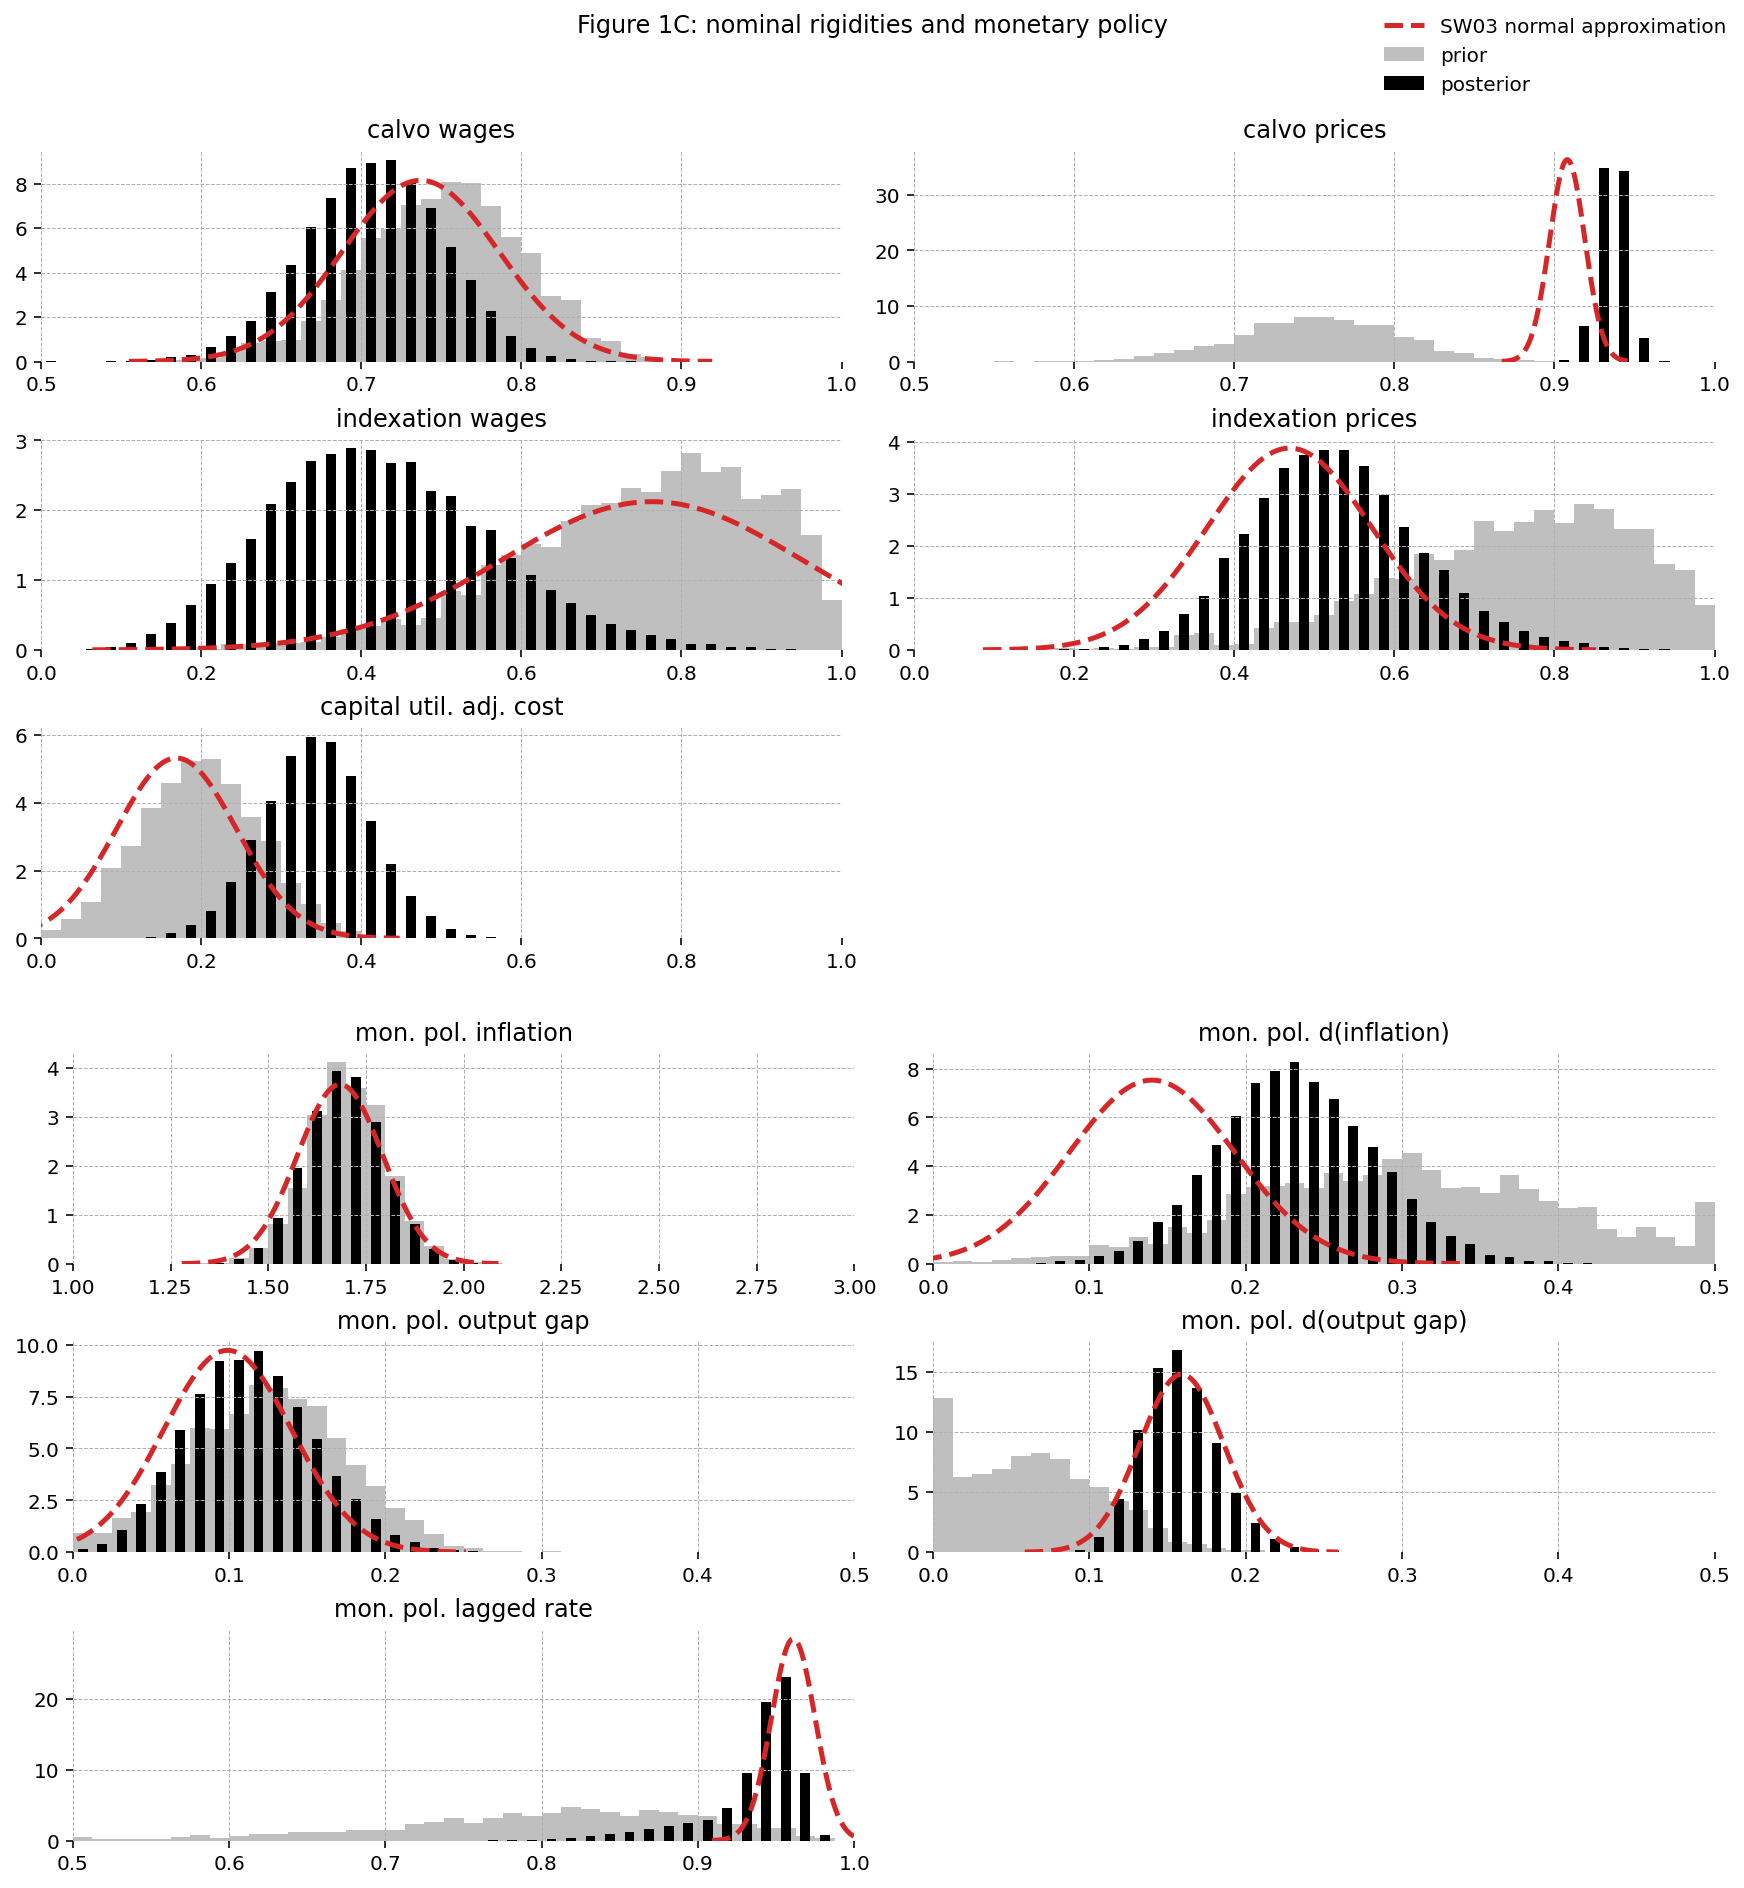

In [20]:
plot_parameter_histograms(
    idata,
    blocks=(
        [
            ("xi_w", "calvo wages", (0.5, 1)),
            ("xi_p", "calvo prices", (0.5, 1)),
            ("gamma_w", "indexation wages", (0, 1)),
            ("gamma_p", "indexation prices", (0, 1)),
            ("psi", "capital util. adj. cost", (0, 1)),
        ],
        [
            ("r_pi", "mon. pol. inflation", (1, 3)),
            ("r_Delta_pi", "mon. pol. d(inflation)", (0, 0.5)),
            ("r_Y", "mon. pol. output gap", (0, 0.5)),
            ("r_Delta_y", "mon. pol. d(output gap)", (0, 0.5)),
            ("rho", "mon. pol. lagged rate", (0.5, 1)),
        ],
    ),
    title="Figure 1C: nominal rigidities and monetary policy",
)

## The size of the shocks

Table 1 of {cite:t}`smets-wouters-2003` reports the posterior mode of each shock's standard deviation, in percent. A note to the table says that the preference, government spending, investment and markup shocks are normalized differently in estimation than in the paper's equations. The code that produced the estimates shows the normalization: each shock enters its log-linear equation with a unit coefficient. The GCN file writes the shocks in economic units instead, so their standard deviations are the table's divided by the coefficient with which each enters the log-linear model:

| Shock | Enters in the code as | Standard deviation in the file |
|---|---|---|
| Preference $\eta^b$ | $-(1 - \rho_b) \hat{\varepsilon}^b_t$ in the consumption Euler equation | $\sigma^b / (1 - \rho_b)$ |
| Government spending $\eta^G$ | $g_y \hat{\varepsilon}^G_t$ in the resource constraint | $\sigma^G / g_y$ |
| Equity premium $\eta^Q$ | $\eta^Q_t / (1 + \beta)$ in the investment equation | $(1 + \beta) \sigma^Q$ |
| Price markup $\eta^p$ | $\kappa_p \eta^p_t$ in the Phillips curve | $\sigma^p / \kappa_p$ |
| Wage markup $\eta^w$ | $\kappa_w \eta^w_t$ in the wage equation | $\sigma^w / \kappa_w$ |

Here $\kappa_p$ and $\kappa_w$ are the slopes of the price and wage equations (32) and (33):

$$
\kappa_p = \frac{(1 - \beta \xi_p)(1 - \xi_p)}{(1 + \beta \gamma_p) \xi_p}, \qquad \kappa_w = \frac{(1 - \beta \xi_w)(1 - \xi_w)}{(1 + \beta) \left( 1 + \frac{(1 + \lambda_w) \sigma_l}{\lambda_w} \right) \xi_w}.
$$

The productivity, labor-supply, investment, interest-rate and inflation-objective shocks enter with a unit coefficient in both, so their standard deviations carry over. The solution is linear, so with shocks sized in percent the log deviations read as percent deviations from the steady state.

In [21]:
table_1_sd = {
    "eta_a": 0.598,
    "eta_pi": 0.017,
    "eta_b": 0.336,
    "eta_G": 0.325,
    "eta_L": 3.520,
    "eta_I": 0.085,
    "eta_R": 0.081,
    "eta_Q": 0.604,
    "eta_p": 0.160,
    "eta_w": 0.289,
}

params = mod.parameters()
beta = params["beta"]
kappa_p = (1 - beta * params["xi_p"]) * (1 - params["xi_p"]) / ((1 + beta * params["gamma_p"]) * params["xi_p"])
kappa_w = (
    (1 - beta * params["xi_w"])
    * (1 - params["xi_w"])
    / ((1 + beta) * (1 + (1 + params["lambda_w"]) * params["sigma_l"] / params["lambda_w"]) * params["xi_w"])
)
government_share = ss["G_ss"] / ss["Y_ss"]

shock_sd = table_1_sd | {
    "eta_b": table_1_sd["eta_b"] / (1 - params["rho_b"]),
    "eta_G": table_1_sd["eta_G"] / government_share,
    "eta_Q": table_1_sd["eta_Q"] * (1 + beta),
    "eta_p": table_1_sd["eta_p"] / kappa_p,
    "eta_w": table_1_sd["eta_w"] / kappa_w,
}

pd.DataFrame({"Table 1": table_1_sd, "GCN file": shock_sd}).round(3)

,Table 1,GCN file
eta_a,0.598,0.598
eta_pi,0.017,0.017
eta_b,0.336,2.317
eta_G,0.325,1.806
eta_L,3.520,3.520
eta_I,0.085,0.085
eta_R,0.081,0.081
eta_Q,0.604,1.202
eta_p,0.160,22.876
eta_w,0.289,48.879


## Variance decomposition

Table 3 of {cite:t}`smets-wouters-2003` decomposes the forecast-error variance of seven variables into the contributions of the ten shocks, at horizons of 0, 4, 10 and 100 quarters. The $h$-step forecast-error variance due to shock $j$ is $\sum_{i=0}^{h} \left( T^i R_j \sigma_j \right)^2$, element by element, where $R_j$ is the column of the selection matrix for shock $j$. The paper does not say at which parameters it computes the table. The decomposition is computed below first at the posterior modes of Table 1 and then over draws from the posterior estimated above.

In [22]:
def variance_decomposition(solution, shock_sd, horizon):
    impact = solution.R * np.array([shock_sd[name] for name in solution.shock_names])
    contributions = np.zeros_like(impact)
    for _ in range(horizon + 1):
        contributions += impact**2
        impact = solution.T @ impact
    return pd.DataFrame(contributions, index=solution.variable_names, columns=solution.shock_names)


# Table 3 of Smets and Wouters (2003). E is employment, which the GCN file calls N.
table_3_variables = {"C": "C", "I": "I", "Y": "Y", "E": "N", "pi": "pi", "W": "W", "R": "R"}
table_3_shocks = ["eta_a", "eta_pi", "eta_b", "eta_G", "eta_L", "eta_I", "eta_R", "eta_Q", "eta_p", "eta_w"]
table_3_shares = {
    0: [
        [0.05, 0.02, 0.05, 0.40, 0.01, 0.00, 0.26],
        [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
        [0.63, 0.04, 0.19, 0.07, 0.00, 0.01, 0.23],
        [0.01, 0.00, 0.25, 0.08, 0.00, 0.00, 0.01],
        [0.15, 0.06, 0.16, 0.21, 0.00, 0.01, 0.29],
        [0.00, 0.13, 0.03, 0.04, 0.01, 0.00, 0.00],
        [0.14, 0.08, 0.16, 0.13, 0.03, 0.01, 0.11],
        [0.00, 0.65, 0.15, 0.04, 0.00, 0.00, 0.07],
        [0.00, 0.01, 0.00, 0.00, 0.94, 0.17, 0.04],
        [0.00, 0.00, 0.00, 0.03, 0.01, 0.79, 0.00],
    ],
    4: [
        [0.06, 0.05, 0.09, 0.15, 0.04, 0.00, 0.24],
        [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
        [0.56, 0.11, 0.12, 0.05, 0.02, 0.08, 0.36],
        [0.02, 0.00, 0.08, 0.05, 0.00, 0.00, 0.01],
        [0.19, 0.15, 0.28, 0.39, 0.01, 0.07, 0.30],
        [0.00, 0.32, 0.10, 0.09, 0.04, 0.02, 0.02],
        [0.15, 0.19, 0.27, 0.21, 0.22, 0.12, 0.03],
        [0.00, 0.16, 0.04, 0.02, 0.00, 0.00, 0.03],
        [0.01, 0.02, 0.02, 0.01, 0.65, 0.11, 0.01],
        [0.00, 0.00, 0.00, 0.02, 0.02, 0.60, 0.00],
    ],
    10: [
        [0.07, 0.05, 0.09, 0.07, 0.03, 0.01, 0.19],
        [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
        [0.50, 0.12, 0.06, 0.02, 0.02, 0.09, 0.36],
        [0.03, 0.00, 0.05, 0.04, 0.00, 0.00, 0.01],
        [0.23, 0.17, 0.32, 0.48, 0.01, 0.07, 0.28],
        [0.00, 0.36, 0.14, 0.13, 0.06, 0.06, 0.06],
        [0.16, 0.21, 0.29, 0.22, 0.35, 0.29, 0.07],
        [0.00, 0.06, 0.02, 0.01, 0.00, 0.00, 0.03],
        [0.01, 0.02, 0.03, 0.01, 0.50, 0.10, 0.01],
        [0.00, 0.00, 0.00, 0.02, 0.02, 0.37, 0.00],
    ],
    100: [
        [0.07, 0.05, 0.08, 0.05, 0.03, 0.03, 0.17],
        [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
        [0.41, 0.12, 0.05, 0.03, 0.02, 0.06, 0.33],
        [0.05, 0.01, 0.04, 0.04, 0.00, 0.00, 0.01],
        [0.27, 0.18, 0.33, 0.49, 0.01, 0.05, 0.27],
        [0.02, 0.38, 0.16, 0.14, 0.07, 0.11, 0.09],
        [0.17, 0.20, 0.28, 0.20, 0.40, 0.40, 0.10],
        [0.00, 0.05, 0.02, 0.01, 0.00, 0.00, 0.02],
        [0.01, 0.02, 0.03, 0.01, 0.45, 0.09, 0.01],
        [0.00, 0.00, 0.00, 0.02, 0.02, 0.25, 0.00],
    ],
}
table_3_variance = {
    0: [0.37, 1.64, 0.29, 0.05, 0.05, 0.30, 0.02],
    4: [3.56, 18.94, 2.66, 0.82, 0.09, 1.13, 0.09],
    10: [5.72, 55.81, 5.81, 1.99, 0.12, 2.17, 0.12],
    100: [7.21, 82.66, 7.87, 2.72, 0.13, 3.36, 0.14],
}


def table_3_decomposition(solution, shock_sd, horizon):
    """Return the shares of each shock, shaped like Table 3, and the total forecast-error variance of each variable."""
    contributions = variance_decomposition(solution, shock_sd, horizon).loc[list(table_3_variables.values())]
    contributions.index = list(table_3_variables)
    total = contributions.sum(axis=1)
    return contributions.div(total, axis=0).T.loc[table_3_shocks], total


shares, variances = {}, {}
for horizon, paper_shares in table_3_shares.items():
    mode_shares, mode_variance = table_3_decomposition(solution, shock_sd, horizon)
    shares[horizon] = pd.concat(
        {
            "Smets and Wouters": pd.DataFrame(paper_shares, index=table_3_shocks, columns=list(table_3_variables)),
            "Table 1 modes": mode_shares,
        },
        axis=1,
    )
    variances[horizon] = pd.DataFrame(
        {"Smets and Wouters": table_3_variance[horizon], "Table 1 modes": mode_variance.to_numpy()},
        index=list(table_3_variables),
    )

pd.concat(variances, axis=1).round(2)

0                               4                  \
   Smets and Wouters Table 1 modes Smets and Wouters Table 1 modes   
C               0.37          0.37              3.56          3.44   
I               1.64          1.64             18.94         19.06   
Y               0.29          0.40              2.66          3.06   
E               0.05          0.07              0.82          0.96   
pi              0.05          0.05              0.09          0.09   
W               0.30          0.30              1.13          1.19   
R               0.02          0.03              0.09          0.13   

                 10                              100                
   Smets and Wouters Table 1 modes Smets and Wouters Table 1 modes  
C               5.72          5.45              7.21          7.87  
I              55.81         62.93             82.66        137.89  
Y               5.81          6.23              7.87          8.44  
E               1.99          2.18              2.72          3.19  
pi              0.12          0.12              0.13          0.14  
W               2.17          2.28              3.36          3.56  
R               0.12          0.18              0.14          0.20

At the posterior modes of Table 1, the forecast-error variances match Table 3 closely at short horizons. On impact, those of consumption, investment, inflation and the real wage agree to the two decimals the paper reports. They drift apart with the horizon, most for investment, whose variance at 100 quarters is 138 here and 83 in the paper. The shares of each shock at the one-year horizon:

In [23]:
shares[4].round(2)

Smets and Wouters                                     Table 1 modes  \
                       C     I     Y     E    pi     W     R             C   
eta_a               0.06  0.05  0.09  0.15  0.04  0.00  0.24          0.06   
eta_pi              0.00  0.00  0.00  0.00  0.00  0.00  0.00          0.00   
eta_b               0.56  0.11  0.12  0.05  0.02  0.08  0.36          0.65   
eta_G               0.02  0.00  0.08  0.05  0.00  0.00  0.01          0.01   
eta_L               0.19  0.15  0.28  0.39  0.01  0.07  0.30          0.14   
eta_I               0.00  0.32  0.10  0.09  0.04  0.02  0.02          0.02   
eta_R               0.15  0.19  0.27  0.21  0.22  0.12  0.03          0.10   
eta_Q               0.00  0.16  0.04  0.02  0.00  0.00  0.03          0.00   
eta_p               0.01  0.02  0.02  0.01  0.65  0.11  0.01          0.00   
eta_w               0.00  0.00  0.00  0.02  0.02  0.60  0.00          0.00   

                                            
           I     Y     E    pi     W     R  
eta_a   0.06  0.04  0.19  0.05  0.00  0.29  
eta_pi  0.00  0.00  0.00  0.00  0.00  0.00  
eta_b   0.17  0.18  0.08  0.05  0.11  0.35  
eta_G   0.01  0.11  0.07  0.00  0.00  0.01  
eta_L   0.14  0.24  0.33  0.03  0.08  0.27  
eta_I   0.30  0.06  0.07  0.01  0.01  0.01  
eta_R   0.12  0.27  0.21  0.22  0.10  0.02  
eta_Q   0.18  0.05  0.03  0.00  0.00  0.03  
eta_p   0.01  0.03  0.01  0.61  0.10  0.00  
eta_w   0.00  0.01  0.01  0.03  0.59  0.01

The shares agree on what drives each variable. The preference shock dominates consumption, the investment and equity premium shocks investment, the two markup shocks inflation and the real wage, and the labor-supply and interest-rate shocks output and employment. The largest gaps are about 0.1, for the preference shock in consumption and the labor-supply shock in employment.

### Over the posterior

The model is solved at 1,000 draws from the posterior, each with the shock standard deviations of its draw. The table below averages each draw's forecast-error variances, and the shares further down average each draw's shares. The same draws give the impulse responses of the next section.

In [24]:
posterior_draws = az.extract(idata, num_samples=1000, random_seed=random_seed)
model_parameters = [name for name in mod.parameters() if name in posterior_draws]

posterior_solutions, posterior_shock_sd = [], []
for sample in range(posterior_draws.sizes["sample"]):
    draw = posterior_draws.isel(sample=sample)
    posterior_solutions.append(
        mod.solve_model(
            solver="gensys",
            return_matrices=False,
            verbose=False,
            **{name: float(draw[name]) for name in model_parameters},
        )
    )
    posterior_shock_sd.append({shock: float(draw[f"sigma_{shock}"]) for shock in solution.shock_names})

posterior_shares, posterior_variances = {}, {}
for horizon in table_3_shares:
    draw_shares, draw_variances = zip(
        *[
            table_3_decomposition(draw_solution, draw_shock_sd, horizon)
            for draw_solution, draw_shock_sd in zip(posterior_solutions, posterior_shock_sd, strict=True)
        ],
        strict=True,
    )
    posterior_shares[horizon] = pd.concat(
        {
            "Smets and Wouters": shares[horizon]["Smets and Wouters"],
            "posterior mean": sum(draw_shares) / len(draw_shares),
        },
        axis=1,
    )
    posterior_variances[horizon] = pd.DataFrame(
        {"Smets and Wouters": table_3_variance[horizon], "posterior mean": np.mean(draw_variances, axis=0)},
        index=list(table_3_variables),
    )

pd.concat(posterior_variances, axis=1).round(2)

0                                4                   \
   Smets and Wouters posterior mean Smets and Wouters posterior mean   
C               0.37           0.38              3.56           4.47   
I               1.64           1.84             18.94          24.98   
Y               0.29           0.40              2.66           4.23   
E               0.05           0.02              0.82           0.59   
pi              0.05           0.06              0.09           0.10   
W               0.30           0.22              1.13           1.43   
R               0.02           0.02              0.09           0.09   

                 10                               100                 
   Smets and Wouters posterior mean Smets and Wouters posterior mean  
C               5.72           9.23              7.21          32.16  
I              55.81          94.57             82.66         329.42  
Y               5.81          11.66              7.87          30.32  
E               1.99           2.02              2.72           5.82  
pi              0.12           0.12              0.13           0.14  
W               2.17           3.73              3.36          14.32  
R               0.12           0.14              0.14           0.18

On impact, the posterior means of the forecast-error variances are within 0.2 of the paper's for every variable. They grow faster with the horizon than at the modes. At 100 quarters, the variances of consumption, investment, output and the real wage are about four times the paper's. Relative to the Table 1 modes, the productivity, labor-supply and investment shocks account for most of that increase. They are also the three shocks whose persistence is higher than in the paper, at 0.96, 0.95 and 0.94 against 0.81, 0.88 and 0.91. The shares at the one-year horizon:

In [25]:
posterior_shares[4].round(2)

Smets and Wouters                                     posterior mean  \
                       C     I     Y     E    pi     W     R              C   
eta_a               0.06  0.05  0.09  0.15  0.04  0.00  0.24           0.23   
eta_pi              0.00  0.00  0.00  0.00  0.00  0.00  0.00           0.03   
eta_b               0.56  0.11  0.12  0.05  0.02  0.08  0.36           0.44   
eta_G               0.02  0.00  0.08  0.05  0.00  0.00  0.01           0.01   
eta_L               0.19  0.15  0.28  0.39  0.01  0.07  0.30           0.19   
eta_I               0.00  0.32  0.10  0.09  0.04  0.02  0.02           0.02   
eta_R               0.15  0.19  0.27  0.21  0.22  0.12  0.03           0.06   
eta_Q               0.00  0.16  0.04  0.02  0.00  0.00  0.03           0.00   
eta_p               0.01  0.02  0.02  0.01  0.65  0.11  0.01           0.01   
eta_w               0.00  0.00  0.00  0.02  0.02  0.60  0.00           0.00   

                                            
           I     Y     E    pi     W     R  
eta_a   0.11  0.19  0.17  0.04  0.08  0.20  
eta_pi  0.04  0.07  0.06  0.04  0.06  0.01  
eta_b   0.14  0.10  0.03  0.02  0.14  0.43  
eta_G   0.01  0.09  0.06  0.00  0.00  0.01  
eta_L   0.13  0.26  0.44  0.01  0.07  0.18  
eta_I   0.32  0.07  0.09  0.01  0.01  0.01  
eta_R   0.08  0.16  0.12  0.07  0.12  0.06  
eta_Q   0.15  0.04  0.02  0.00  0.00  0.05  
eta_p   0.01  0.03  0.01  0.80  0.23  0.04  
eta_w   0.00  0.00  0.00  0.00  0.28  0.01

Over the posterior, the preference shock still dominates consumption, at 0.44 against 0.56, and the investment and equity premium shocks investment, at 0.32 and 0.15 against 0.32 and 0.16. The interest rate shock matters less than in the paper. Its share of output is 0.16 against 0.27, and its share of inflation 0.07 against 0.22. The price markup shock takes most of the difference in inflation, with a share of 0.80 against 0.65. The productivity shock matters more, with shares of 0.23 in consumption and 0.19 in output against 0.06 and 0.09. In the real wage, the wage markup shock accounts for 0.28 against 0.60, while the price markup shock accounts for 0.23 against 0.11. The inflation objective shock, which has no share in the paper, has shares of up to 0.07. At least 87% of each comes from the draws in its high mode.

## Impulse responses

Figures 3 to 12 of {cite:t}`smets-wouters-2003` show the responses to each of the ten shocks, sized at one standard deviation. Each figure has six panels: output and consumption, inflation and the nominal interest rate, the real wage and the rental rate of capital, the price level and marginal cost, employment and hours, and investment and capacity utilization. Inflation and the interest rate are annualized, and the price level cumulates quarterly inflation. The paper plots the median over 1,000 posterior draws, together with the 5% and 95% percentiles. The figures below do the same, with the 1,000 draws of the variance decomposition. Each line is the median and the shaded band around it lies between the percentiles. The first period is the one before the shock, as in the paper.

The medians follow the paper's responses in shape, and several of them differ in size. Timings in the text count quarters after the impact period.

In [26]:
n_quarters = 20
irf = xr.concat(
    [
        ge.impulse_response_function(
            mod, solution=draw_solution, simulation_length=n_quarters, shock_size=draw_shock_sd
        )
        for draw_solution, draw_shock_sd in zip(posterior_solutions, posterior_shock_sd, strict=True)
    ],
    dim="draw",
)

In [27]:
def paper_series(irf, shock, suffix=""):
    """Collect the responses to one shock under the names and units of the paper's figures."""
    deviation = irf["deviation"].sel(shock=shock)

    def response(name):
        return deviation.sel(variable=f"{name}{suffix}")

    series = {
        "y": response("Y"),
        "c": response("C"),
        "r": 4 * response("R"),
        "w": response("W"),
        "rk": response("r_k"),
        "mc": response("mc"),
        "lab": response("L"),
        "inve": response("I"),
        "zcap": response("z"),
    }
    if suffix == "":
        inflation = deviation.sel(variable="pi")
        series |= {"pi": 4 * inflation, "p": inflation.cumsum("time"), "empl": response("N")}
    return series


def plot_paper_figure(series, panels, title):
    fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
    quarters = np.arange(n_quarters + 1)
    for ax, names in zip(axes.flat, panels, strict=True):
        for name, color in zip(names, ["black", "C0"], strict=False):
            bands = series[name].quantile([0.05, 0.5, 0.95], dim="draw").to_numpy()
            lower, median, upper = (np.r_[0, band] for band in bands)
            ax.fill_between(quarters, lower, upper, color=color, alpha=0.2, linewidth=0)
            ax.plot(quarters, median, color=color, label=name)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.legend(frameon=False)
    for ax in axes[1]:
        ax.set_xlabel("quarters")
    fig.suptitle(title)
    plt.show()


sticky_panels = [("y", "c"), ("pi", "r"), ("w", "rk"), ("p", "mc"), ("empl", "lab"), ("inve", "zcap")]

### Productivity shock

With a persistence of 0.96 here against 0.81 in the paper, the shock has larger and longer-lasting effects. Output peaks at 0.62% nine quarters after the shock, against about 0.26% five quarters after it in Figure 3, investment peaks at 1.5% against about 0.6%, and the price level is 0.29% lower at the end of the figure, against about 0.13%. On impact, hours fall by 0.51% against about 0.55%, and marginal cost by 0.54% against about 0.62%.

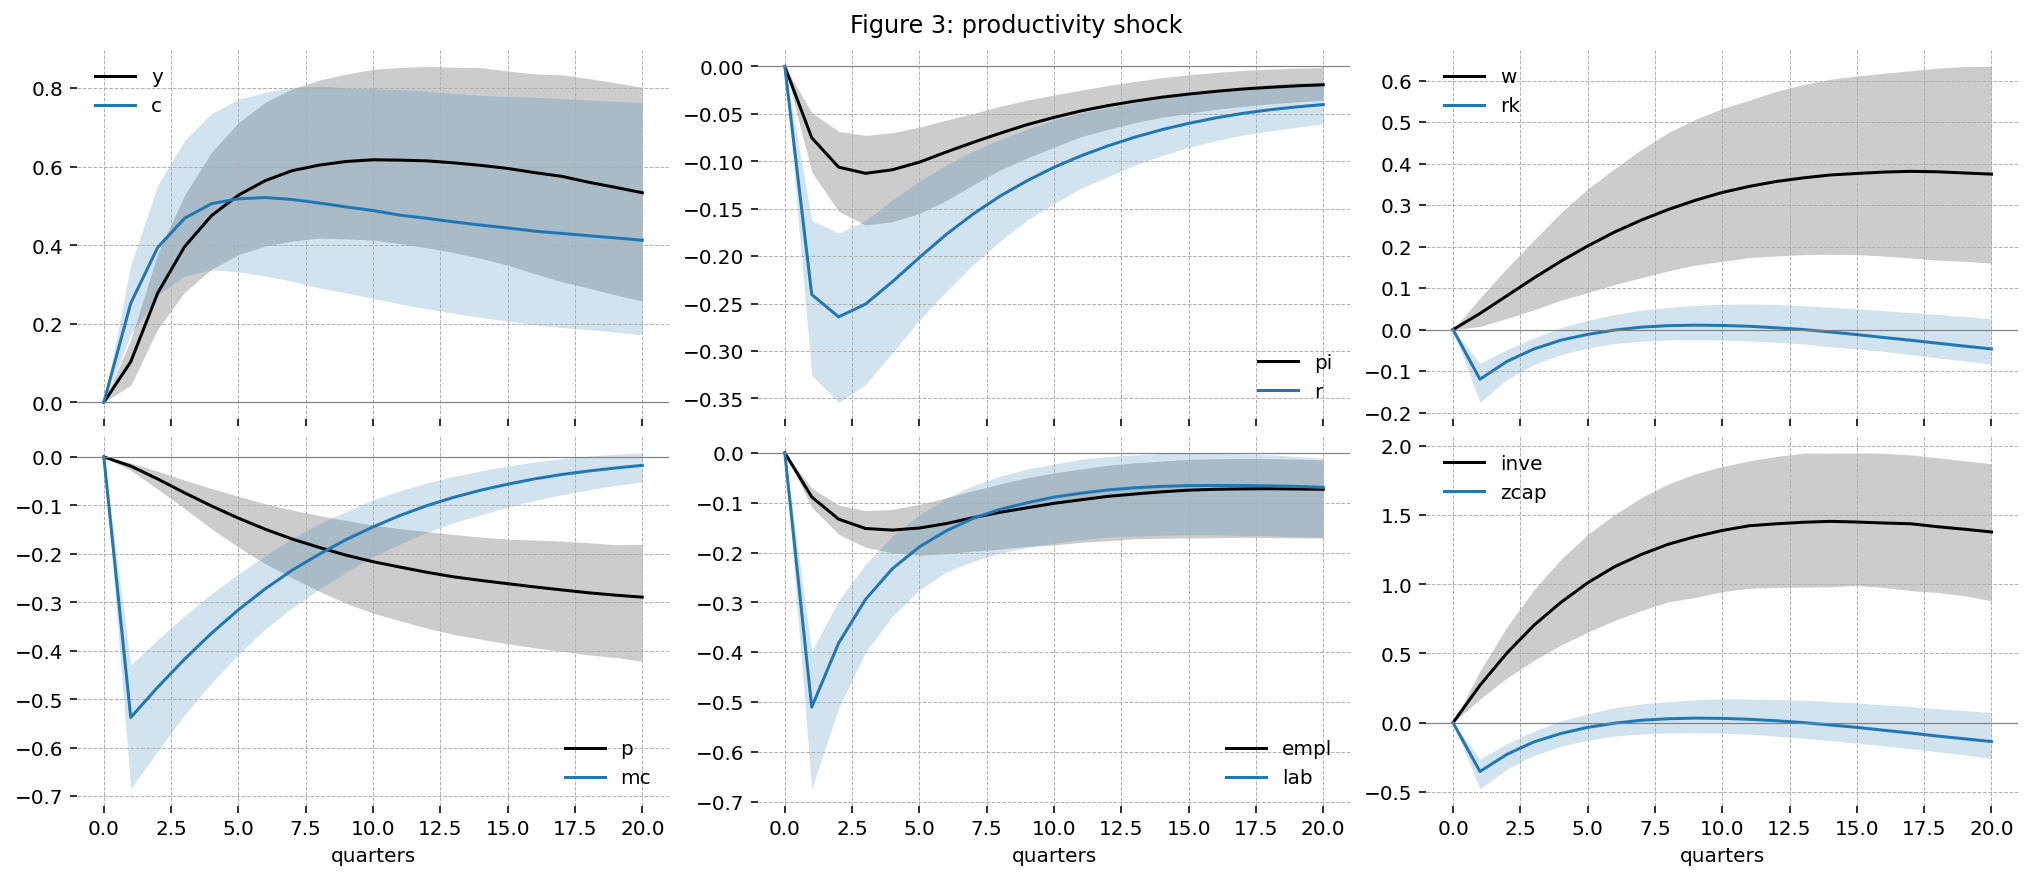

In [28]:
plot_paper_figure(paper_series(irf, "eta_a"), sticky_panels, "Figure 3: productivity shock")

### Labor supply shock

Output peaks at 0.59% and investment at 1.4%, against about 0.45% and 1.05% in Figure 4, and the price level is 0.24% lower at the end of the figure, against about 0.13%. The shock is more persistent here, at 0.95 against 0.88.

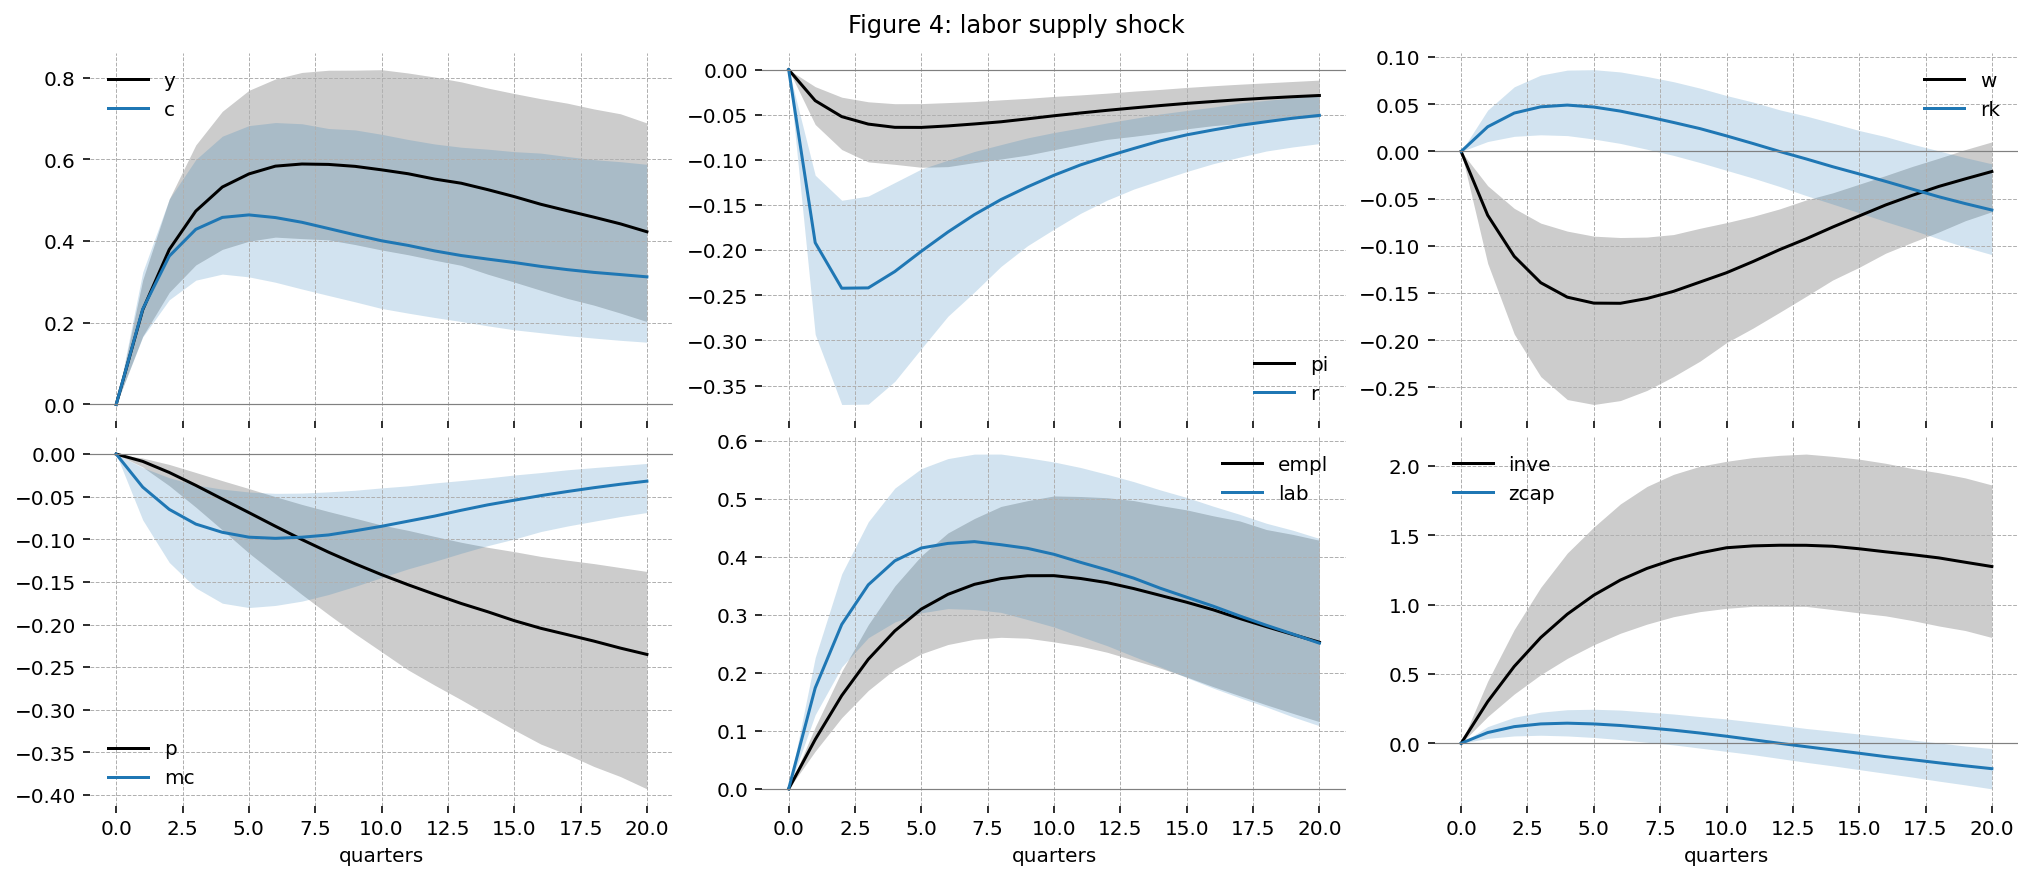

In [29]:
plot_paper_figure(paper_series(irf, "eta_L"), sticky_panels, "Figure 4: labor supply shock")

### Wage markup shock

The real wage jumps by 0.37% on impact, against about 0.5% in Figure 5, and annualized inflation rises by at most 0.04 percentage points, against about 0.1. Output rises by 0.07% on impact and turns slightly negative later, while in the paper it falls by about 0.05%.

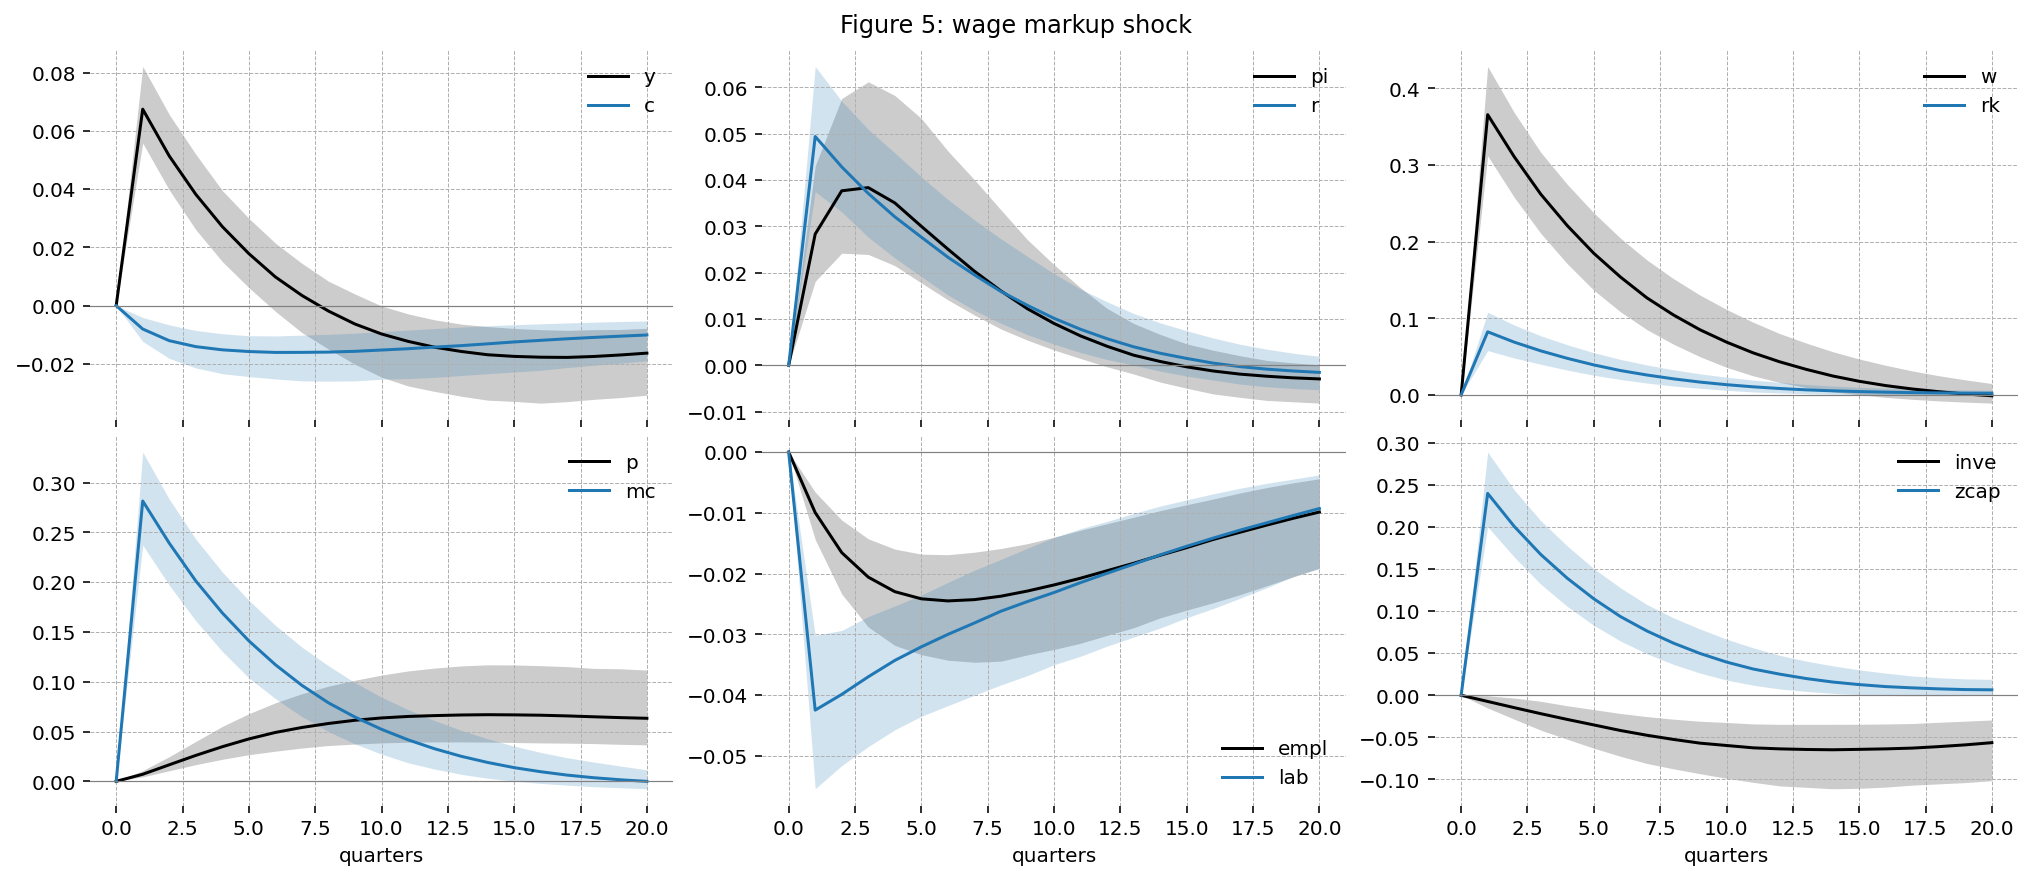

In [30]:
plot_paper_figure(paper_series(irf, "eta_w"), sticky_panels, "Figure 5: wage markup shock")

### Price markup shock

Annualized inflation jumps by 0.97 percentage points, against about 0.9 in Figure 6, and the real wage falls by 0.24%, against about 0.23%. Output falls by 0.19% at the trough, against about 0.14%.

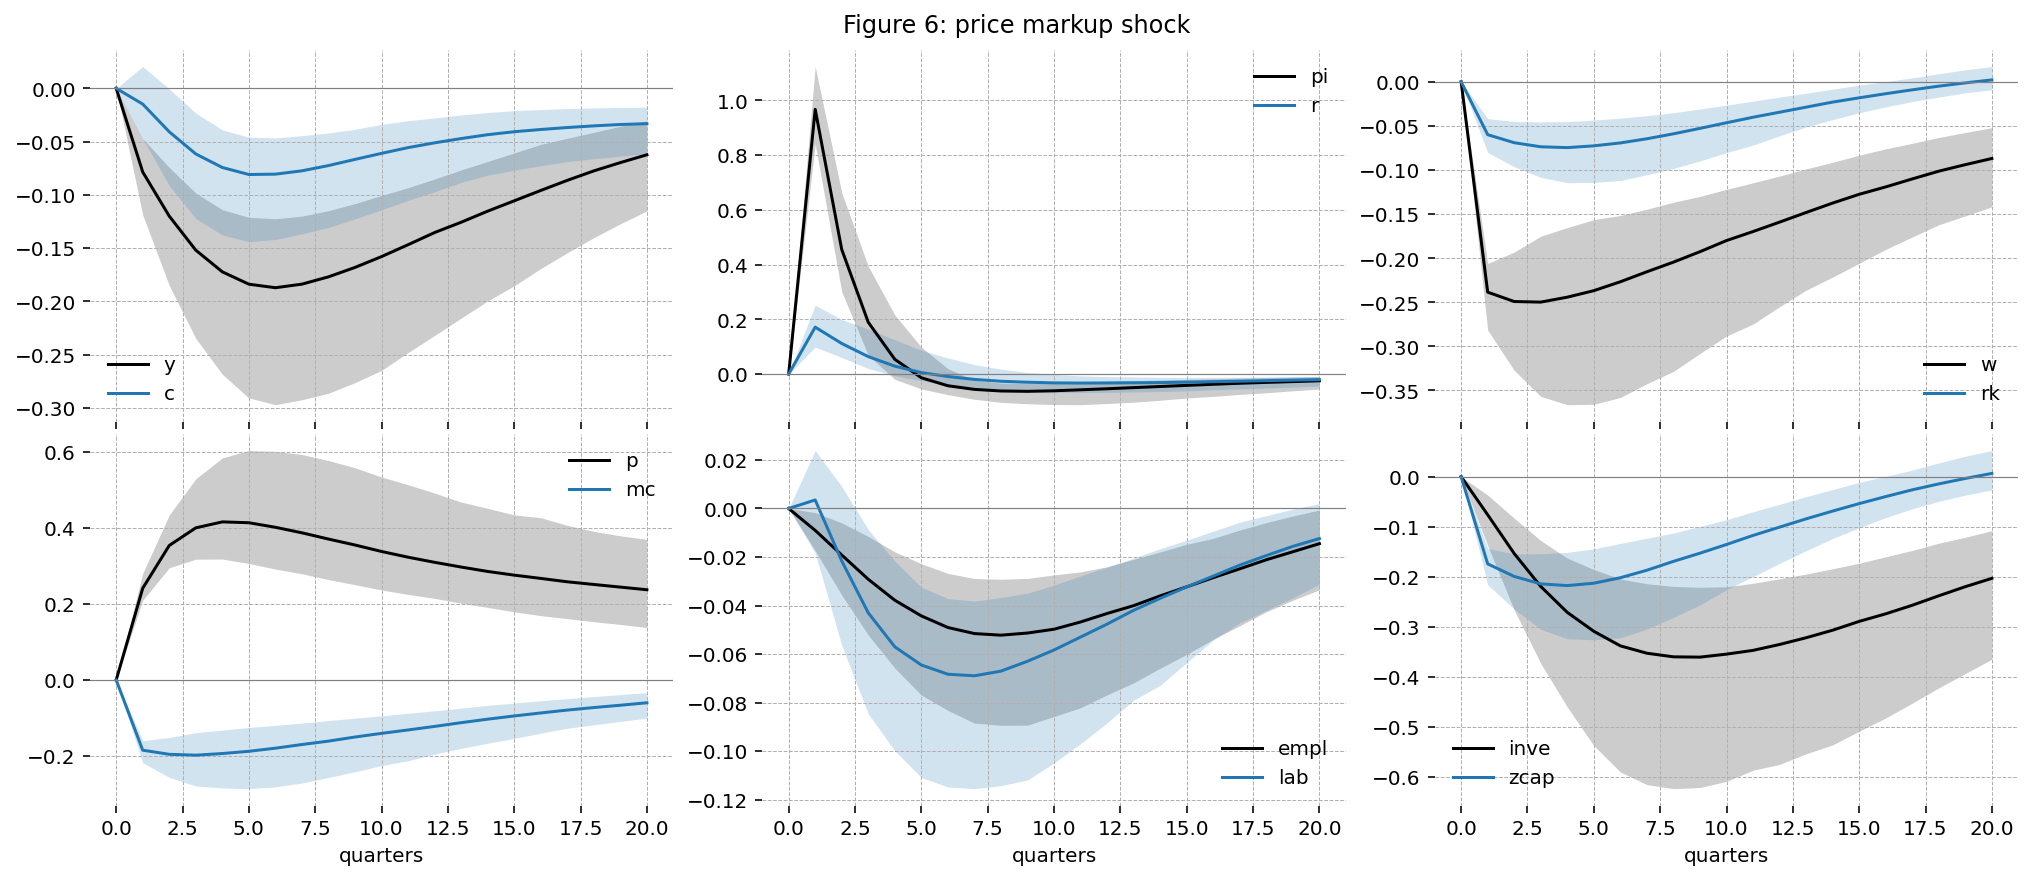

In [31]:
plot_paper_figure(paper_series(irf, "eta_p"), sticky_panels, "Figure 6: price markup shock")

### Preference shock

Consumption peaks at 0.68% and output at 0.33%, against about 0.73% and 0.3% in Figure 7, and the interest rate rises by 0.39 percentage points, against about 0.35. Investment is crowded out more than in the paper, falling by 1.2% against about 0.83%.

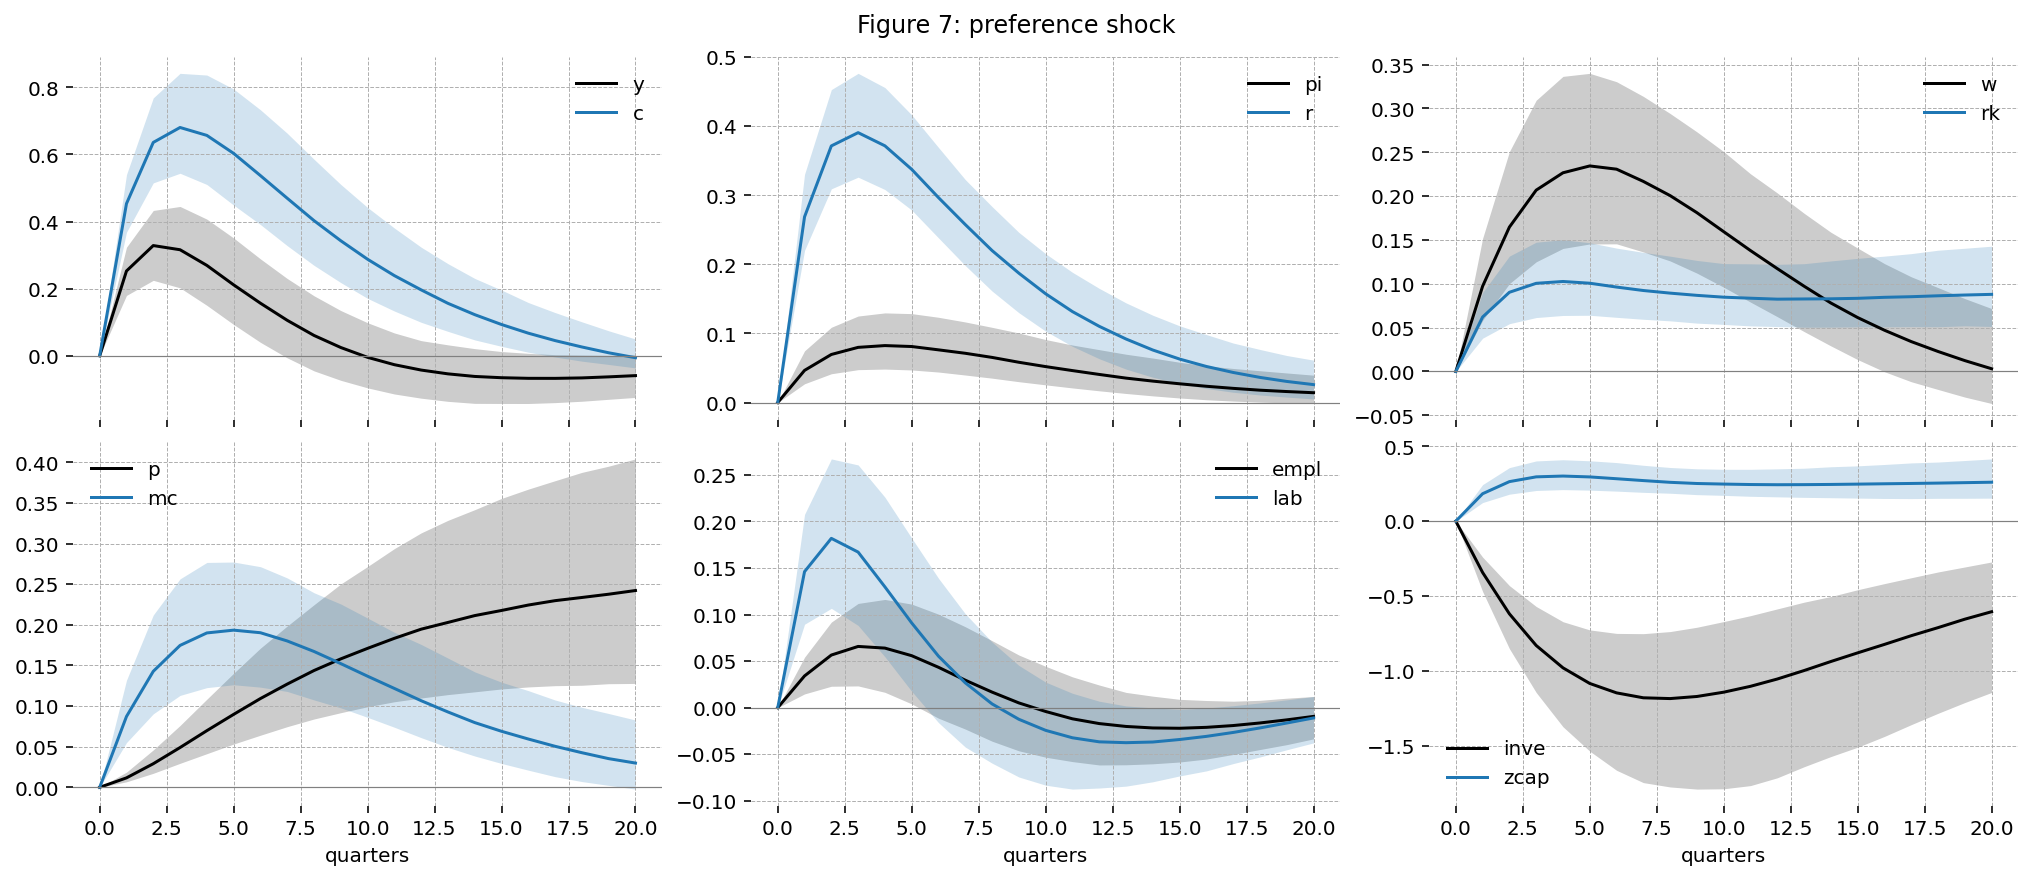

In [32]:
plot_paper_figure(paper_series(irf, "eta_b"), sticky_panels, "Figure 7: preference shock")

### Investment shock

Investment peaks at 2.1% and output at 0.37%, against about 1.55% and 0.31% in Figure 8. Consumption falls by up to 0.16%, against about 0.04%, and the price level rises by 0.21% by the end of the figure, against about 0.32%.

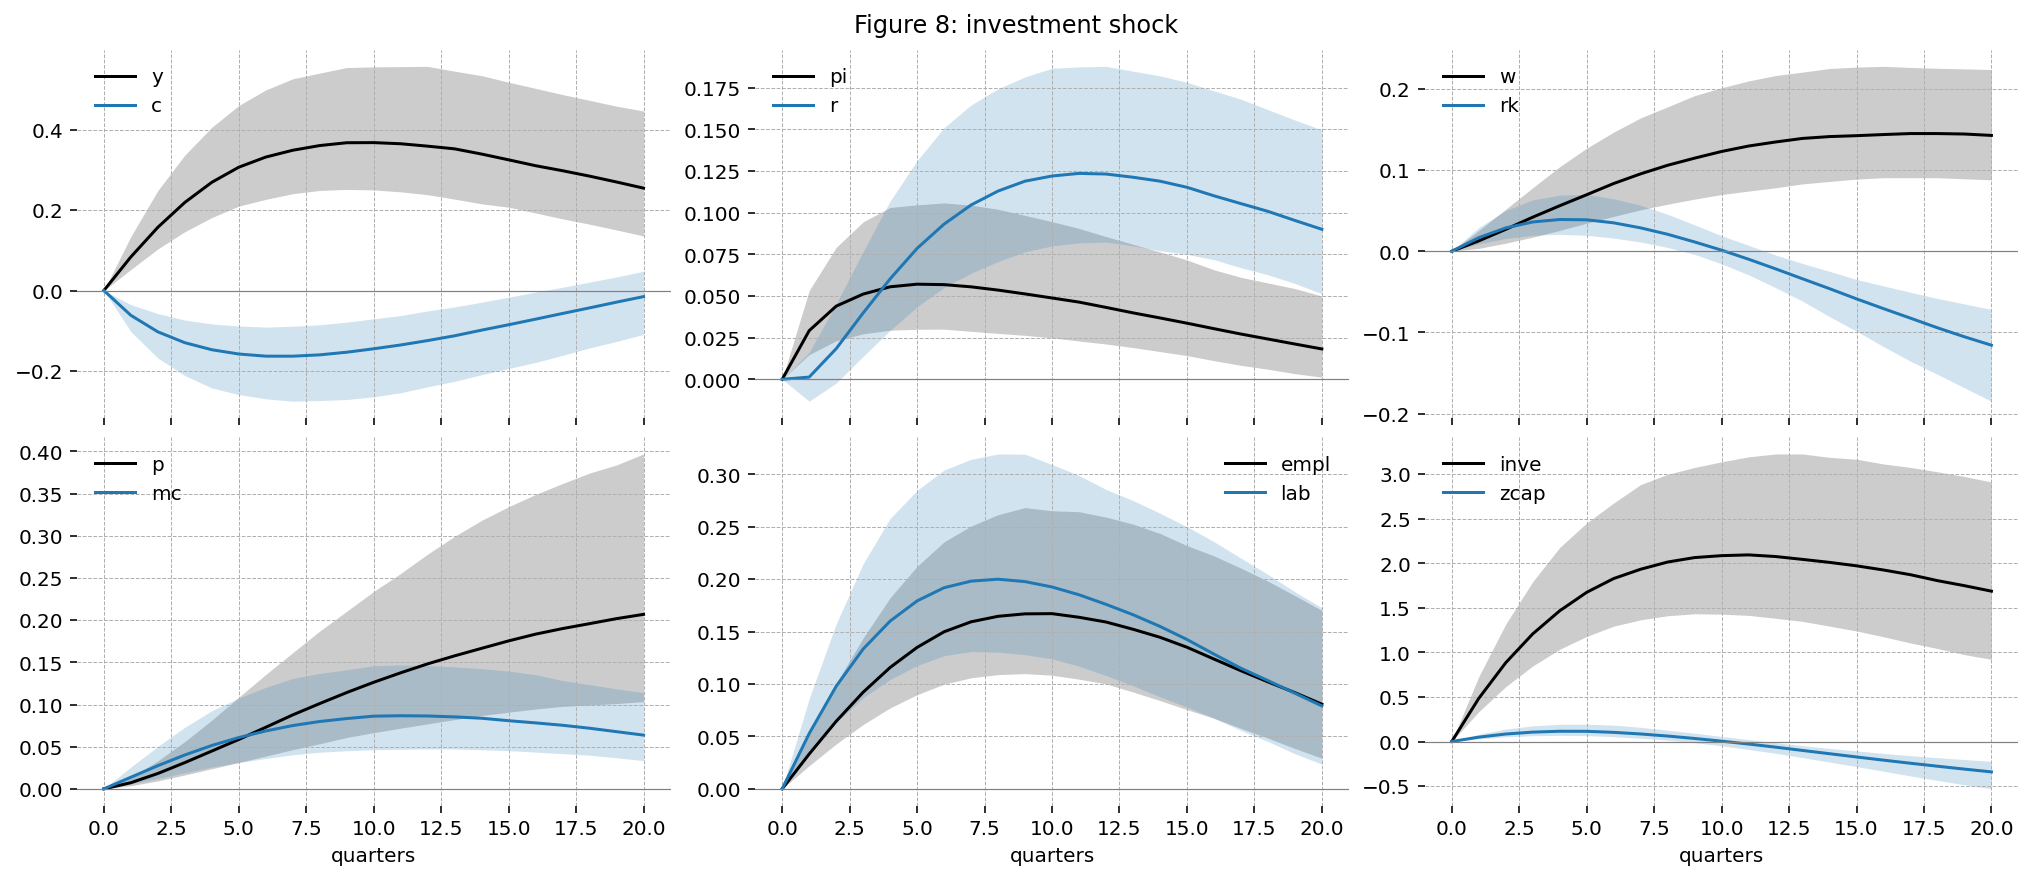

In [33]:
plot_paper_figure(paper_series(irf, "eta_I"), sticky_panels, "Figure 8: investment shock")

### Equity premium shock

Output rises by 0.25% and investment by 1.06% on impact, against about 0.21% and 1.05% in Figure 9, and both return to the steady state within the figure, as in the paper.

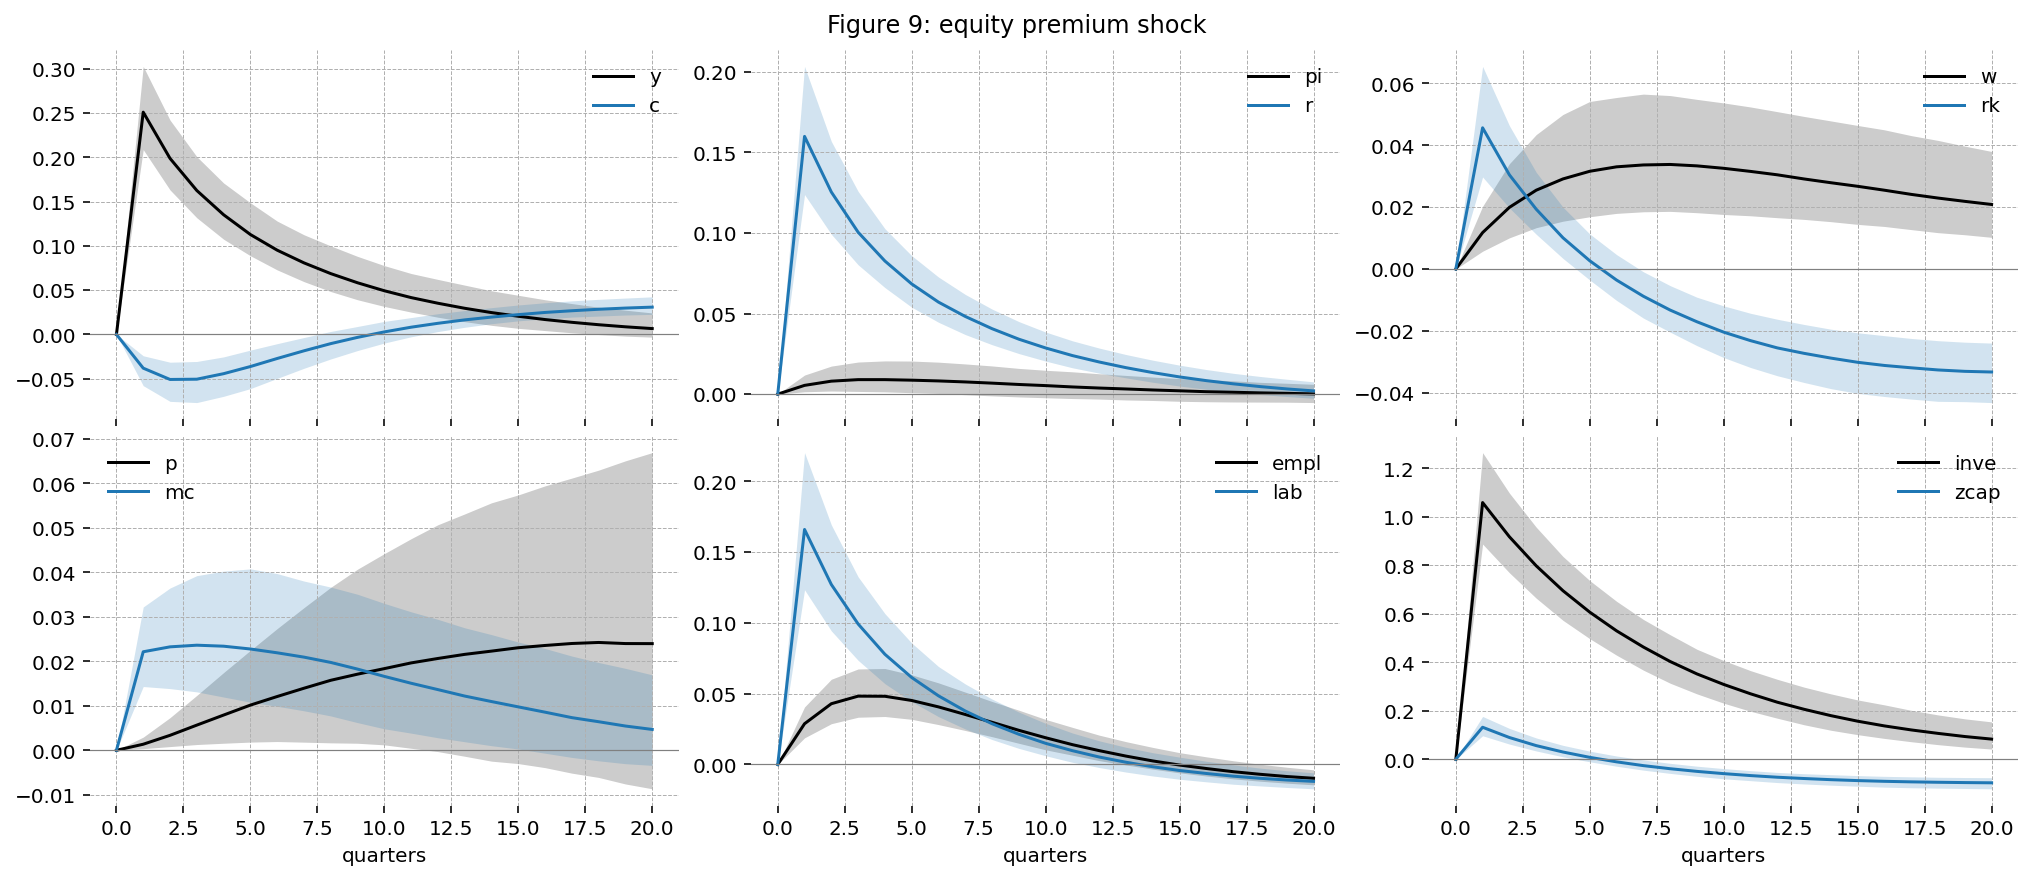

In [34]:
plot_paper_figure(paper_series(irf, "eta_Q"), sticky_panels, "Figure 9: equity premium shock")

### Government spending shock

Output rises by 0.35% on impact, against about 0.28% in Figure 10, and consumption falls by up to 0.11%, against about 0.13%. Investment is crowded out more, falling by 0.29% against about 0.17%.

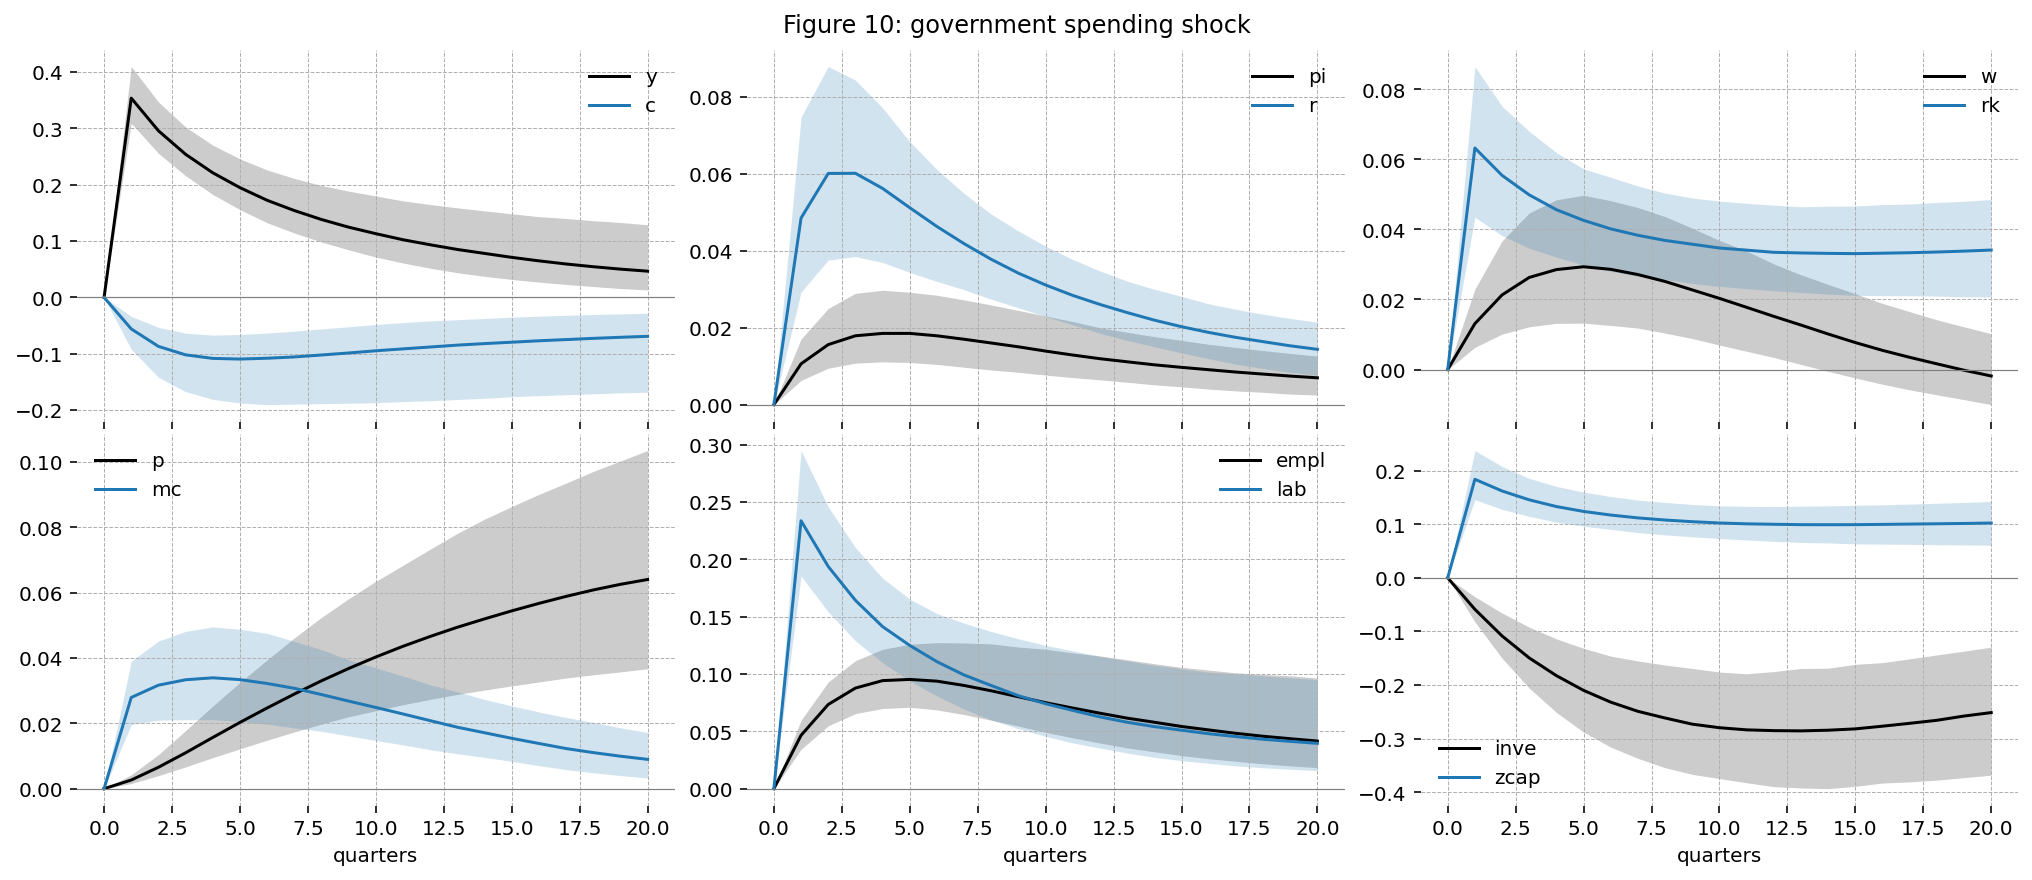

In [35]:
plot_paper_figure(paper_series(irf, "eta_G"), sticky_panels, "Figure 10: government spending shock")

### Monetary policy shock

Output falls by 0.43% at the trough four quarters after the shock, against about 0.45% a quarter later in Figure 11, and investment by 0.91% seven quarters after it, against about 1.2% at about the same time.

The rental rate of capital does not match the paper's panels, here or in Figure 3. It falls by 0.12% on impact after a productivity shock and by at most 0.11% after a monetary policy shock, against about 0.35% and 0.3% in the paper. Capacity utilization, which the code ties to it by $\hat{z}_t = \hat{r}^k_t / \psi$, falls by 0.35% and 0.32%, against about 0.45% and 0.35%. So the rental rate the paper plots is not the one that sets utilization in its code.

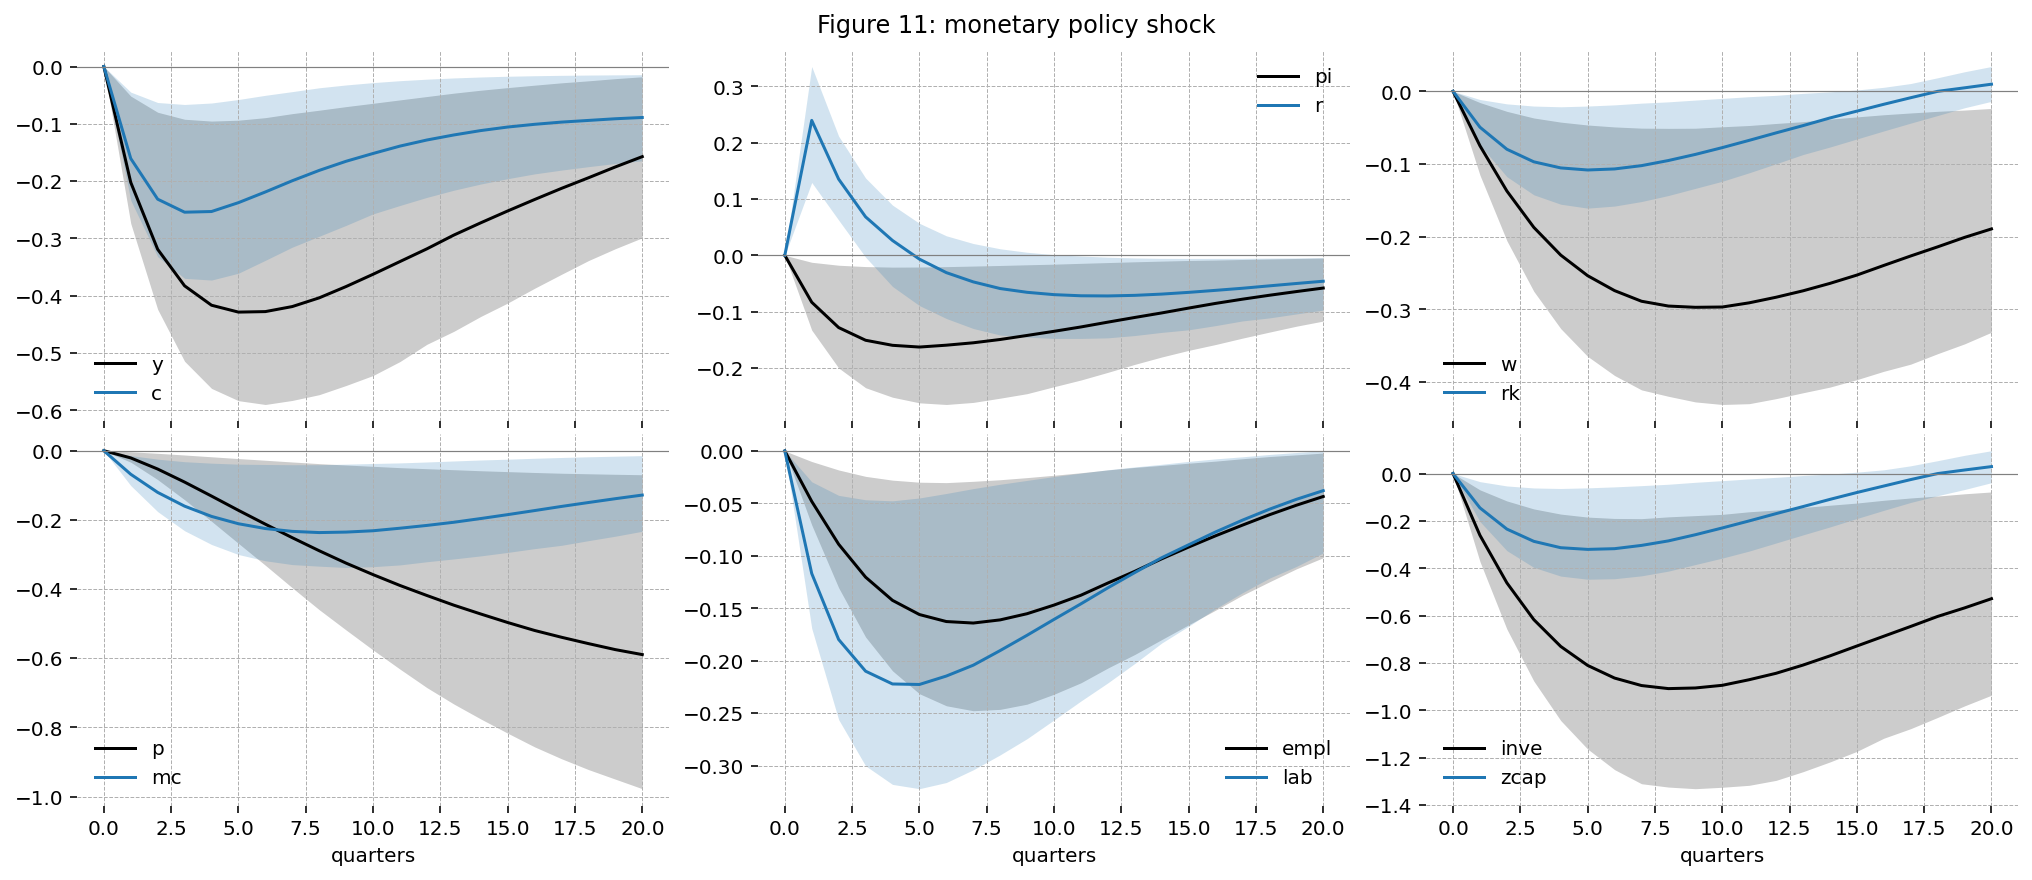

In [36]:
plot_paper_figure(paper_series(irf, "eta_R"), sticky_panels, "Figure 11: monetary policy shock")

### Inflation objective shock

The median responses are close to the paper's, with output peaking at 0.022%, against about 0.025% in Figure 12. Their 95th percentiles are far higher, at 0.88% for output and 2.1% for investment against about 0.14% and 0.39%, because the shock is large in the draws of its high mode.

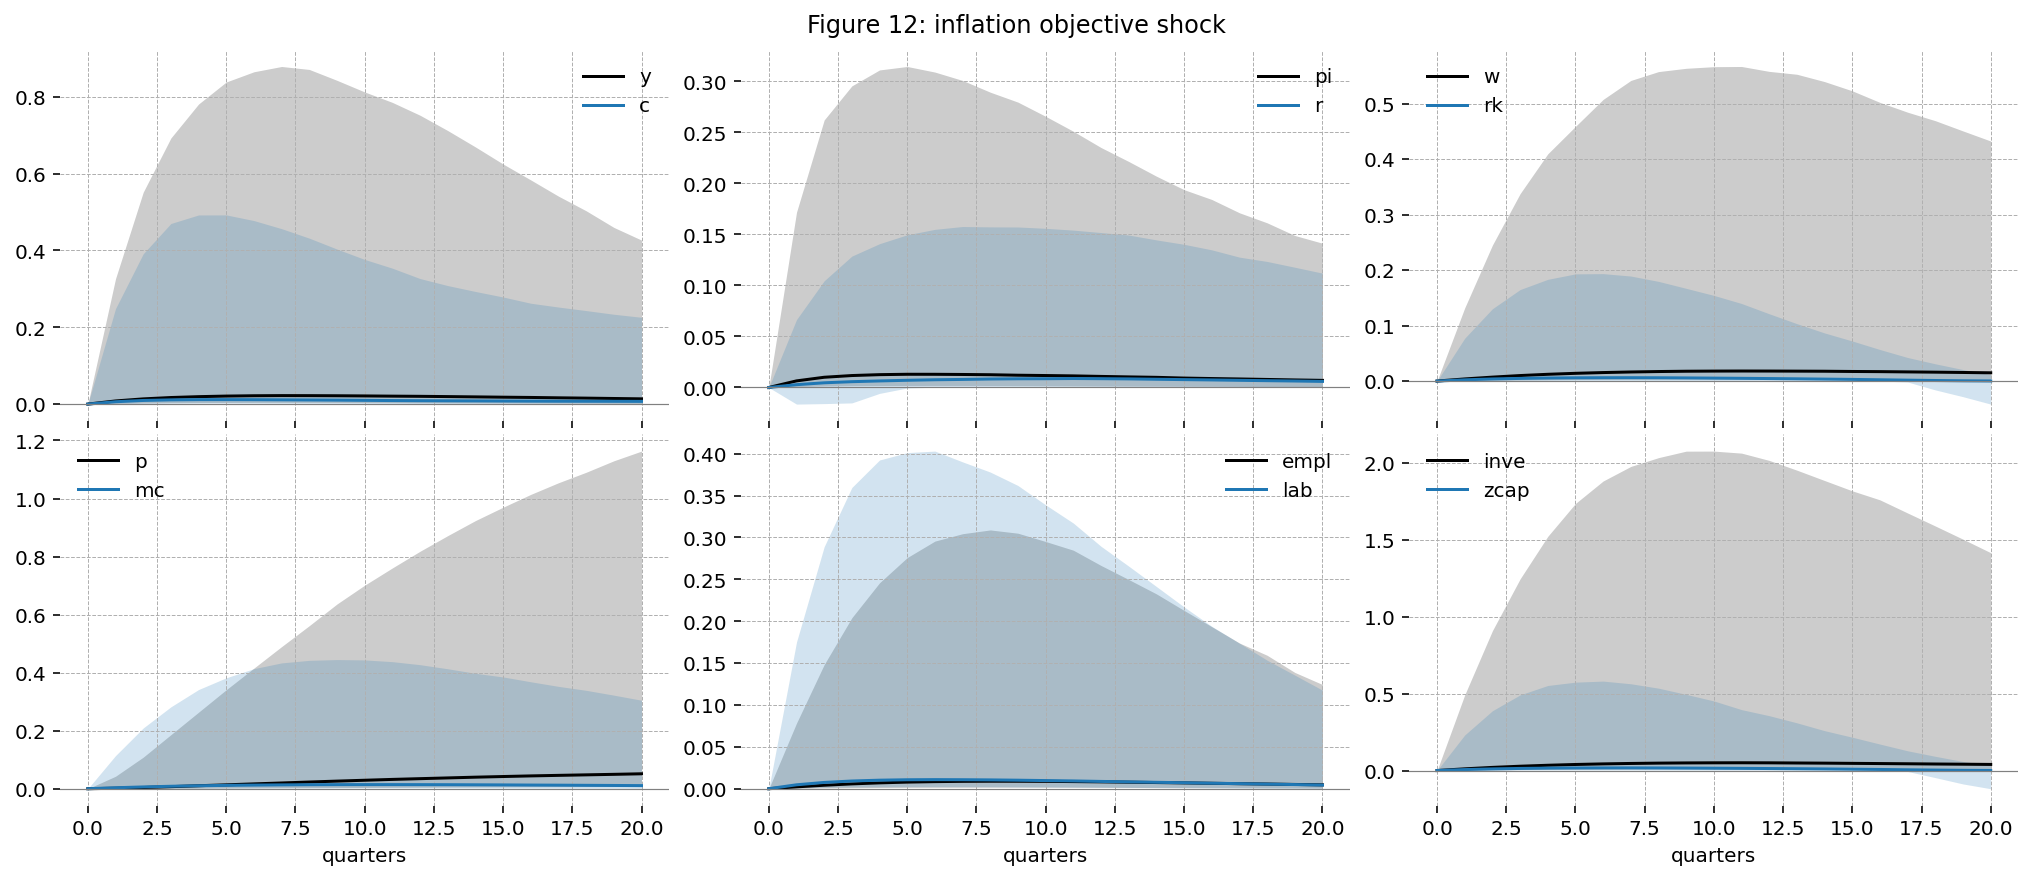

In [37]:
plot_paper_figure(paper_series(irf, "eta_pi"), sticky_panels, "Figure 12: inflation objective shock")

The figures below split the draws at a standard deviation of 0.1, the threshold used for the two modes above. The draws thin out between the modes without a clean gap, so the split is approximate. The 756 draws below it have a median standard deviation of 0.014 and the 244 above it a median of 0.58. The persistence of the shock is about the same in both, at 0.87 and 0.86, so the responses have similar shapes, and their sizes differ by roughly the ratio of the standard deviations.

In the low mode, output peaks at 0.015% seven quarters after the shock, against about 0.025% in Figure 12. In the high mode, output peaks at 0.67% five quarters after the shock and investment at 1.5%, and the price level is 0.90% higher at the end of the figure. In those draws the shock accounts for 0.28 of the forecast-error variance of output at the one-year horizon and 0.16 of that of inflation, while the paper finds that it plays no role.

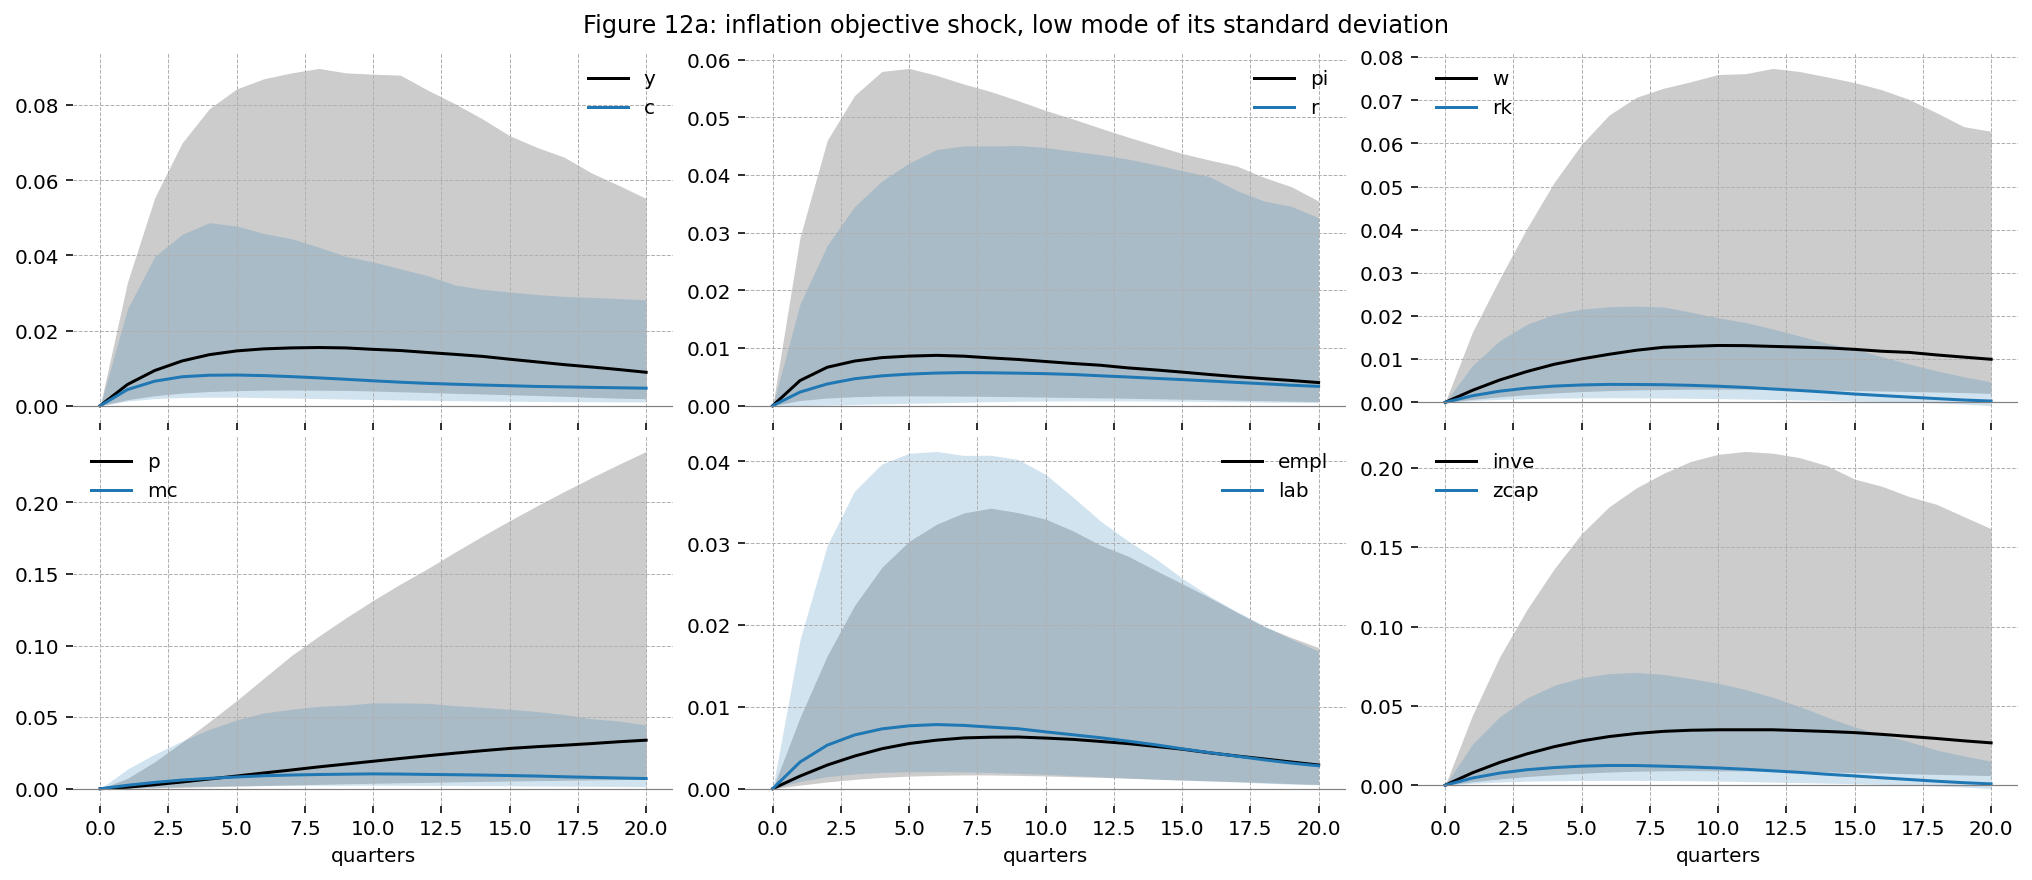

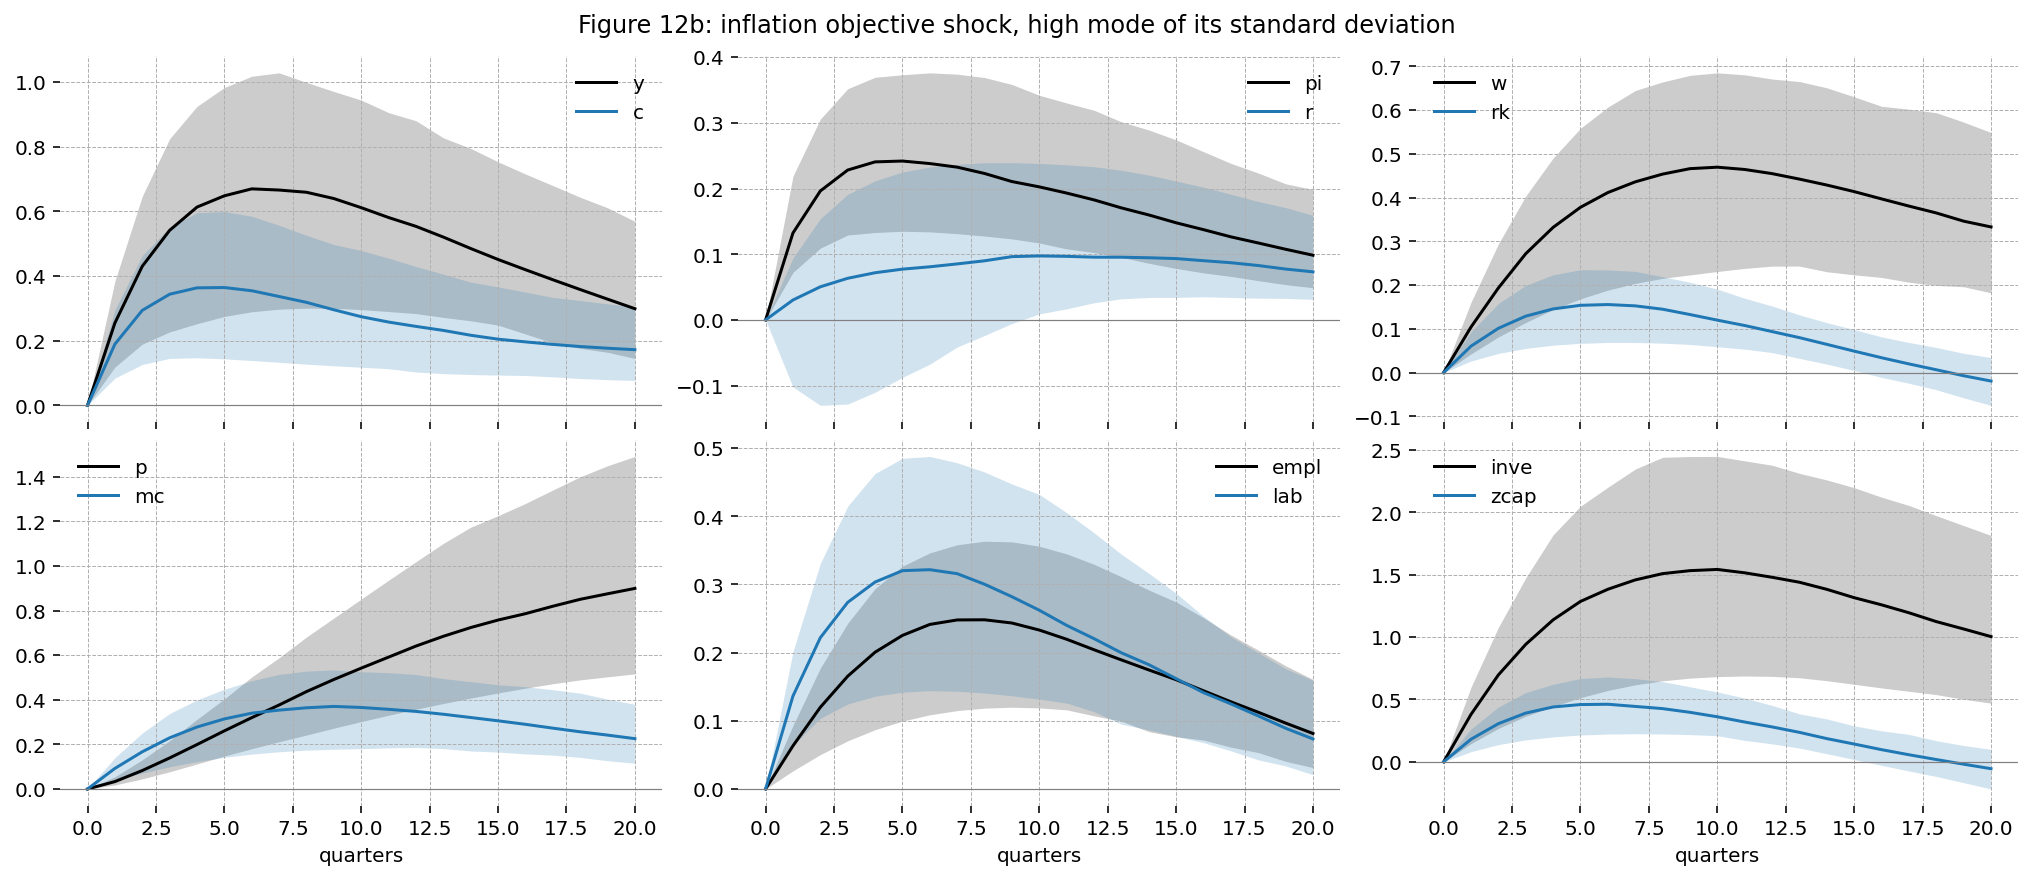

In [38]:
high_mode = posterior_draws["sigma_eta_pi"].to_numpy() > 0.1

for in_mode, mode, letter in [(~high_mode, "low", "a"), (high_mode, "high", "b")]:
    plot_paper_figure(
        paper_series(irf.isel(draw=in_mode), "eta_pi"),
        sticky_panels,
        f"Figure 12{letter}: inflation objective shock, {mode} mode of its standard deviation",
    )

## Impulse responses of the flexible economy

Figures 15 to 19 of the paper show how the flexible economy responds to the five shocks that hit it. Prices and wages move freely, so marginal cost stays at its steady state, and the price level is stabilized, so the paper plots no inflation or price level. The interest rate is the natural real rate, annualized.

In [39]:
flexible_panels = [("y", "c"), ("r",), ("w", "rk"), ("mc",), ("lab",), ("inve", "zcap")]

### Productivity shock, flexible economy

Output rises by 0.77% at the peak, four quarters after the shock, against about 0.65% two to three quarters after it in Figure 15. The real wage jumps by 0.72%, against about 0.87%, and hours fall by 0.44% on impact, against about 0.48%. The natural real rate falls by 1.7 percentage points on impact, half of the 3.4 in the paper, and the rental rate rises by at most 0.11%, against about 0.3%. Marginal cost stays at the steady state, up to roundoff of order $10^{-14}$, as it does in the paper up to roundoff of order $10^{-16}$.

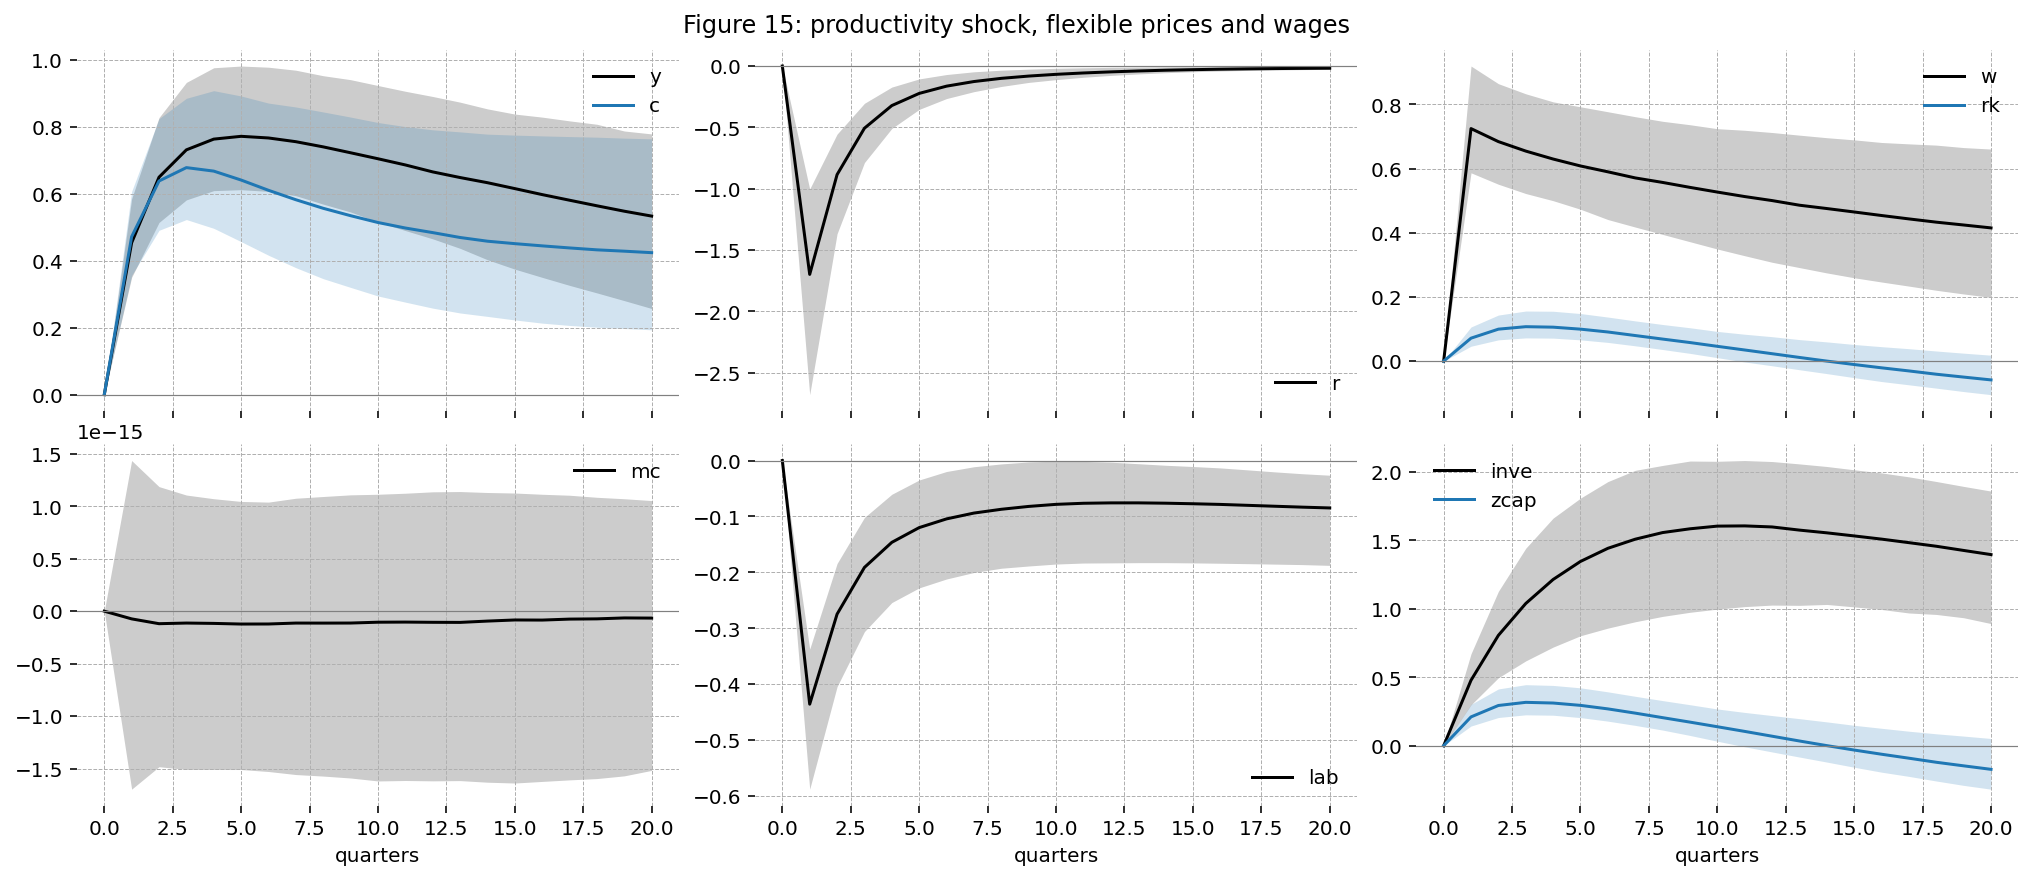

In [40]:
plot_paper_figure(
    paper_series(irf, "eta_a", suffix="_f"), flexible_panels, "Figure 15: productivity shock, flexible prices and wages"
)

### Labor supply shock, flexible economy

Output peaks at 0.86%, against about 0.9% in Figure 16, and the real wage barely moves, as in the paper. The natural real rate falls by 2.1 percentage points on impact, against about 3.3.

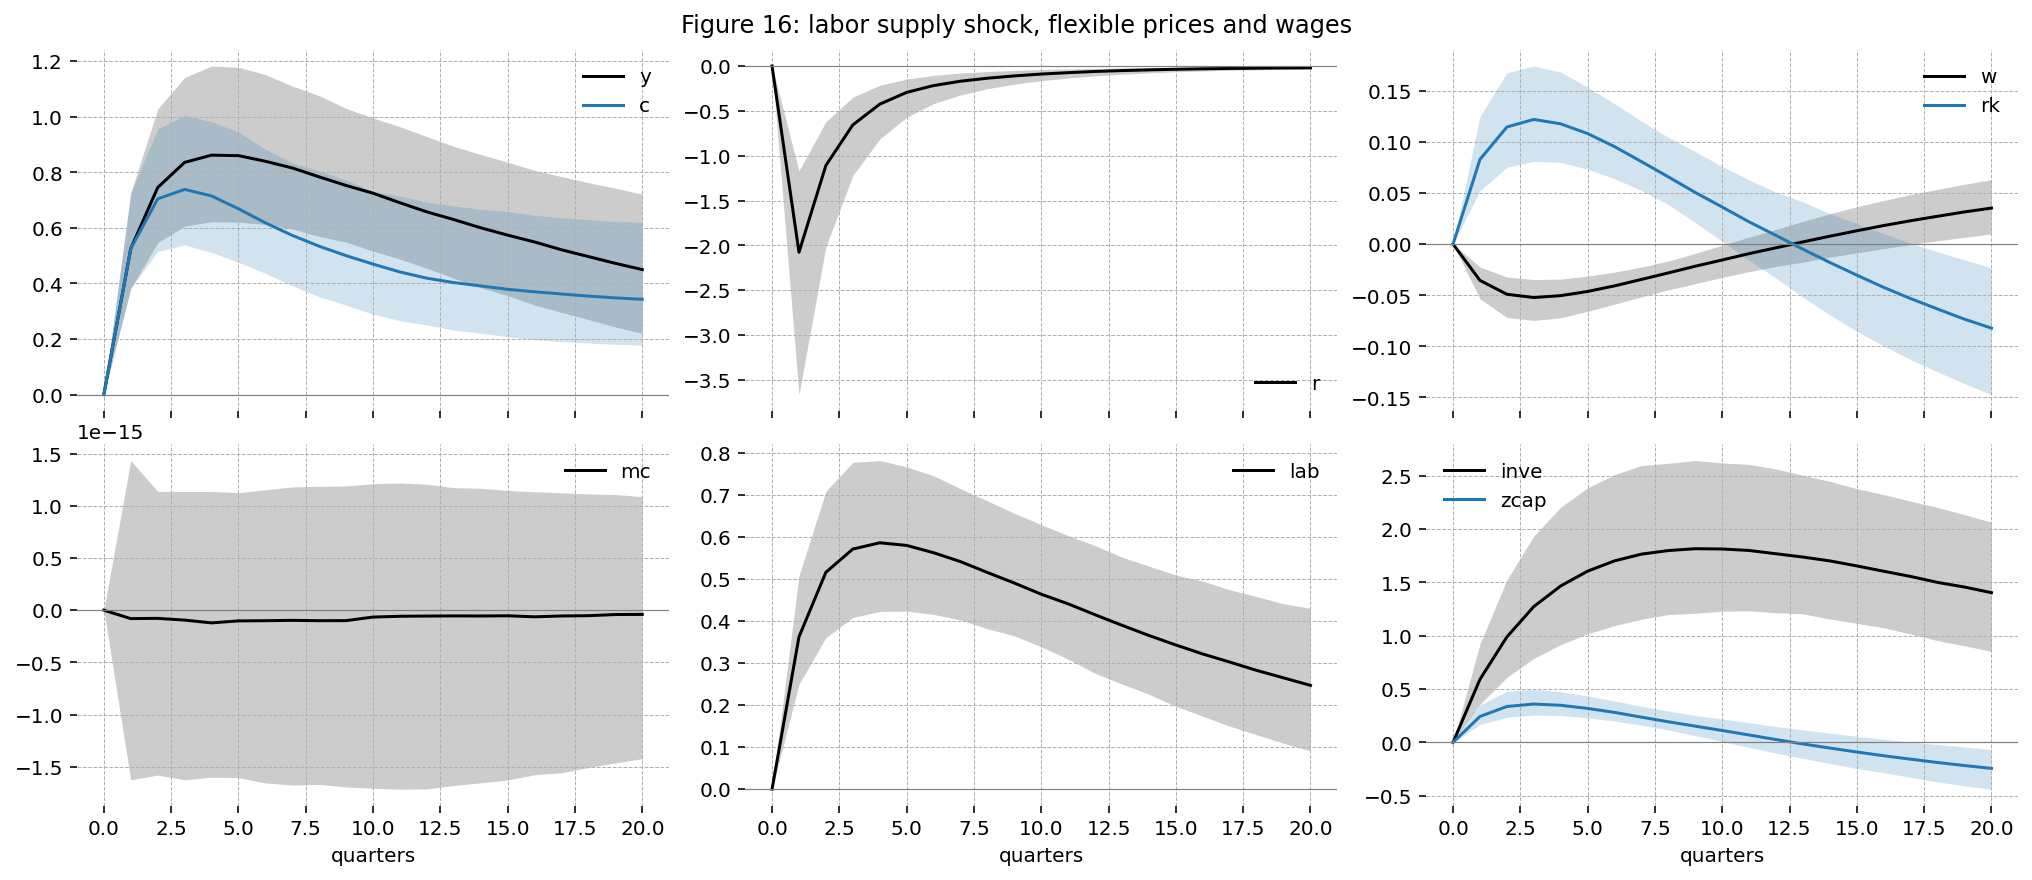

In [41]:
plot_paper_figure(
    paper_series(irf, "eta_L", suffix="_f"), flexible_panels, "Figure 16: labor supply shock, flexible prices and wages"
)

### Preference shock, flexible economy

Output falls by 0.29% and investment by 2.0% at the trough, against about 0.25% and 2.2% in Figure 17, while consumption rises by up to 0.27%, against about 0.33%. The natural real rate rises by 2.0 percentage points on impact, against about 2.1.

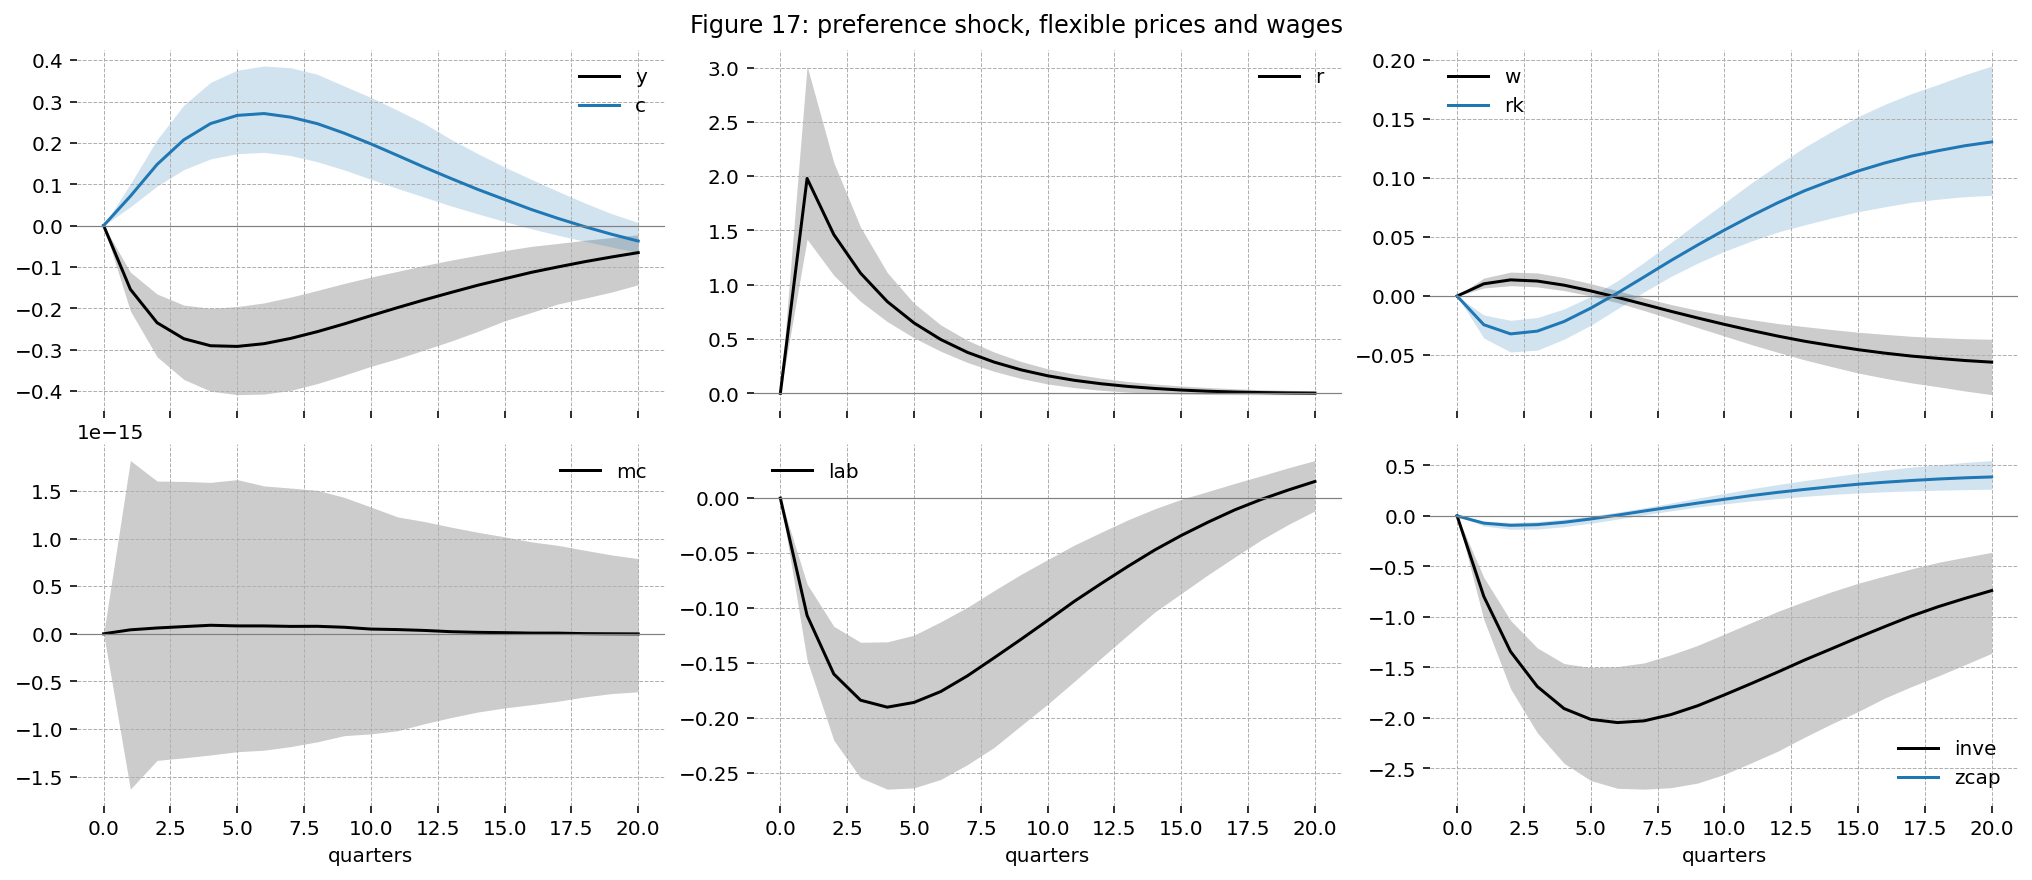

In [42]:
plot_paper_figure(
    paper_series(irf, "eta_b", suffix="_f"), flexible_panels, "Figure 17: preference shock, flexible prices and wages"
)

### Investment shock, flexible economy

Output peaks at 0.24% and investment at 1.8%, against about 0.19% and 1.55% in Figure 18, and consumption falls by up to 0.22%, against about 0.23%. The natural real rate falls by 0.36 percentage points on impact, against about 0.35.

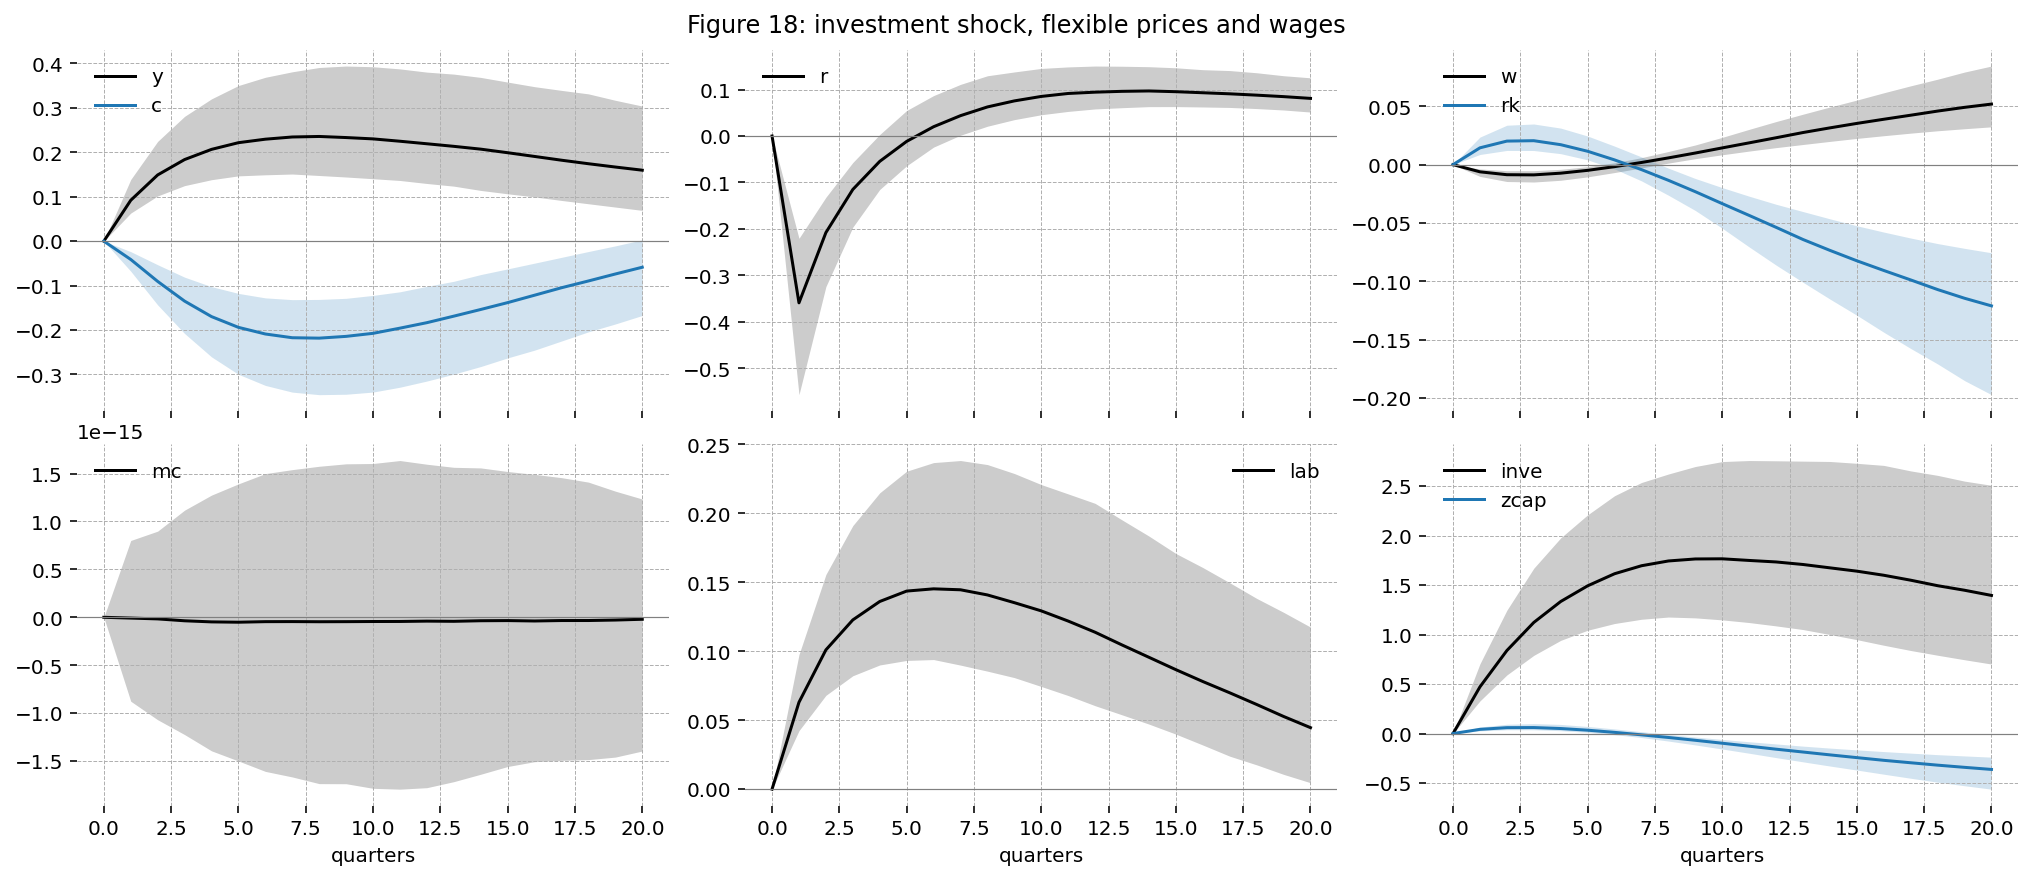

In [43]:
plot_paper_figure(
    paper_series(irf, "eta_I", suffix="_f"), flexible_panels, "Figure 18: investment shock, flexible prices and wages"
)

### Government spending shock, flexible economy

Output rises by 0.28% on impact and the natural real rate by 0.49 percentage points, against about 0.22% and 0.48 in Figure 19. Consumption falls by up to 0.18%, against about 0.17%, and investment by up to 0.38%, against about 0.46%.

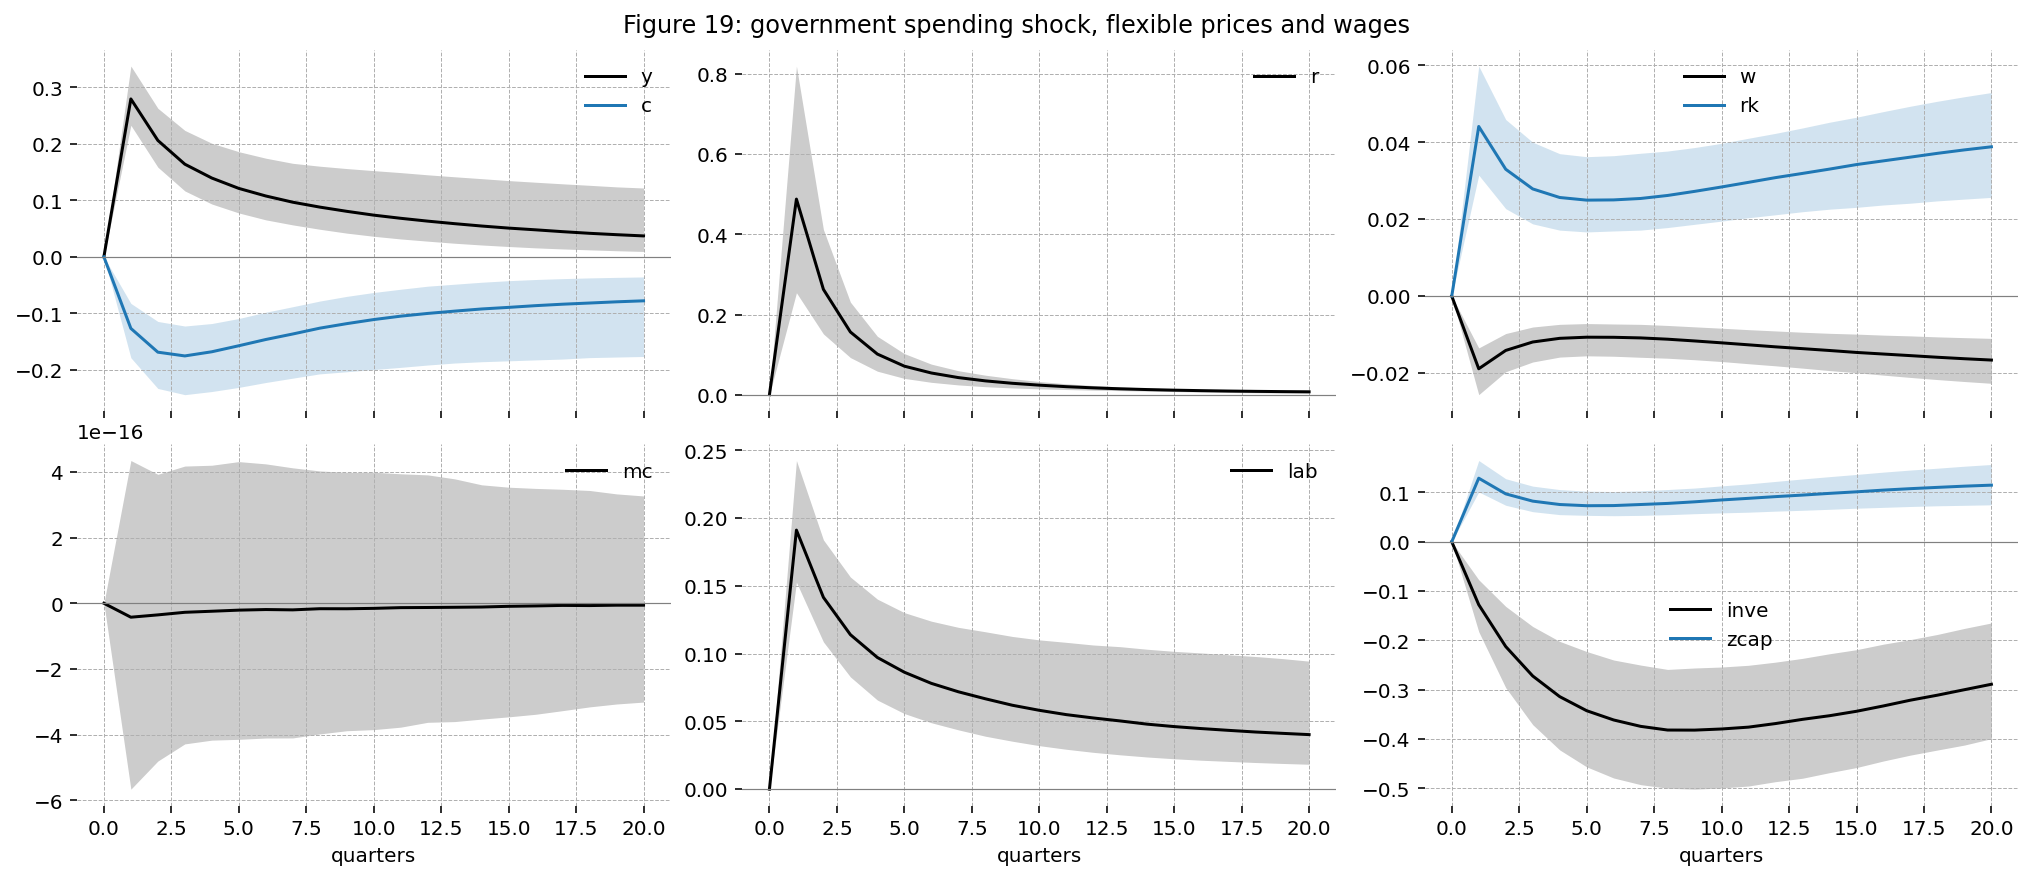

In [44]:
plot_paper_figure(
    paper_series(irf, "eta_G", suffix="_f"),
    flexible_panels,
    "Figure 19: government spending shock, flexible prices and wages",
)

# References

```{bibliography}
```

# Authors

- Created by Jesse Grabowski, October 28, 2026

# Watermark

In [45]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Fri, 30 Oct 2026

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.14.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

arviz     : 1.3.0
gEconpy   : 2.2.1.dev2+gaf033cd43
matplotlib: 3.10.9
numpy     : 2.4.6
pandas    : 3.0.3
preliz    : 0.28.0
pymc      : 6.3.2
pytensor  : 3.3.5
xarray    : 2026.4.0

Watermark: 2.6.0

